# Segmentación de clientes e-commerce y predicción de churn
**Grupo 5 · Diplomatura en Ciencia de Datos y Análisis Avanzado (UTN BA)**

- Dataset: Online Retail II (UCI Machine Learning Repository)
- Metodología: CRISP-DM
- **Parte A (Fase 1):** segmentación con RFM + K-Means → *¿quiénes son los clientes?*
- **Parte B (Fase 2):** predicción de churn (baselines: regla por Recencia y regresión logística, contra XGBoost) → *¿a quién contactar primero?*

**Decisiones de diseño (fijadas antes de modelar):**

| Decisión | Valor |
|---|---|
| Fecha de predicción (en la jerga técnica, «fecha de corte»; una sola para las dos fases) | 01/09/2011 |
| Ventana para describir al cliente (RFM y variables) | 12 meses: 01/09/2010 al 31/08/2011 |
| Ventana de la etiqueta de churn (Fase 2) | 3 meses: septiembre, octubre y noviembre de 2011 |
| Semilla aleatoria | `RANDOM_STATE = 42` |

> **Cómo usar este cuaderno:** se ejecuta de arriba hacia abajo (*Entorno de ejecución → Ejecutar todas*). Funciona en Google Colab y en una PC local. Si el archivo `online_retail_II.csv` no está en la carpeta `Dataset/` (o junto al cuaderno), se descarga automáticamente desde UCI.

> **Relación con el informe:** este cuaderno es la fuente de todas las cifras, tablas y figuras del informe final. Al final hay un *mapa informe ↔ cuaderno* y una celda de control que compara las cifras del informe con las que salen del código. Las figuras llevan el mismo número que en el informe (las marcadas `C` son complementarias y no están en el informe).


## Etapa 0 · Preparación del entorno
Antes de tocar los datos: traer las librerías, fijar los parámetros del proyecto y cargar el archivo.

**Por qué los parámetros van en una sola celda:** todas las decisiones (fecha de predicción, ventanas, semilla) quedan en un único lugar. Si mañana cambiamos la fecha de predicción, se modifica una línea y todo el cuaderno se recalcula de forma coherente.

In [1]:
# ── Librerías ──
import os                                   # Para crear carpetas y verificar si un archivo existe
import numpy as np                          # Cálculos numéricos (logaritmos, percentiles, etc.)
import pandas as pd                         # Tablas de datos (DataFrames); "pd" es su apodo
import matplotlib.pyplot as plt             # Gráficos
from matplotlib.ticker import FuncFormatter # Para dar formato a los números de los ejes
from scipy.stats import skew                # Mide la asimetría de una distribución (0 = simétrica)

# ── Parámetros del proyecto: todas las decisiones en un solo lugar ──
RANDOM_STATE   = 42                                          # Semilla fija: lo "aleatorio" sale igual en cada ejecución
FECHA_PREDICCION    = pd.Timestamp("2011-09-01")                  # Fecha de predicción: todo lo que se calcula usa datos ANTERIORES a esta fecha
INICIO_VENTANA = FECHA_PREDICCION - pd.DateOffset(months=12)      # 01/09/2010: inicio de los 12 meses que describen al cliente
FIN_ETIQUETA   = FECHA_PREDICCION + pd.DateOffset(months=3)       # 01/12/2011: fin de los 3 meses que usa la etiqueta de churn

# ── Carpetas de salida (rutas relativas: funcionan en Colab y en la PC) ──
os.makedirs("figures", exist_ok=True)       # Acá se guardan los gráficos que van al informe
os.makedirs("results", exist_ok=True)       # Acá se guardan las tablas de resultados

# ── Estilo común para todos los gráficos ──
AZUL, NARANJA, GRIS, TINTA = "#2F5D8A", "#B4501A", "#A8A49C", "#1F1E1B"   # Paleta fija del informe
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",      # Resolución en pantalla y al guardar
    "font.family": "sans-serif", "font.size": 11,                         # Fuente sans serif, como pide la consigna
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,                 # Sin bordes superiores ni derechos
    "axes.grid": True, "grid.color": "#E6E3DC", "grid.linewidth": 0.8,    # Grilla suave, que no compite con los datos
    "axes.axisbelow": True, "axes.edgecolor": "#8A8780", "text.color": TINTA,
})
miles = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))      # Formato 1.234.567 (separador de miles argentino)

print("Fecha de predicción:", FECHA_PREDICCION.date())
print("Ventana para describir al cliente:", INICIO_VENTANA.date(), "→", (FECHA_PREDICCION - pd.Timedelta(days=1)).date())
print("Ventana de la etiqueta de churn:  ", FECHA_PREDICCION.date(), "→", (FIN_ETIQUETA - pd.Timedelta(days=1)).date())

Fecha de predicción: 2011-09-01
Ventana para describir al cliente: 2010-09-01 → 2011-08-31
Ventana de la etiqueta de churn:   2011-09-01 → 2011-11-30


In [2]:
# ── Carga del dataset ──
# Se busca el archivo en las carpetas habituales; si no está, se descarga del repositorio oficial de UCI.
RUTAS_POSIBLES = ["Dataset/online_retail_II.csv", "../Dataset/online_retail_II.csv",   # Carpeta del proyecto o la carpeta de arriba
                  "online_retail_II.csv", "data/online_retail_II.csv"]                 # Junto al cuaderno (por ejemplo, subido a Colab)
ruta = next((r for r in RUTAS_POSIBLES if os.path.exists(r)), None)   # Primera ruta que exista (o None)

if ruta is not None:
    # dtype=str en Invoice y StockCode: son códigos, no números (algunos tienen letras, como "C489449" o "POST")
    df_raw = pd.read_csv(ruta, dtype={"Invoice": str, "StockCode": str})
    print("Archivo leído desde:", ruta)
else:
    # Descarga oficial: un .zip con un Excel de dos hojas (2009-2010 y 2010-2011). Requiere internet y openpyxl.
    import io, zipfile, urllib.request
    URL = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
    contenido = urllib.request.urlopen(URL).read()                      # Baja el .zip a memoria
    with zipfile.ZipFile(io.BytesIO(contenido)) as z:
        nombre = [n for n in z.namelist() if n.endswith(".xlsx")][0]    # Busca el Excel dentro del .zip
        hojas = pd.read_excel(io.BytesIO(z.read(nombre)), sheet_name=None,
                              dtype={"Invoice": str, "StockCode": str})  # sheet_name=None lee TODAS las hojas
    df_raw = pd.concat(hojas.values(), ignore_index=True)               # Une las dos hojas en una sola tabla
    os.makedirs("Dataset", exist_ok=True)
    df_raw.to_csv("Dataset/online_retail_II.csv", index=False)          # Lo guarda para no descargarlo otra vez
    print("Archivo descargado de UCI y guardado en Dataset/")

df_raw["InvoiceDate"] = pd.to_datetime(df_raw["InvoiceDate"])           # Convierte el texto de la fecha en fecha real
print("Filas y columnas:", df_raw.shape)
df_raw.head()

Archivo leído desde: Dataset/online_retail_II.csv
Filas y columnas: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## Etapa 1 · Comprensión del negocio
**Fase CRISP-DM: 1 – Comprensión del negocio.** (Es el mismo contenido que la sección 2 del informe.)

1. **Problema y contexto.** Una tienda británica de comercio electrónico, con clientes mayoristas y minoristas, no tiene un sistema para diferenciar el valor de sus clientes. Las campañas se envían de forma genérica a toda la base: gastan presupuesto en clientes de bajo valor o ya perdidos y dejan sin atención específica a los valiosos que empiezan a alejarse. El valor está muy concentrado (el 10 % de los clientes genera el 63,9 % de la facturación; lo comprobamos en la sección 3.2), así que tratar a todos igual es ineficiente.
2. **Objetivo 1 (Parte A, segmentar).** Se mide el Silhouette, la cantidad de segmentos y la comparación con la segmentación por quintiles RFM. Meta de referencia: Silhouette mayor a 0,45 y mayor que el de los quintiles, con al menos cuatro segmentos interpretables.
3. **Objetivo 2 (Parte A, estabilidad).** Se miden el Silhouette y la inercia en el 20 % de prueba. Meta: que la diferencia con el 80 % de ajuste no supere el 10 %.
4. **Objetivo 3 (Parte B, predecir el abandono).** Se miden Recall, ROC-AUC y PR-AUC, y el porcentaje de abandonos detectados al contactar al 20 % de clientes con mayor riesgo. Se busca superar a la regla por Recencia (sin modelo) en PR-AUC y en ese porcentaje.
5. **Objetivo 4 (acciones).** Cada segmento tiene un perfil y una acción comercial recomendada, y existe una lista de clientes ordenada por riesgo.
6. **KPIs de impacto (son metas, no resultados medidos).** +15 % en la tasa de conversión de campañas, +10 % en el valor de vida del cliente (LTV) a 6 meses y +10 % en el retorno publicitario (ROAS). El dataset no tiene datos de campañas, así que estas metas solo pueden validarse con un piloto.
7. **Hipótesis de trabajo.** (a) Existen al menos cuatro arquetipos de cliente (VIP, Leales, En riesgo, Nuevos / bajo valor). (b) K-Means separa mejor que los quintiles RFM. (c) El modelo de churn ordena a los clientes por riesgo mejor que la regla por Recencia.
8. **Restricciones.** Dataset público de 2009 a 2011, sin datos de campañas; el 91 % de los clientes es del Reino Unido; una sola fecha de predicción; el Customer ID se reemplaza por un código aleatorio (privacidad).

**Lenguaje:** se habla de *tasa de churn observada en la ventana de análisis*, nunca de "tasa de churn mensual": el dataset es una foto de un período, no una serie mensual de abandono.


## Etapa 2 · Comprensión de los datos (EDA de calidad)
**Fase CRISP-DM: 2 – Comprensión de los datos.**

Mirar los datos *antes* de tocarlos: tamaño, tipos, nulos, duplicados y filas problemáticas. La regla es **medir antes de limpiar**: cada decisión de limpieza tiene que poder justificarse con una cifra.

### 2.1 Tipos de datos y valores faltantes

In [3]:
df_raw.info()                                   # Para cada columna: tipo de dato y cuántas celdas NO están vacías

nulos = df_raw.isna().sum()                     # isna() marca cada celda vacía con True; sum() cuenta los True por columna
porcentaje = (nulos / len(df_raw) * 100).round(2)   # Divide por el total de filas y lo pasa a %
tabla_nulos = pd.DataFrame({"nulos": nulos, "porcentaje_%": porcentaje})
tabla_nulos

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  str           
 1   StockCode    1067371 non-null  str           
 2   Description  1062989 non-null  str           
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 65.1 MB


,nulos,porcentaje_%
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


**Qué concluimos:** solo dos columnas tienen faltantes. **Customer ID** falta en 243.007 filas (**22,77 %**): son compras sin cliente identificado y no sirven para analizar comportamiento individual, por lo que se eliminan. *Corrección respecto de la pre-entrega:* allí se informó un 24,9 %, cifra que corresponde a la versión anterior del dataset (Online Retail I); el valor medido en este archivo es 22,77 %. **Description** falta en 4.382 filas (0,41 %); no se usa para modelar, así que no requiere tratamiento.

### 2.2 Filas duplicadas
Una fila duplicada es idéntica en las 8 columnas. Además de contarlas, miramos **en qué mes** caen: si se concentran en un período puntual, el origen es un error de armado del archivo y no compras reales repetidas.

In [4]:
duplicada = df_raw.duplicated(keep="first")      # True en cada copia EXTRA de una fila (la primera aparición no se marca)
print("Copias duplicadas exactas:", f"{duplicada.sum():,}".replace(",", "."))

# ¿En qué meses caen las copias extra?
dup_por_mes = df_raw.loc[duplicada, "InvoiceDate"].dt.to_period("M").value_counts().sort_index()
print("\nCopias extra por mes (alrededor de dic-2010):")
print(dup_por_mes.loc["2010-10":"2011-02"])

# El archivo original de UCI viene en dos hojas (2009-2010 y 2010-2011). ¿Se superponen?
superposicion = (df_raw["InvoiceDate"] >= "2010-12-01") & (df_raw["InvoiceDate"] < "2010-12-10")
print("\nCopias extra entre el 01/12/2010 y el 09/12/2010:", f"{(duplicada & superposicion).sum():,}".replace(",", "."),
      f"({(duplicada & superposicion).sum() / duplicada.sum():.1%} del total de duplicados)")

Copias duplicadas exactas: 34.335

Copias extra por mes (alrededor de dic-2010):
InvoiceDate
2010-10      849
2010-11     1431
2010-12    23023
2011-01      247
2011-02      228
Freq: M, Name: count, dtype: int64

Copias extra entre el 01/12/2010 y el 09/12/2010: 22.844 (66.5% del total de duplicados)


**Qué concluimos:** hay **34.335 copias exactas** (3,2 % de las filas). El 66,5 % de ellas cae entre el 1 y el 9 de diciembre de 2010: **ese período aparece dos veces** porque las dos hojas del Excel original (2009-2010 y 2010-2011) se superponen. Si no se eliminan, esas compras se contarían doble y la Frecuencia y el Monetario de esos clientes quedarían inflados. El resto de los duplicados son líneas idénticas dentro de una misma factura (probables errores de carga). Decisión: **eliminar todas las copias exactas**, conservando la primera aparición.

### 2.3 Cancelaciones, cantidades y precios no válidos
- Las facturas que empiezan con **"C"** son cancelaciones o devoluciones.
- Las que empiezan con **"A"** son ajustes contables (“Adjust bad debt”).
- Una cantidad o un precio menor o igual a cero no representa una venta.

In [5]:
es_cancelacion = df_raw["Invoice"].str.startswith("C")     # ¿El código de factura empieza con "C"?
es_ajuste      = df_raw["Invoice"].str.startswith("A")     # ¿Empieza con "A"? (ajustes de deuda incobrable)

calidad = pd.Series({
    "Facturas canceladas (empiezan con C)": es_cancelacion.sum(),
    "Ajustes contables (empiezan con A)":   es_ajuste.sum(),
    "Quantity <= 0":                         (df_raw["Quantity"] <= 0).sum(),
    "Price <= 0":                            (df_raw["Price"] <= 0).sum(),
}, name="filas")
calidad.to_frame().assign(**{"porcentaje_%": (calidad / len(df_raw) * 100).round(2)})

,filas,porcentaje_%
Facturas canceladas (empiezan con C),19494,1.83
Ajustes contables (empiezan con A),6,0.00
Quantity <= 0,22950,2.15
Price <= 0,6207,0.58


### 2.4 Códigos que no son productos
`StockCode` debería identificar productos, pero algunos códigos registran **cargos**: envíos, ajustes manuales, comisiones, pruebas. Si se dejan, inflan el gasto de algunos clientes sin que eso refleje una compra de mercadería.

In [6]:
# Códigos identificados al revisar la columna Description de los StockCode que no siguen el patrón numérico
CODIGOS_NO_PRODUCTO = ["POST", "DOT", "M", "m", "C2", "D", "S", "BANK CHARGES", "ADJUST", "ADJUST2",
                       "AMAZONFEE", "CRUK", "TEST001", "TEST002", "B"]
es_no_producto = (df_raw["StockCode"].isin(CODIGOS_NO_PRODUCTO)
                  | df_raw["StockCode"].str.startswith("gift_0001"))   # Vales de regalo (gift_0001_10, _20, ...)

tabla_no_producto = (df_raw[es_no_producto]
                     .groupby("StockCode")
                     .agg(descripcion=("Description", "first"),    # Qué significa el código
                          filas=("Invoice", "size"))               # Cuántas filas tiene
                     .sort_values("filas", ascending=False))
print("Filas con códigos que no son productos:", es_no_producto.sum())
tabla_no_producto

Filas con códigos que no son productos: 5911


,descripcion,filas
StockCode,,
POST,POSTAGE,2122
DOT,DOTCOM POSTAGE,1446
M,Manual,1421
C2,CARRIAGE,282
D,Discount,177
S,SAMPLES,104
BANK CHARGES,Bank Charges,102
ADJUST,Adjustment by john on 26/01/2010 16,67
AMAZONFEE,AMAZON FEE,43


### 2.5 Período, clientes y países

In [7]:
print("Primera transacción:", df_raw["InvoiceDate"].min())
print("Última transacción: ", df_raw["InvoiceDate"].max())
print("Clientes distintos: ", df_raw["Customer ID"].nunique())      # Los vacíos no cuentan
print("Países distintos:   ", df_raw["Country"].nunique())
print("\nParticipación de los 5 principales países (en filas):")
print((df_raw["Country"].value_counts(normalize=True).head(5) * 100).round(1))

Primera transacción: 2009-12-01 07:45:00
Última transacción:  2011-12-09 12:50:00
Clientes distintos:  5942
Países distintos:    43

Participación de los 5 principales países (en filas):
Country
United Kingdom    91.9
EIRE               1.7
Germany            1.7
France             1.3
Netherlands        0.5
Name: proportion, dtype: float64


### Conclusiones del EDA de calidad (para el informe)
1. **Cliente no identificado (22,77 %):** se eliminan esas filas; el análisis es por cliente.
2. **Superposición de hojas:** 34.335 copias exactas, dos tercios concentradas en 1–9 de diciembre de 2010; se eliminan para no duplicar compras.
3. **Cancelaciones y ajustes:** 19.494 filas de facturas canceladas (1,83 %) y 6 ajustes contables; no son ventas.
4. **Cantidades y precios no positivos:** 22.950 filas con Quantity ≤ 0 y 6.207 con Price ≤ 0; se excluyen.
5. **Códigos que no son productos:** 24 códigos de cargos (envíos, ajustes manuales, comisiones de Amazon, vales de regalo, pruebas) con 5.911 filas; se excluyen para que el gasto refleje solo mercadería.
6. **Concentración geográfica:** el 91,9 % de las filas son del Reino Unido; es un sesgo a declarar en la sección de ética.

## Etapa 3 · Preparación de los datos
**Fase CRISP-DM: 3 – Preparación de los datos.**

### 3.1 Limpieza paso a paso (embudo)
Cada filtro se aplica en orden y se registra cuántas filas y clientes quedan. Así la limpieza es **trazable**: el informe puede decir exactamente qué se eliminó y por qué.

In [8]:
pasos = []                                          # Acá se guarda el registro de cada paso del embudo
def registrar(nombre, tabla):
    # Anota cuántas filas y cuántos clientes distintos quedan después de cada filtro
    pasos.append({"paso": nombre, "filas": len(tabla), "clientes": tabla["Customer ID"].nunique()})

df = df_raw.copy()                                  # Trabajamos sobre una copia: el original queda intacto
registrar("0. Dataset original", df)

df = df.drop_duplicates()                           # Quita las copias exactas (incluye la superposición de dic-2010)
registrar("1. Sin duplicados", df)

df = df[df["Customer ID"].notna()]                  # Sin cliente identificado no se puede analizar comportamiento
registrar("2. Con cliente identificado", df)

df = df[~df["Invoice"].str.startswith(("C", "A"))]  # Quita cancelaciones (C) y ajustes contables (A)
registrar("3. Sin cancelaciones ni ajustes", df)

df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]   # Solo ventas con cantidad y precio positivos
registrar("4. Cantidad y precio > 0", df)

df = df[~(df["StockCode"].isin(CODIGOS_NO_PRODUCTO) | df["StockCode"].str.startswith("gift_0001"))]
registrar("5. Solo productos", df)

embudo = pd.DataFrame(pasos)
embudo["% filas retenidas"] = (embudo["filas"] / embudo["filas"].iloc[0] * 100).round(1)
embudo.to_csv("results/embudo_limpieza.csv", index=False)   # Se guarda para el informe
embudo

,paso,filas,clientes,% filas retenidas
0,0. Dataset original,1067371,5942,100.0
1,1. Sin duplicados,1033036,5942,96.8
2,2. Con cliente identificado,797885,5942,74.8
3,3. Sin cancelaciones ni ajustes,779495,5881,73.0
4,4. Cantidad y precio > 0,779425,5878,73.0
5,5. Solo productos,776596,5852,72.8


In [9]:
# ── Seudonimización del identificador de cliente (consideración de privacidad) ──
# Se reemplaza el Customer ID real por un código ("CLI_0001", ...) asignado en orden ALEATORIO,
# para que el código no revele el ID original. La tabla de equivalencias no se guarda en ningún archivo.
ids_reales = np.sort(df["Customer ID"].unique())                          # IDs reales, ordenados
orden_azar = np.random.default_rng(RANDOM_STATE).permutation(len(ids_reales))   # Permutación reproducible
mapa = {cid: f"CLI_{n + 1:04d}" for cid, n in zip(ids_reales, orden_azar)}
df["Cliente"] = df["Customer ID"].map(mapa)                               # Nueva columna con el seudónimo
df = df.drop(columns="Customer ID")                                       # Se elimina el ID real
del mapa, ids_reales                                                      # Se borra la tabla de equivalencias de la memoria

df["Monto"] = df["Quantity"] * df["Price"]          # Importe de cada línea de factura, en libras (£)
print("Filas finales:", len(df), "| Clientes:", df["Cliente"].nunique(),
      "| Facturas:", df["Invoice"].nunique(), "| Facturación total: £", round(df["Monto"].sum()))

Filas finales: 776596 | Clientes: 5852 | Facturas: 36594 | Facturación total: £ 17068583


### Figura A1 · Embudo de limpieza

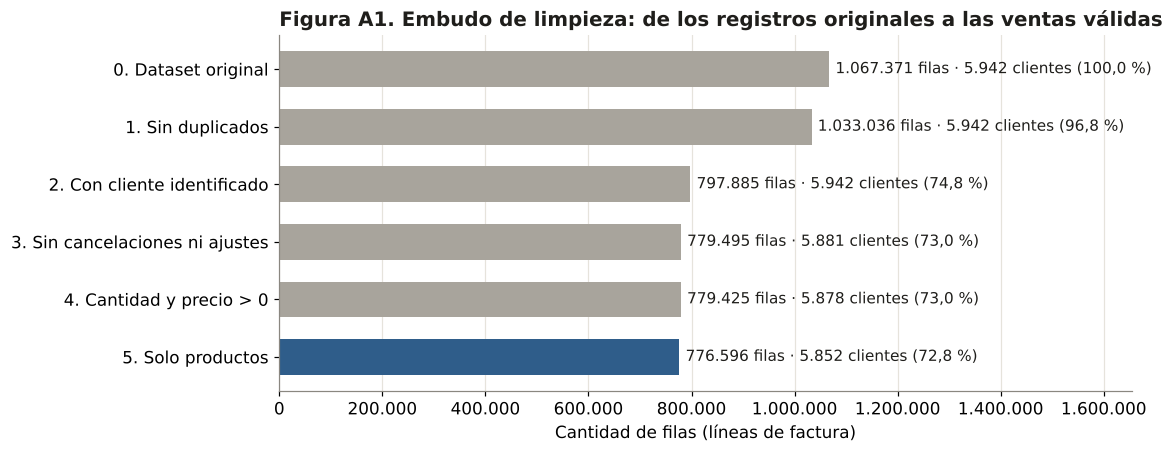

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(embudo))[::-1]                                   # El primer paso arriba, el último abajo
colores = [GRIS] * (len(embudo) - 1) + [AZUL]                      # El dataset final se destaca en azul
ax.barh(y, embudo["filas"], color=colores, height=0.62)
for yi, (_, fila) in zip(y, embudo.iterrows()):                    # Etiqueta con filas y clientes al final de cada barra
    texto = (f"{fila['filas']:,.0f} filas · {fila['clientes']:,.0f} clientes".replace(",", ".")
             + f" ({fila['% filas retenidas']:.1f} %)".replace(".", ","))
    ax.text(fila["filas"] + 12000, yi, texto, va="center", fontsize=10)
ax.set_yticks(y, embudo["paso"])
ax.xaxis.set_major_formatter(miles)
ax.set_xlim(0, embudo["filas"].max() * 1.55)
ax.set_xlabel("Cantidad de filas (líneas de factura)")
ax.set_title("Figura A1. Embudo de limpieza: de los registros originales a las ventas válidas")
ax.grid(axis="y", visible=False)
fig.savefig("figures/figA1_embudo_limpieza.png")
plt.show()

**Interpretación:** la limpieza conserva el **72,8 % de las filas** (776.596 líneas de factura) y el **98,5 % de los clientes** (5.852 de 5.942). El filtro que más pesa es el de cliente identificado (quita 235.151 filas, 22 puntos porcentuales del total); los demás filtros son menores pero necesarios para que el gasto refleje solo ventas reales de mercadería. El dataset limpio suma 36.594 facturas y £17,07 millones de facturación.

### 3.2 Exploración de los datos limpios
### Figura 1 · Estacionalidad, concentración del gasto y peso de cada país

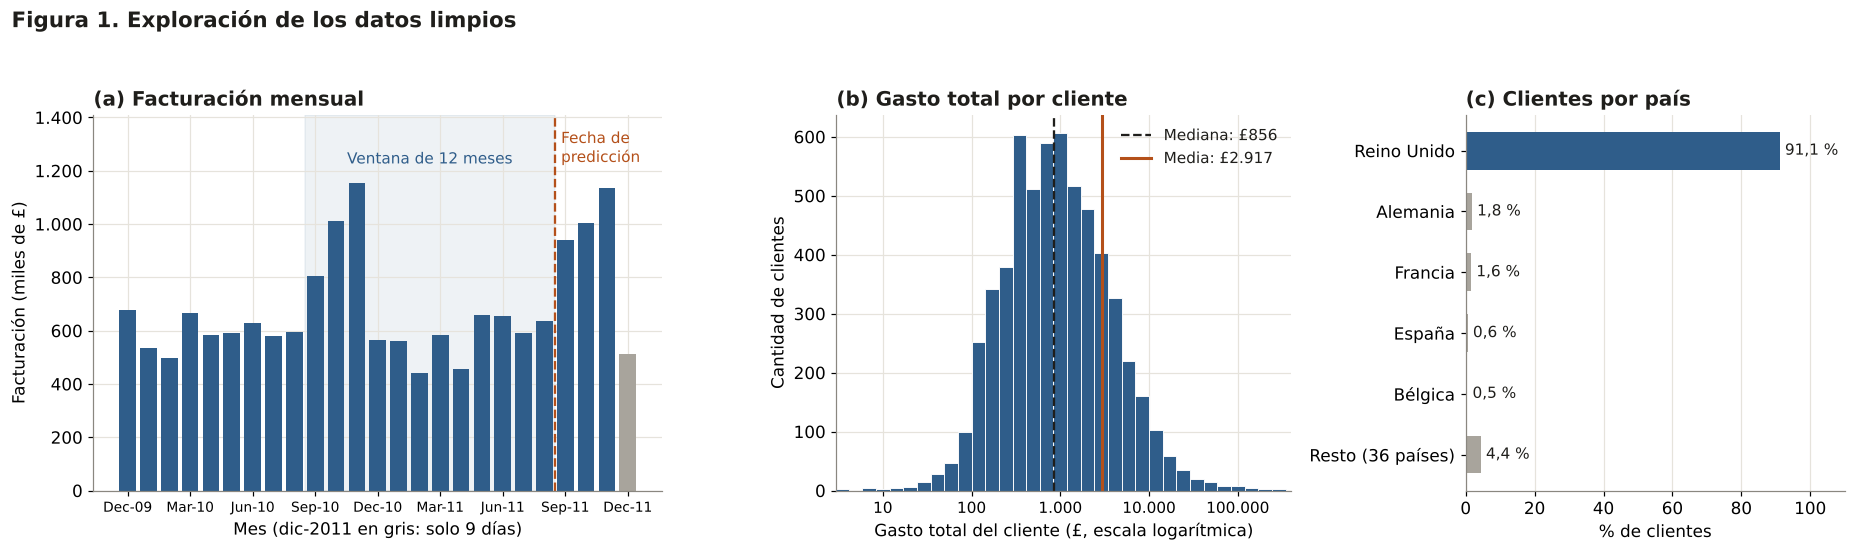

El 10 % de clientes que más gasta concentra el 63.9% de la facturación
El 20 % de clientes que más gasta concentra el 77.2% de la facturación
Mes de mayor facturación: 2010-11 (£1.155.978)
Clientes del Reino Unido: 91.1 %


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.5, 1.2, 1]})

# (a) Facturación por mes
mensual = df.groupby(df["InvoiceDate"].dt.to_period("M"))["Monto"].sum() / 1000   # En miles de £
etiquetas = [p.strftime("%b-%y") for p in mensual.index]
colores = [GRIS if p == pd.Period("2011-12", "M") else AZUL for p in mensual.index]   # dic-2011 incompleto (9 días)
ax = axes[0]
ax.bar(range(len(mensual)), mensual.values, color=colores, width=0.8)
pos_pred = list(mensual.index).index(pd.Period(FECHA_PREDICCION, "M"))                    # Posición de sep-2011
pos_inicio = list(mensual.index).index(pd.Period(INICIO_VENTANA, "M"))                # Posición de sep-2010
ax.axvspan(pos_inicio - 0.5, pos_pred - 0.5, color=AZUL, alpha=0.08, zorder=0)       # Ventana de 12 meses sombreada
ax.text((pos_inicio + pos_pred) / 2 - 0.5, mensual.max() * 1.05, "Ventana de 12 meses", ha="center", va="bottom", color=AZUL, fontsize=10)
ax.set_ylim(0, mensual.max() * 1.22)
ax.axvline(pos_pred - 0.5, color=NARANJA, linestyle="--", linewidth=1.5)
ax.text(pos_pred - 0.2, mensual.max() * 1.05, "Fecha de\npredicción", color=NARANJA, ha="left", va="bottom", fontsize=10)   # En dos líneas para que no invada el panel (b)
ax.set_xticks(range(0, len(mensual), 3), etiquetas[::3], rotation=0, fontsize=9)
ax.yaxis.set_major_formatter(miles)
ax.set_ylabel("Facturación (miles de £)")
ax.set_xlabel("Mes (dic-2011 en gris: solo 9 días)")
ax.set_title("(a) Facturación mensual")

# (b) Gasto total por cliente, en escala logarítmica
gasto = df.groupby("Cliente")["Monto"].sum()
ax = axes[1]
ax.hist(gasto, bins=np.logspace(0, 6, 40), color=AZUL, edgecolor="white", linewidth=0.6)
ax.set_xscale("log")
ax.axvline(gasto.median(), color=TINTA, linestyle="--", linewidth=1.5, label=f"Mediana: £{gasto.median():,.0f}".replace(",", "."))
ax.axvline(gasto.mean(), color=NARANJA, linewidth=2, label=f"Media: £{gasto.mean():,.0f}".replace(",", "."))
ax.set_xticks([10, 100, 1_000, 10_000, 100_000], ["10", "100", "1.000", "10.000", "100.000"], fontsize=10)
ax.set_xlim(3, 400_000)
ax.minorticks_off()                                                 # Sin marcas intermedias: el eje queda legible
ax.set_xlabel("Gasto total del cliente (£, escala logarítmica)")
ax.set_ylabel("Cantidad de clientes")
ax.legend(frameon=False, fontsize=10)
ax.set_title("(b) Gasto total por cliente")

# (c) Clientes por país (top 5 + resto)
pais_cliente = df.groupby("Cliente")["Country"].agg(lambda s: s.mode().iloc[0])   # País más frecuente de cada cliente
part = pais_cliente.value_counts(normalize=True) * 100
top = pd.concat([part.head(5), pd.Series({f"Resto ({len(part) - 5} países)": part.iloc[5:].sum()})])
top = top.rename(index={"United Kingdom": "Reino Unido", "Germany": "Alemania", "France": "Francia",
                        "Spain": "España", "Netherlands": "Países Bajos", "Belgium": "Bélgica",
                        "Portugal": "Portugal", "EIRE": "Irlanda"})
ax = axes[2]
yy = np.arange(len(top))[::-1]
ax.barh(yy, top.values, color=[AZUL] + [GRIS] * (len(top) - 1), height=0.62)
for yi, v in zip(yy, top.values):
    ax.text(v + 1.5, yi, f"{v:.1f} %".replace(".", ","), va="center", fontsize=10)
ax.set_yticks(yy, top.index)
ax.set_xlim(0, 110)
ax.set_xlabel("% de clientes")
ax.set_title("(c) Clientes por país")
ax.grid(axis="y", visible=False)

fig.suptitle("Figura 1. Exploración de los datos limpios", x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.04)
fig.tight_layout()
fig.savefig("figures/fig01_eda.png")
plt.show()

# Cifras de apoyo para el texto del informe
orden = gasto.sort_values(ascending=False)
print(f"El 10 % de clientes que más gasta concentra el {orden.head(int(len(orden) * 0.10)).sum() / orden.sum():.1%} de la facturación")
print(f"El 20 % de clientes que más gasta concentra el {orden.head(int(len(orden) * 0.20)).sum() / orden.sum():.1%} de la facturación")
print("Mes de mayor facturación:", mensual.idxmax(), f"(£{mensual.max() * 1000:,.0f})".replace(",", "."))
print("Clientes del Reino Unido:", f"{part['United Kingdom']:.1f} %")

**Interpretación:** (a) **El negocio es fuertemente estacional:** la facturación sube de septiembre a noviembre en ambos años (pico en noviembre de 2010: £1,16 millones), por la temporada navideña. La ventana de 12 meses que describe al cliente cubre exactamente un ciclo completo, con una sola temporada alta. Los 3 meses de la etiqueta de churn (septiembre a noviembre de 2011) caen en temporada alta: esto probablemente reduce la tasa de abandono observada y se declara como limitación. (b) **El gasto está muy concentrado:** la media (£2.917) más que triplica a la mediana (£856), y el 10 % de los clientes que más gasta genera el 63,9 % de la facturación (el 20 %, el 77,2 %). Tratar a todos los clientes por igual es ineficiente, lo que justifica segmentar. (c) **El 91,1 % de los clientes es del Reino Unido**: los resultados describen sobre todo al cliente británico y no deben generalizarse a otros mercados sin validación.

In [12]:
# ── Cifras de apoyo para la sección 2 del informe: compradores de una sola vez y clientes sin compras recientes ──
facturas_por_cliente = df.groupby("Cliente")["Invoice"].nunique()                        # Cuántas facturas distintas tiene cada cliente
una_sola_compra = (facturas_por_cliente == 1).mean()                                      # Porcentaje que compró una única vez
ultima_compra_cliente = df.groupby("Cliente")["InvoiceDate"].max()                        # Fecha de la última compra de cada cliente
fin_periodo = df["InvoiceDate"].max().normalize()                                         # Último día con datos (9/12/2011), sin hora
dias_sin_comprar = (fin_periodo - ultima_compra_cliente.dt.normalize()).dt.days           # Días enteros desde su última compra hasta el fin del período
sin_compras_180 = (dias_sin_comprar > 180).mean()                                         # Más de 180 días sin comprar al cierre del período
print(f"Compraron una sola vez: {una_sola_compra*100:.1f} % de los clientes".replace(".", ","))
print(f"Sin compras en los últimos 180 días del período: {sin_compras_180*100:.1f} % de los clientes".replace(".", ","))
print(f"Clientes identificados tras la limpieza: {df['Cliente'].nunique():,}".replace(",", "."))

Compraron una sola vez: 27,6 % de los clientes
Sin compras en los últimos 180 días del período: 40,6 % de los clientes


Clientes identificados tras la limpieza: 5.852


### 3.3 Tabla RFM a la fecha de predicción
Para cada cliente se calculan, **solo con compras de los 12 meses anteriores a la fecha de predicción** (01/09/2010 al 31/08/2011):
- **Recencia (R):** días desde su última compra hasta la fecha de predicción.
- **Frecuencia (F):** cantidad de facturas distintas.
- **Monetario (M):** gasto total en libras.

Entran los clientes con **al menos una compra en esa ventana**. Los que no compraron en todo el año previo ya no se consideran clientes activos a segmentar.

> **Prevención de fuga de datos:** esta tabla no usa ninguna transacción posterior al 31/08/2011. Es la misma base que usarán la Fase 1 (K-Means) y la Fase 2 (churn).

In [13]:
en_ventana = (df["InvoiceDate"] >= INICIO_VENTANA) & (df["InvoiceDate"] < FECHA_PREDICCION)   # Solo los 12 meses previos a la fecha de predicción
ventana = df[en_ventana]

rfm = ventana.groupby("Cliente").agg(
    ultima_compra=("InvoiceDate", "max"),          # Fecha de la última compra dentro de la ventana
    Frecuencia=("Invoice", "nunique"),             # Cantidad de facturas distintas
    Monetario=("Monto", "sum"),                    # Gasto total
)
# Recencia en días enteros: se normaliza la fecha (sin hora) para que una compra del 31/08 dé 1 día
rfm["Recencia"] = (FECHA_PREDICCION - rfm["ultima_compra"].dt.normalize()).dt.days
rfm = rfm[["Recencia", "Frecuencia", "Monetario"]]

assert ventana["InvoiceDate"].max() < FECHA_PREDICCION    # Control anti-fuga: ninguna transacción posterior a la fecha de predicción
print("Clientes con al menos una compra en la ventana:", len(rfm))
rfm.describe().round(1)

Clientes con al menos una compra en la ventana: 4324


,Recencia,Frecuencia,Monetario
count,4324.0,4324.0,4324.0
mean,144.3,4.1,1878.0
std,114.9,7.3,7563.9
min,1.0,1.0,2.9
25%,38.0,1.0,300.2
50%,112.0,2.0,636.2
75%,269.0,4.0,1523.0
max,365.0,181.0,267447.6


### 3.4 Valores extremos y escalado: decisión con evidencia
Dos decisiones quedaron pendientes en la pre-entrega:
1. **Tratamiento de valores extremos:** ¿transformación logarítmica o winsorización (recortar en los percentiles 1 y 99)?
2. **Escalado:** ¿`StandardScaler` o `RobustScaler`?

**Por qué importa:** K-Means agrupa por **distancia**. Si una variable tiene valores enormes (un cliente que gastó £267.000), domina la distancia y los grupos se forman solo por esa variable. Medimos la **asimetría** (*skewness*): 0 es simétrica; por encima de 1 (en valor absoluto), muy sesgada.

In [14]:
filas = []
for col in ["Recencia", "Frecuencia", "Monetario"]:
    v = rfm[col]
    p1, p99 = v.quantile([0.01, 0.99])                                  # Percentiles 1 y 99 para la winsorización
    filas.append({"variable": col,
                  "asimetría original": skew(v),
                  "con log(1+x)": skew(np.log1p(v)),                   # log1p = log(1 + x): admite ceros
                  "winsorizada (p1-p99)": skew(v.clip(p1, p99))})       # clip recorta los extremos
asimetria = pd.DataFrame(filas).set_index("variable").round(2)
asimetria.to_csv("results/rfm_asimetria.csv")
asimetria

,asimetría original,con log(1+x),winsorizada (p1-p99)
variable,,,
Recencia,0.42,-0.83,0.42
Frecuencia,10.67,1.27,3.01
Monetario,19.21,0.36,3.88


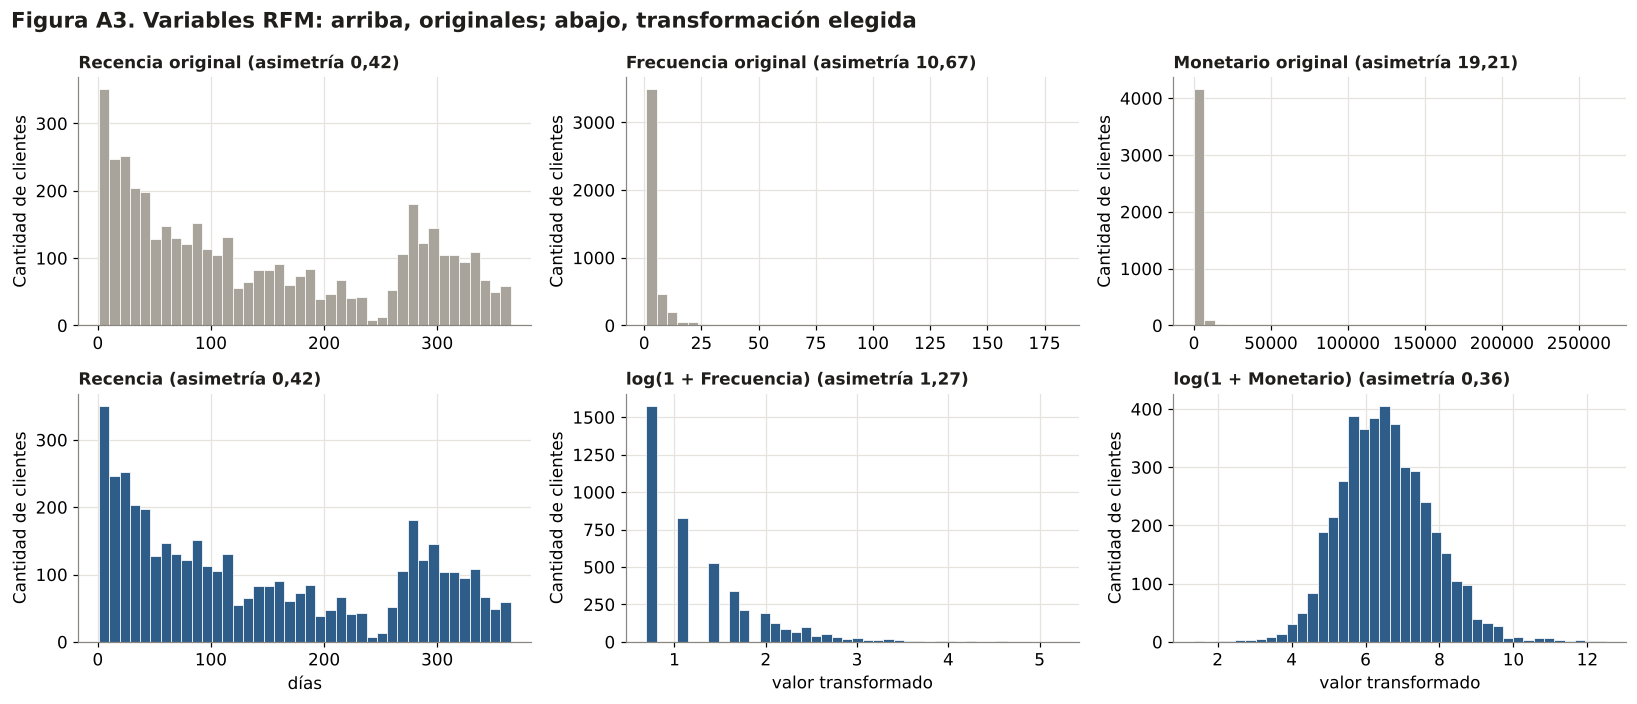

Recencia: 0.0% de clientes fuera de los bigotes después de la transformación
Frecuencia: 2.6% de clientes fuera de los bigotes después de la transformación
Monetario: 1.3% de clientes fuera de los bigotes después de la transformación


In [15]:
# ── Figura A3 (anexo): distribuciones antes y después de la transformación elegida ──
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
transformada = {"Recencia": rfm["Recencia"],                       # Recencia: se deja como está (ver decisión)
                "Frecuencia": np.log1p(rfm["Frecuencia"]),
                "Monetario": np.log1p(rfm["Monetario"])}
for j, col in enumerate(["Recencia", "Frecuencia", "Monetario"]):
    axes[0, j].hist(rfm[col], bins=40, color=GRIS, edgecolor="white", linewidth=0.5)
    axes[0, j].set_title(f"{col} original (asimetría {skew(rfm[col]):.2f})".replace(".", ","), fontsize=11)
    axes[1, j].hist(transformada[col], bins=40, color=AZUL, edgecolor="white", linewidth=0.5)
    nombre = col if col == "Recencia" else f"log(1 + {col})"
    axes[1, j].set_title(f"{nombre} (asimetría {skew(transformada[col]):.2f})".replace(".", ","), fontsize=11)
    axes[1, j].set_xlabel("días" if col == "Recencia" else "valor transformado")
    for i in range(2):
        axes[i, j].set_ylabel("Cantidad de clientes")
fig.suptitle("Figura A3. Variables RFM: arriba, originales; abajo, transformación elegida",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig("figures/figA3_rfm_logaritmo.png")
plt.show()

# ¿Cuántos valores extremos quedan después de la transformación? (criterio de Tukey: 1,5 × rango intercuartílico)
for col, v in transformada.items():
    q1, q3 = v.quantile([0.25, 0.75]); riq = q3 - q1
    fuera = ((v < q1 - 1.5 * riq) | (v > q3 + 1.5 * riq)).mean()
    print(f"{col}: {fuera:.1%} de clientes fuera de los bigotes después de la transformación")

**Decisión y justificación:** 

| Variable | Tratamiento elegido | Por qué |
|---|---|---|
| Recencia | **Sin transformar** | Ya es casi simétrica (0,42). El logaritmo la empeora (−0,83). |
| Frecuencia | **log(1 + x)** | Baja la asimetría de 10,67 a 1,27. La winsorización solo la lleva a 3,01. |
| Monetario | **log(1 + x)** | Baja la asimetría de 19,21 a 0,36. La winsorización solo la lleva a 3,88. |

**Por qué logaritmo y no winsorización:** el logaritmo comprime los valores grandes **sin perder el orden** entre clientes: el que más gastó sigue siendo el que más gastó. La winsorización iguala a todos los clientes por encima del percentil 99, y justamente esos son los VIP que queremos distinguir.

**Escalado: `StandardScaler`.** Después del logaritmo quedan muy pocos valores extremos (fuera de los bigotes de Tukey quedan 0 % de los clientes en Recencia, 2,6 % en Frecuencia y 1,3 % en Monetario; antes del logaritmo eran 9,9 % y 10,5 % en Frecuencia y Monetario), así que no hace falta la protección de `RobustScaler`. `StandardScaler` deja cada variable con media 0 y desvío 1: las tres pesan lo mismo en la distancia que usa K-Means.

> **Prevención de fuga:** el escalador **se ajusta solo con el 80 % de entrenamiento** en la Etapa 4A, no acá. En esta etapa solo medimos las distribuciones para decidir.

**Hallazgo adicional:** la Recencia muestra **dos grupos** (Figura A3): uno de compradores recientes y otro con última compra hace entre 270 y 330 días, es decir, entre octubre y diciembre de 2010. Son probables **compradores de temporada navideña**. Hipótesis para la Fase 2 [a verificar]: la regla por Recencia los marcaría como alto riesgo, pero podrían volver en la temporada siguiente; un modelo que combine más variables podría distinguirlos.

### 3.5 Variables adicionales de la Fase 2 (churn)
Además de R, F y M, el modelo de churn usa cinco variables más por cliente. El **segmento de la Fase 1** se agrega en la Etapa 4B, cuando exista. Todas se calculan **solo con compras anteriores a la fecha de predicción**; la antigüedad usa el historial completo previo (desde dic-2009) solo para saber cuándo hizo su primera compra.

| Variable | Cómo se calcula | Por qué podría ayudar a predecir el abandono |
|---|---|---|
| `ticket_promedio` | Monetario ÷ Frecuencia | Distingue al que compra poco y caro (mayorista) del que compra seguido y barato |
| `antiguedad_dias` | Días entre su primera compra y la fecha de predicción | Un cliente nuevo y uno de años no se comportan igual |
| `dias_entre_compras` | Promedio de días entre días de compra consecutivos (varias facturas el mismo día cuentan como un solo día) | Si suele comprar cada 30 días y lleva 90 sin hacerlo, es una señal de alerta |
| `variedad_productos` | Cantidad de códigos de producto distintos | Quien compra muchos productos distintos podría estar más ligado a la tienda |
| `pais_reino_unido` | 1 si su país principal es Reino Unido, 0 si es otro | Agrupa a todos los demás países en una sola categoría, para no crear una columna por país |

#### Decisión: clientes con un solo día de compra
Para calcular *días entre compras* se necesitan al menos **dos días de compra distintos**. Una compra se cuenta como un día: si el cliente hizo varias facturas el mismo día, es un solo día de compra. Los clientes que compraron en un único día no tienen ese dato, y son más de un tercio de la población (**1.648 de 4.324**: 1.578 con una sola factura y 70 con varias facturas el mismo día). Opciones evaluadas:

| Opción | Problema principal |
|---|---|
| Dejar el valor vacío | Random Forest y la regresión logística lo manejan mal o no lo aceptan |
| Poner 0 | Engañoso: 0 también es un valor real, y haría parecer a estos clientes los más fieles |
| Poner la mediana de los demás | Les inventa un ritmo de compra que no tienen |
| Excluirlos del modelo | Deja afuera justo a los de mayor riesgo, y rompe el objetivo de decidir a quién contactar |
| **Valor fijo alto (elegida)** | Es un supuesto, pero explícito y simple |

**Elegimos:** completar con **365 días** (el largo de la ventana de descripción). El valor es mayor que cualquier intervalo real entre compras, se interpreta con sentido de negocio (*tardaría un año o más en volver*) y **no usa estadísticos de los datos**, así que no hay riesgo de fuga.

**No agregamos una columna "compra única".** Sería casi una copia de la Frecuencia (F = 1): 1.578 de los 1.648 clientes del grupo tienen F = 1. Los modelos de árboles ya distinguen el 365 como valor de reemplazo, porque solo aparece en este grupo.

> **Para la interpretación (SHAP):** `dias_entre_compras = 365` y `Frecuencia = 1` señalan casi al mismo grupo de clientes. SHAP puede repartir la importancia entre ambas variables, por lo que no se presentan como señales independientes.


In [16]:
# ── Variables adicionales de la Fase 2 (churn): una fila por cliente, SOLO con datos anteriores a la fecha de predicción ──
# Se parte de la tabla RFM (R, F y M) y se agregan las demás. Se reutiliza "ventana" (los 12 meses previos a la fecha de predicción).
VALOR_UN_SOLO_DIA = (FECHA_PREDICCION - INICIO_VENTANA).days     # 365: largo de la ventana en días (ver la decisión en la celda de arriba)

vars_f2 = rfm.copy()                                         # Partimos de Recencia, Frecuencia y Monetario

# 1) Ticket promedio: cuánto gasta el cliente por compra (libras por factura)
vars_f2["ticket_promedio"] = vars_f2["Monetario"] / vars_f2["Frecuencia"]

# 2) Antigüedad: días desde su PRIMERA compra en todo el historial previo a la fecha de predicción hasta la fecha de predicción
historial_previo = df[df["InvoiceDate"] < FECHA_PREDICCION]       # Incluye dic-2009 a ago-2010: acá solo sirve para saber desde cuándo es cliente
primera_compra = historial_previo.groupby("Cliente")["InvoiceDate"].min()
vars_f2["antiguedad_dias"] = (FECHA_PREDICCION - primera_compra.dt.normalize()).dt.days   # Se alinea por cliente automáticamente

# 3) Días entre compras: promedio de días entre DÍAS DE COMPRA consecutivos
#    Varias facturas del mismo día cuentan como un solo día de compra. Así, una compra partida en dos facturas no parece un ritmo rapidísimo.
dias_de_compra = (ventana.assign(dia=ventana["InvoiceDate"].dt.normalize())   # Fecha sin la hora
                  .groupby(["Cliente", "dia"]).size().reset_index()[["Cliente", "dia"]]   # Una fila por cliente y por día con compra
                  .sort_values(["Cliente", "dia"]))                                      # Ordenados en el tiempo dentro de cada cliente
dias_de_compra["dias_desde_el_anterior"] = dias_de_compra.groupby("Cliente")["dia"].diff().dt.days   # Días entre un día de compra y el anterior
dias_entre_compras = dias_de_compra.groupby("Cliente")["dias_desde_el_anterior"].mean().reindex(vars_f2.index)   # Promedio por cliente; con un solo día de compra queda vacío (NaN)

un_solo_dia = dias_entre_compras.isna()                                   # True = compró en un solo día de la ventana (recibe el valor de reemplazo)
assert un_solo_dia[vars_f2["Frecuencia"] == 1].all()                      # Control: quien tiene una sola factura tiene un solo día de compra
vars_f2["dias_entre_compras"] = dias_entre_compras.fillna(VALOR_UN_SOLO_DIA)   # Valor fijo, sin estadísticos de los datos: no hay riesgo de fuga
# Nota: NO se agrega una columna "compra única": sería casi una copia de la Frecuencia (F = 1), y el 365 ya identifica al grupo.

# 4) Variedad de productos: cantidad de códigos de producto distintos que compró
vars_f2["variedad_productos"] = ventana.groupby("Cliente")["StockCode"].nunique()

# 5) País: 1 si su país principal (el más frecuente en sus compras) es Reino Unido, 0 si es otro
pais_principal = ventana.groupby("Cliente")["Country"].agg(lambda paises: paises.mode().iat[0])
vars_f2["pais_reino_unido"] = (pais_principal == "United Kingdom").astype(int)

# ── Controles anti-fuga y de calidad ──
assert historial_previo["InvoiceDate"].max() < FECHA_PREDICCION   # Ninguna transacción posterior a la fecha de predicción
assert len(vars_f2) == len(rfm)                              # Mismos clientes que la tabla RFM
assert vars_f2.isna().sum().sum() == 0                       # Sin celdas vacías
print("Clientes:", len(vars_f2), "| Variables:", vars_f2.shape[1])
vars_f2.describe().round(1)

Clientes: 4324 | Variables: 8


,Recencia,Frecuencia,Monetario,ticket_promedio,antiguedad_dias,dias_entre_compras,variedad_productos,pais_reino_unido
count,4324.0,4324.0,4324.0,4324.0,4324.0,4324.0,4324.0,4324.0
mean,144.3,4.1,1878.0,399.1,404.5,185.7,58.8,0.9
std,114.9,7.3,7563.9,1294.1,185.8,148.5,79.5,0.3
min,1.0,1.0,2.9,2.9,1.0,1.0,1.0,0.0
25%,38.0,1.0,300.2,178.5,284.0,48.0,16.0,1.0
50%,112.0,2.0,636.2,285.8,429.5,114.4,34.0,1.0
75%,269.0,4.0,1523.0,424.2,575.0,365.0,73.0,1.0
max,365.0,181.0,267447.6,77183.6,639.0,365.0,1644.0,1.0


**Evidencia para la decisión.** La siguiente tabla compara a los clientes según hayan comprado en un solo día o en dos o más días. La etiqueta de churn se usa **solo para esta tabla**; nunca entra como variable del modelo.

In [17]:
# ── Evidencia para la decisión: ¿los clientes con un solo día de compra abandonan distinto del resto? ──
# La etiqueta de churn se usa ACÁ solo para esta tabla de evidencia. Nunca entra como variable del modelo.
# (La etiqueta definitiva se arma en la Etapa 4B con esta misma regla: sin compras entre el 01/09/2011 y el 30/11/2011.)
compras_futuras = df[(df["InvoiceDate"] >= FECHA_PREDICCION) & (df["InvoiceDate"] < FIN_ETIQUETA)]["Cliente"].unique()
churn = pd.Series(~vars_f2.index.isin(compras_futuras), index=vars_f2.index).astype(int)   # 1 = no compró en los 3 meses siguientes

resumen_un_solo_dia = (vars_f2.assign(churn=churn, un_solo_dia=un_solo_dia.astype(int))
                       .groupby("un_solo_dia")
                       .agg(clientes=("churn", "size"),
                            tasa_churn_observada=("churn", "mean"),
                            recencia_mediana_dias=("Recencia", "median"),
                            gasto_mediano_libras=("Monetario", "median"))
                       .round(3))
resumen_un_solo_dia.index = resumen_un_solo_dia.index.map({0: "2 o más días de compra", 1: "Un solo día de compra"})
resumen_un_solo_dia.to_csv("results/un_solo_dia_resumen.csv")

# De los clientes con un solo día de compra, ¿cuántos tienen una factura y cuántos varias el mismo día?
una_factura = vars_f2["Frecuencia"] == 1
print("Un solo día de compra:", int(un_solo_dia.sum()),
      "| con una sola factura:", int((un_solo_dia & una_factura).sum()),
      "| con varias facturas el mismo día:", int((un_solo_dia & ~una_factura).sum()))
print("Tasa de churn observada en la ventana de análisis (todos los clientes):", round(churn.mean() * 100, 1), "%")
resumen_un_solo_dia


Un solo día de compra: 1648 | con una sola factura: 1578 | con varias facturas el mismo día: 70
Tasa de churn observada en la ventana de análisis (todos los clientes): 50.3 %


,clientes,tasa_churn_observada,recencia_mediana_dias,gasto_mediano_libras
un_solo_dia,,,,
2 o más días de compra,2676,0.367,69.0,1130.20
Un solo día de compra,1648,0.723,270.0,263.37


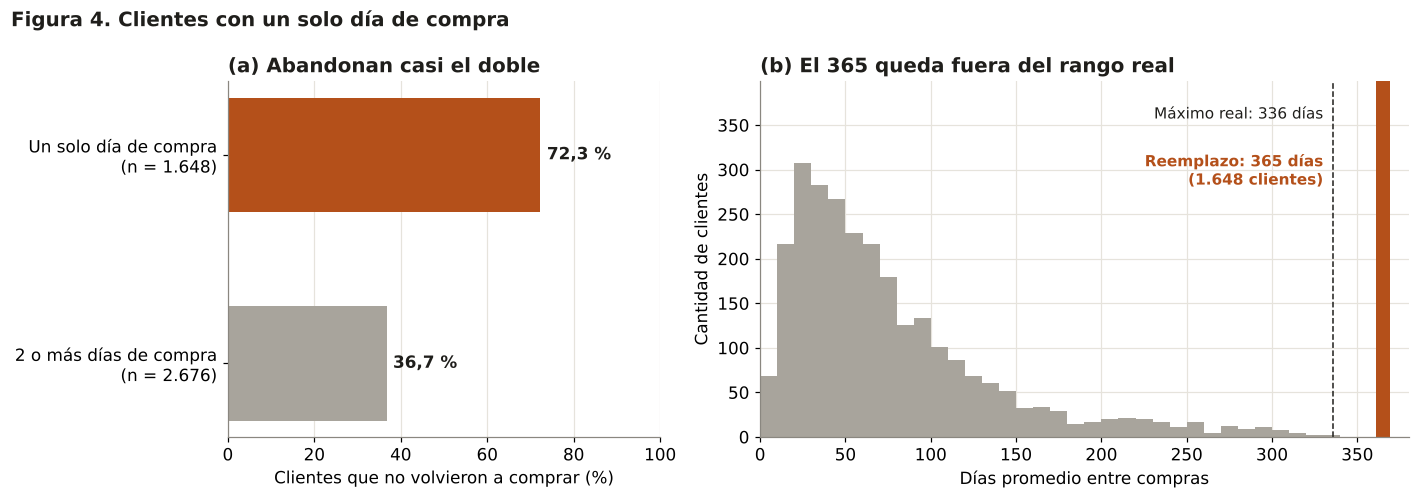

In [18]:
# ── Figura 4: clientes con un solo día de compra (qué abandonan y cómo completamos el dato) ──
# Panel (a): tasa de churn observada según la cantidad de días de compra. Panel (b): días entre compras reales vs. el valor de reemplazo.
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})

# (a) Tasa de churn observada en la ventana de análisis, por grupo (usa "resumen_un_solo_dia" de la celda anterior)
grupos = resumen_un_solo_dia.index.tolist()                                  # ["2 o más días de compra", "Un solo día de compra"]
tasas  = (resumen_un_solo_dia["tasa_churn_observada"] * 100).tolist()        # En porcentaje
clientes_grupo = resumen_un_solo_dia["clientes"].tolist()
ax_a.barh([0, 1], tasas, color=[GRIS, NARANJA], height=0.55)                  # El grupo de un solo día de compra se destaca en naranja
for pos, tasa in zip([0, 1], tasas):
    ax_a.text(tasa + 1.5, pos, f"{tasa:.1f} %".replace(".", ","), va="center", fontweight="bold", color=TINTA)
ax_a.set_yticks([0, 1], [f"{g}\n(n = {n:,})".replace(",", ".") for g, n in zip(grupos, clientes_grupo)])
ax_a.set_xlim(0, 100)
ax_a.set_xlabel("Clientes que no volvieron a comprar (%)")
ax_a.set_title("(a) Abandonan casi el doble", loc="left")
ax_a.grid(axis="y", visible=False)

# (b) Distribución de los días entre compras REALES (clientes con 2 o más compras) y el valor de reemplazo (365)
reales = vars_f2.loc[~un_solo_dia, "dias_entre_compras"]      # Solo valores medidos, sin el reemplazo
cantidad, bordes, _ = ax_b.hist(reales, bins=np.arange(0, 345, 10), color=GRIS)
techo = cantidad.max() * 1.30                                                 # Altura máxima del eje (deja aire para las etiquetas)
maximo_real = reales.max()                                                    # Intervalo real más largo (336 días)
ax_b.axvline(maximo_real, color=TINTA, linestyle="--", linewidth=1)           # Marca el máximo real
ax_b.bar(VALOR_UN_SOLO_DIA, techo, width=8, color=NARANJA)                   # Barra del reemplazo (se recorta: su altura real es mayor)
ax_b.set_xlim(0, 380)
ax_b.set_ylim(0, techo)
ax_b.text(maximo_real - 6, techo * 0.93, f"Máximo real: {maximo_real:.0f} días", ha="right", va="top", fontsize=10, color=TINTA)
ax_b.text(maximo_real - 6, techo * 0.80, f"Reemplazo: {VALOR_UN_SOLO_DIA} días\n({int(un_solo_dia.sum()):,} clientes)".replace(",", "."),
          ha="right", va="top", fontsize=10, color=NARANJA, fontweight="bold")
ax_b.set_xlabel("Días promedio entre compras")
ax_b.set_ylabel("Cantidad de clientes")
ax_b.set_title("(b) El 365 queda fuera del rango real", loc="left")

fig.suptitle("Figura 4. Clientes con un solo día de compra", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig("figures/fig04_abandono_un_solo_dia.png")                                 # Se inserta en el informe
plt.show()
# Lectura: quienes compraron en un solo día abandonan el doble que el resto; el reemplazo de 365 días supera el máximo real,
# así que el modelo puede distinguirlo de un intervalo medido.


**Qué concluimos:** los **1.648 clientes con un solo día de compra (38,1 %)** no son un caso marginal. Su tasa de churn observada en la ventana de análisis es de **72,3 %**, contra **36,7 %** en quienes compraron en dos o más días. Además llevan una Recencia mediana de **270 días** (contra 69) y gastan menos (mediana de **£263** contra **£1.130**). El valor máximo real de *días entre compras* es **336**, por debajo del 365 asignado, de modo que el reemplazo nunca se confunde con un dato medido.

Por eso conviene mantenerlos en el modelo con el valor de reemplazo de 365 días: es justo el grupo donde más importa decidir a quién contactar. Las cifras salieron de ejecutar este código sobre la tabla limpia; la tasa de churn definitiva se reporta en la Etapa 4B sobre el conjunto de prueba.


### 3.6 Qué queda afuera de la ventana de 12 meses
Antes de la fecha de predicción hay 21 meses de historia (diciembre de 2009 a agosto de 2011), pero la tabla RFM usa solo los últimos 12. Esta sección mide cuánto se deja afuera y deja identificado a ese grupo como **clientes inactivos**: gente que compró antes de septiembre de 2010 y no volvió en todo el último año. Quedan **fuera de los modelos**, pero se cuentan y se reportan, porque son público natural de una campaña de reactivación.

> **Aclaración metodológica:** esto acota la población respecto de "todos los clientes con al menos una compra antes de la fecha de predicción" que mencionan las instrucciones del proyecto. Es una decisión de diseño y se declara en el informe (Paso 1 de la sección 3.4).

In [19]:
# ── Clientes que quedan afuera de la ventana de 12 meses ("inactivos") ──
historial = df[df["InvoiceDate"] < FECHA_PREDICCION]                     # Todo lo anterior a la fecha de predicción (21 meses): sigue sin usar datos futuros
clientes_21m = set(historial["Cliente"])                            # Clientes con alguna compra antes de la fecha de predicción
clientes_12m = set(rfm.index)                                       # Clientes con compra en los 12 meses (población de estudio)
inactivos = clientes_21m - clientes_12m                             # Compraron antes de la ventana y no volvieron durante ella

facturacion_previa = historial["Monto"].sum()                       # Facturación total anterior a la fecha de predicción
facturacion_inactivos = historial.loc[historial["Cliente"].isin(inactivos), "Monto"].sum()   # Lo que aportaron los inactivos
volvieron = inactivos & set(compras_futuras)                        # Inactivos que compraron en sep-nov 2011 (solo como evidencia, no entra al modelo)
meses_historia = ((FECHA_PREDICCION.year - historial["InvoiceDate"].min().year) * 12
                  + FECHA_PREDICCION.month - historial["InvoiceDate"].min().month)   # Meses de historia antes de la fecha de predicción

resumen_inactivos = pd.DataFrame({
    "concepto": ["Meses de historia antes de la fecha de predicción", "Clientes con compra antes de la fecha de predicción",
                 "Clientes con compra en la ventana de 12 meses (población de estudio)",
                 "Clientes inactivos (sin compra en la ventana)", "% de inactivos sobre el total previo a la fecha de predicción",
                 "Facturación de los inactivos (£)", "% de la facturación previa a la fecha de predicción",
                 "Inactivos que compraron en sep-nov 2011", "% de los inactivos que volvieron"],
    "valor": [meses_historia, len(clientes_21m), len(clientes_12m), len(inactivos),
              round(len(inactivos) / len(clientes_21m) * 100, 1), round(facturacion_inactivos),
              round(facturacion_inactivos / facturacion_previa * 100, 1), len(volvieron),
              round(len(volvieron) / len(inactivos) * 100, 1)]})
resumen_inactivos.to_csv("results/clientes_inactivos_resumen.csv", index=False)   # Se guarda para el informe
resumen_inactivos

,concepto,valor
0,Meses de historia antes de la fecha de predicción,21.0
1,Clientes con compra antes de la fecha de predi...,5224.0
2,Clientes con compra en la ventana de 12 meses ...,4324.0
3,Clientes inactivos (sin compra en la ventana),900.0
4,% de inactivos sobre el total previo a la fech...,17.2
5,Facturación de los inactivos (£),562914.0
6,% de la facturación previa a la fecha de predi...,4.2
7,Inactivos que compraron en sep-nov 2011,96.0
8,% de los inactivos que volvieron,10.7


**Qué concluimos:** antes de la fecha de predicción hay **21 meses** de historia y **5.224 clientes** con alguna compra. De ellos, **4.324** compraron en la ventana de 12 meses (la población de estudio) y **900 (17,2 %)** no: son los clientes inactivos. Aportaron **£562.914**, es decir el **4,2 %** de la facturación previa a la fecha de predicción, de modo que dejarlos afuera cuesta poco en ingresos. **96** de ellos (10,7 %) volvieron a comprar entre septiembre y noviembre de 2011: hay margen de reactivación, pero acotado. Ese dato se usa solo como evidencia y no entra a ningún modelo.

## Etapa 4A · Modelado: segmentación (RFM + K-Means)
**Fase CRISP-DM: 4 – Modelado.** Objetivo de la etapa: dejar una segmentación de clientes que se pueda defender, comparada contra la regla tradicional de quintiles RFM.

Orden de trabajo: (4A.1) prueba de robustez de la ventana → (4A.2) separación 80/20 y escalado → (4A.3) valores extremos y escalador con el 80 % → (4A.4) búsqueda de K → (4A.5) K-Means final y perfil de los segmentos → (4A.6) comparación contra los quintiles RFM → (4A.7) estabilidad en el 20 % de prueba → (4A.8) visualización con UMAP → (4A.9) prueba de ventana con el 20 % de prueba → (4A.10) cierre.

### 4A.1 Prueba de robustez: ¿cambia algo usar los 21 meses en lugar de los 12?
Antes de modelar conviene comprobar que la ventana de 12 meses no distorsiona la segmentación. Se corre K-Means con k = 2 a 6 sobre dos bases: los clientes de la ventana de 12 meses y los 21 meses de historia completa, con las mismas transformaciones (logaritmo en Frecuencia y Monetario, StandardScaler). Es una **prueba exploratoria de la ventana** con todos los clientes de cada base: la búsqueda definitiva de K, con el 20 % de prueba, va más abajo.

In [20]:
# ── Robustez de la ventana: K-Means con 12 meses vs. 21 meses de historia ──
from sklearn.cluster import KMeans                                  # Algoritmo de agrupamiento
from sklearn.preprocessing import StandardScaler                    # Lleva cada variable a promedio 0 y desvío 1
from sklearn.metrics import silhouette_score, davies_bouldin_score  # Silhouette (más alto = mejor) y Davies-Bouldin (más bajo = mejor)

def rfm_transformado(transacciones):
    # Arma R, log(1+F) y log(1+M) por cliente a partir de las transacciones indicadas
    g = transacciones.groupby("Cliente").agg(ultima=("InvoiceDate", "max"),
                                             F=("Invoice", "nunique"), M=("Monto", "sum"))
    return pd.DataFrame({"Recencia": (FECHA_PREDICCION - g["ultima"].dt.normalize()).dt.days,
                         "Frecuencia_log": np.log1p(g["F"]), "Monetario_log": np.log1p(g["M"])})

bases = {"12 meses": ventana, "21 meses (historia completa)": historial}   # Las dos ventanas a comparar
filas = []
for nombre, transacciones in bases.items():
    X = StandardScaler().fit_transform(rfm_transformado(transacciones))     # Escalado de cada base
    for k in range(2, 7):
        etiquetas = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X)   # Semilla fija
        filas.append({"base": nombre, "clientes": X.shape[0], "k": k,
                      "silhouette": round(silhouette_score(X, etiquetas), 3),
                      "davies_bouldin": round(davies_bouldin_score(X, etiquetas), 2)})
robustez_ventana = pd.DataFrame(filas)
robustez_ventana.to_csv("results/robustez_ventana_12_vs_21.csv", index=False)   # Se guarda para el informe
robustez_ventana.pivot(index="k", columns="base", values=["silhouette", "davies_bouldin"])

silhouette                              davies_bouldin  \
base   12 meses 21 meses (historia completa)       12 meses   
k                                                             
2         0.430                        0.426           0.88   
3         0.392                        0.355           0.90   
4         0.373                        0.338           0.91   
5         0.357                        0.344           0.91   
6         0.342                        0.339           0.93   

                                   
base 21 meses (historia completa)  
k                                  
2                            0.86  
3                            0.97  
4                            0.94  
5                            0.93  
6                            0.89

**Qué concluimos:** el Silhouette es **igual o mayor con 12 meses** en los cinco valores de k (con k = 4: **0,373** contra **0,338**), aunque la ventaja es chica (entre 0,003 y 0,037). El Davies-Bouldin favorece a los 12 meses con k = 3, 4 y 5, y a los 21 meses con k = 2 y 6. Ninguna de las dos bases alcanza la referencia de 0,45, así que **la elección de la ventana no cambia la conclusión de calidad**: si no se llega a 0,45, se justifica por la utilidad de negocio de los segmentos. Mantener los 12 meses se apoya entonces en razones de diseño (ver sección 3.6): la misma base para las dos fases, un calendario sin meses contados dos veces y clientes que siguen activos. Estas cifras son exploratorias (todos los clientes de cada base, sin el 20 % de prueba) y no se usan para elegir K.

### 4A.2 Separación 80 % / 20 % y escalado
Vamos a **reservar el 20 % de los clientes** para usarlo una sola vez, al final, como prueba de que los segmentos no dependen de los clientes que usamos para armarlos. Todo lo que se *aprende* de los datos (el promedio y el desvío del escalador, los grupos de K-Means, los puntos de corte de los quintiles) se calcula **solo con el 80 %**.

**Por qué por cliente:** cada cliente es una fila de la tabla RFM, así que separar filas es separar clientes. Como acá no hay etiqueta (no supervisado), no hace falta estratificar.

In [21]:
# ── 4A.2 Separación 80 % / 20 % de clientes y escalado ajustado SOLO con el 80 % ──
from sklearn.model_selection import train_test_split               # Separa una tabla en dos partes al azar
from sklearn.preprocessing import StandardScaler                   # Lleva cada variable a promedio 0 y desvío 1
from sklearn.cluster import KMeans                                 # Algoritmo de agrupamiento
from sklearn.metrics import silhouette_score, davies_bouldin_score # Métricas de calidad de los grupos

# 1) Separación a nivel CLIENTE: cada cliente cae en un solo lado (no se parte su historial)
clientes_ajuste, clientes_prueba = train_test_split(
    rfm.index, test_size=0.20, random_state=RANDOM_STATE)          # Semilla fija: la separación es siempre la misma
rfm_ajuste    = rfm.loc[clientes_ajuste]                           # 80 %: acá se busca K y se ajusta el modelo
rfm_prueba = rfm.loc[clientes_prueba]                       # 20 %: clientes de prueba, se usan solo para la prueba de estabilidad
assert len(set(clientes_ajuste) & set(clientes_prueba)) == 0   # Control: ningún cliente está en las dos partes

# 2) Transformación (logaritmo en F y M; Recencia queda igual, según la decisión de la sección 3.4)
def transformar_rfm(tabla):
    # log(1+x) no "aprende" nada de los datos: se puede aplicar igual a las dos partes sin riesgo de fuga
    return pd.DataFrame({"Recencia": tabla["Recencia"],
                         "Frecuencia_log": np.log1p(tabla["Frecuencia"]),
                         "Monetario_log": np.log1p(tabla["Monetario"])}, index=tabla.index)

# 3) Escalado: el promedio y el desvío se calculan SOLO con el 80 % (fit) y luego se aplican a las dos partes (transform)
escalador = StandardScaler().fit(transformar_rfm(rfm_ajuste))
assert escalador.n_samples_seen_ == len(rfm_ajuste)                # Control anti-fuga: el escalador vio solo los clientes del 80 %
X_ajuste    = escalador.transform(transformar_rfm(rfm_ajuste))     # Matriz del 80 % (3 columnas: R, log F, log M, ya escaladas)
X_prueba = escalador.transform(transformar_rfm(rfm_prueba))  # Matriz del 20 %: escalada con los números del 80 %

# 4) Control visual: el 80 % queda con promedio 0 y desvío 1; el 20 % queda cerca, pero no exacto (es lo esperable)
control_escalado = pd.DataFrame({"promedio 80 %": X_ajuste.mean(axis=0), "desvío 80 %": X_ajuste.std(axis=0),
                                 "promedio 20 %": X_prueba.mean(axis=0), "desvío 20 %": X_prueba.std(axis=0)},
                                index=["Recencia", "log(1 + Frecuencia)", "log(1 + Monetario)"]).round(2)
print(f"Clientes de ajuste (80 %): {len(rfm_ajuste):,} | clientes de prueba (20 %): {len(rfm_prueba):,}".replace(",", "."))
control_escalado

Clientes de ajuste (80 %): 3.459 | clientes de prueba (20 %): 865


,promedio 80 %,desvío 80 %,promedio 20 %,desvío 20 %
Recencia,0.0,1.0,-0.02,1.00
log(1 + Frecuencia),0.0,1.0,0.07,1.07
log(1 + Monetario),-0.0,1.0,0.03,1.01


**Qué concluimos:** quedan **3.459 clientes de ajuste (80 %)** y **865 de prueba (20 %)**. El 80 % queda con promedio 0 y desvío 1 por construcción; el 20 % queda cerca (promedios entre −0,02 y 0,07, desvíos entre 1,00 y 1,07), que es lo esperable: se escaló con los números del 80 %. Los controles `assert` confirman que ningún cliente está en las dos partes y que el escalador solo vio al 80 %.

### 4A.3 Repetición con el 80 %: valores extremos y escalador
En la sección 3.4 decidimos el tratamiento de los valores extremos y el escalador con **todos** los clientes. Para que la decisión no dependa del 20 % de prueba, **repetimos las dos mediciones solo con el 80 %**:
1. Porcentaje de clientes con valores extremos (regla de Tukey) antes y después del logaritmo.
2. `StandardScaler` contra `RobustScaler` con k = 4 (Silhouette y Davies-Bouldin). Además calculamos el **ARI** (*Adjusted Rand Index*): mide cuánto coinciden los grupos de dos agrupamientos; 1 = idénticos, cerca de 0 = coinciden como por azar.

In [22]:
# ── 4A.3 Repetición con el 80 %: valores extremos y comparación de escaladores ──
from sklearn.preprocessing import RobustScaler                     # Alternativa que usa la mediana y el rango intercuartil
from sklearn.metrics import adjusted_rand_score                    # ARI: cuánto coinciden dos agrupamientos (1 = idénticos, ~0 = azar)

def porcentaje_extremos(serie):
    # Regla de Tukey: es "extremo" lo que queda más de 1,5 rangos intercuartiles fuera de la caja (Q1 a Q3)
    q1, q3 = serie.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).mean() * 100

ajuste_log = transformar_rfm(rfm_ajuste)                           # Variables con el logaritmo ya aplicado (80 %)
extremos = pd.DataFrame({
    "% extremos, sin transformar": [porcentaje_extremos(rfm_ajuste["Recencia"]), porcentaje_extremos(rfm_ajuste["Frecuencia"]), porcentaje_extremos(rfm_ajuste["Monetario"])],
    "% extremos, tratamiento elegido": [porcentaje_extremos(ajuste_log["Recencia"]), porcentaje_extremos(ajuste_log["Frecuencia_log"]), porcentaje_extremos(ajuste_log["Monetario_log"])],
}, index=["Recencia", "Frecuencia", "Monetario"]).round(1)
extremos.to_csv("results/valores_extremos_80.csv")

# Comparación de escaladores con k = 4, solo con el 80 % (misma lógica que la prueba exploratoria de la sección 3.4)
filas, etiquetas_por_escalador = [], {}
for nombre, escalador_prueba in {"StandardScaler": StandardScaler(), "RobustScaler": RobustScaler()}.items():
    Z = escalador_prueba.fit_transform(ajuste_log)                 # Escalado de las 3 variables con cada método
    etiquetas = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
    etiquetas_por_escalador[nombre] = etiquetas
    filas.append({"escalador": nombre, "silhouette": round(silhouette_score(Z, etiquetas), 3),
                  "davies_bouldin": round(davies_bouldin_score(Z, etiquetas), 3)})
comparacion_escaladores = pd.DataFrame(filas).set_index("escalador")
comparacion_escaladores.to_csv("results/comparacion_escaladores_80.csv")
ari_escaladores = adjusted_rand_score(etiquetas_por_escalador["StandardScaler"], etiquetas_por_escalador["RobustScaler"])
print(f"ARI entre los agrupamientos de los dos escaladores: {ari_escaladores:.3f}".replace(".", ","))
from IPython.display import display          # Para mostrar dos tablas en la misma celda
display(extremos); display(comparacion_escaladores)

ARI entre los agrupamientos de los dos escaladores: 0,679


,"% extremos, sin transformar","% extremos, tratamiento elegido"
Recencia,0.0,0.0
Frecuencia,9.5,2.5
Monetario,10.6,1.4


,silhouette,davies_bouldin
escalador,,
StandardScaler,0.373,0.916
RobustScaler,0.347,0.984


**Qué concluimos:** con el 80 % se confirma lo visto con todos los clientes. Los valores extremos bajan de **9,5 % a 2,5 %** en Frecuencia y de **10,6 % a 1,4 %** en Monetario (Recencia: 0 %). `StandardScaler` obtiene mejor Silhouette (**0,373 contra 0,347**) y mejor Davies-Bouldin (**0,916 contra 0,984**) que `RobustScaler`. El ARI entre ambos agrupamientos es **0,679**: coinciden en buena parte pero no del todo, y el de `StandardScaler` es el de mejor calidad. **Decisión confirmada: `StandardScaler`.** Las cifras de la sección 3.4 pasan de "a verificar" a verificadas (los valores con el 80 % difieren apenas de los calculados con todos los clientes).

### 4A.4 Búsqueda de K en el 80 %
Vamos a decidir **cuántos segmentos** conviene armar. Probamos de 2 a 8 grupos y miramos tres métricas: la **inercia** (método del codo: qué tan compactos son los grupos), el **Silhouette** (separación y cohesión; referencia del proyecto: > 0,45) y el índice **Davies-Bouldin** (cuanto más bajo, mejor). Como el codo suele no ser claro, miramos también cuánto cambia el **perfil de los grupos** al pasar de k = 3 a 4 y a 5.

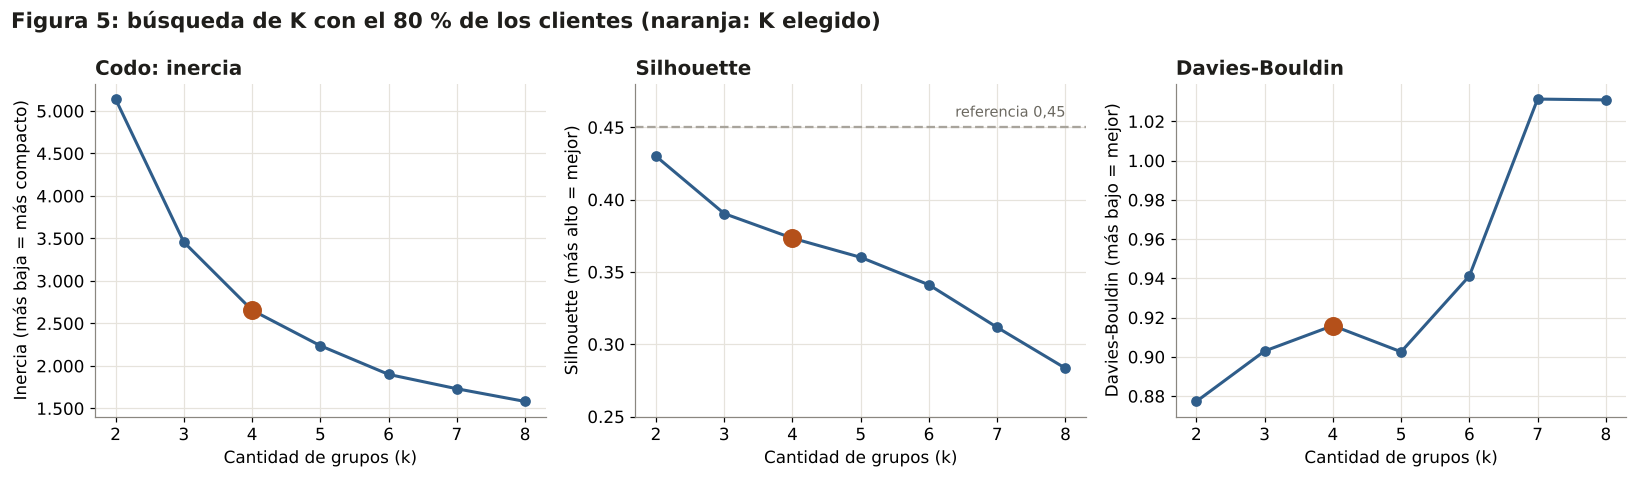

,inercia,silhouette,davies_bouldin,grupo_mas_chico_%,baja_de_inercia_vs_k_anterior_%
k,,,,,
2,5139.791,0.430,0.877,41.139,NaN
3,3456.607,0.390,0.903,25.325,32.748
4,2655.686,0.373,0.916,11.795,23.171
5,2237.656,0.360,0.903,11.448,15.741
6,1900.068,0.341,0.941,6.736,15.087
7,1731.159,0.312,1.031,4.741,8.890
8,1581.803,0.283,1.031,3.845,8.628


clientes  recencia  frecuencia  monetario  % clientes  % facturación
k                                                                        
3 0      1211     290.0         1.0      311.7        35.0            8.5
  1      1372      79.0         2.0      591.1        39.7           15.0
  2       876      30.0         7.0     2735.3        25.3           76.5
4 0       913      97.0         1.0      329.7        26.4            5.4
  1      1087     295.0         1.0      331.4        31.4            8.1
  2      1051      60.0         4.0     1331.8        30.4           26.5
  3       408      21.0        12.0     4827.4        11.8           60.1
5 0       793     303.0         1.0      259.1        22.9            3.5
  1       827      87.0         1.0      309.4        23.9            4.5
  2       499     252.0         2.0      810.4        14.4            8.7
  3       944      50.0         4.0     1356.2        27.3           23.7
  4       396      21.0        12.0     4966.4        11.4           59.6

In [23]:
# ── 4A.4 Búsqueda de K en el 80 %: codo (inercia), Silhouette y Davies-Bouldin ──
K_ELEGIDO = 4          # Decisión tomada al leer la tabla y la Figura 5 (justificación en el texto de abajo); solo usa el 80 %

filas = []
for k in range(2, 9):                                              # Probamos de 2 a 8 grupos
    modelo = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_ajuste)   # n_init=10: 10 arranques, se queda con el mejor
    tamanos = np.bincount(modelo.labels_)                          # Cuántos clientes quedan en cada grupo
    filas.append({"k": k, "inercia": modelo.inertia_,              # Inercia: suma de distancias² al centro de cada grupo (más baja = grupos más compactos)
                  "silhouette": silhouette_score(X_ajuste, modelo.labels_),          # Más alto = grupos más separados y cohesivos
                  "davies_bouldin": davies_bouldin_score(X_ajuste, modelo.labels_),  # Más bajo = mejor
                  "grupo_mas_chico_%": tamanos.min() / tamanos.sum() * 100})
busqueda_k = pd.DataFrame(filas).set_index("k")
busqueda_k["baja_de_inercia_vs_k_anterior_%"] = -busqueda_k["inercia"].pct_change() * 100   # Cuánto "ahorra" sumar un grupo más
busqueda_k.round(3).to_csv("results/busqueda_k_80.csv")

# ── Figura 5: tres miradas para elegir K ──
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.4))
paneles = [("inercia", "Codo: inercia", "Inercia (más baja = más compacto)"),
           ("silhouette", "Silhouette", "Silhouette (más alto = mejor)"),
           ("davies_bouldin", "Davies-Bouldin", "Davies-Bouldin (más bajo = mejor)")]
for eje, (col, titulo, etiqueta_y) in zip(ejes, paneles):
    eje.plot(busqueda_k.index, busqueda_k[col], marker="o", color=AZUL, linewidth=2)
    eje.scatter([K_ELEGIDO], [busqueda_k.loc[K_ELEGIDO, col]], s=130, color=NARANJA, zorder=5)   # K elegido, resaltado
    eje.set_title(titulo); eje.set_xlabel("Cantidad de grupos (k)"); eje.set_ylabel(etiqueta_y)
    eje.set_xticks(busqueda_k.index)
ejes[0].yaxis.set_major_formatter(miles)
ejes[1].axhline(0.45, color=GRIS, linestyle="--", linewidth=1.5)                    # Referencia del proyecto: Silhouette > 0,45
ejes[1].text(8, 0.455, "referencia 0,45", ha="right", va="bottom", fontsize=9.5, color="#6B6860")
ejes[1].set_ylim(0.25, 0.48)
fig.suptitle("Figura 5: búsqueda de K con el 80 % de los clientes (naranja: K elegido)", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout(); fig.savefig("figures/fig05_busqueda_k.png"); plt.show()

# ── Qué cambia entre k = 3, 4 y 5: perfil de cada grupo (medianas en unidades originales) ──
filas_perfil = []
for k in (3, 4, 5):
    etiquetas_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_ajuste)
    p = rfm_ajuste.assign(grupo=etiquetas_k).groupby("grupo").agg(clientes=("Recencia", "size"), recencia=("Recencia", "median"),
                                                                  frecuencia=("Frecuencia", "median"), monetario=("Monetario", "median"),
                                                                  facturacion=("Monetario", "sum"))
    p["% clientes"] = p["clientes"] / p["clientes"].sum() * 100; p["% facturación"] = p["facturacion"] / p["facturacion"].sum() * 100
    p.insert(0, "k", k); filas_perfil.append(p.drop(columns=["facturacion"]).sort_values("monetario").reset_index(drop=True))
perfil_k_vecinos = pd.concat(filas_perfil).set_index("k", append=True).swaplevel().round(1)
perfil_k_vecinos.to_csv("results/perfil_k3_k4_k5_80.csv")
from IPython.display import display
display(busqueda_k.round(3)); display(perfil_k_vecinos)

**Qué concluimos:**
1. **Ningún k llega al 0,45 de referencia:** el Silhouette es máximo con k = 2 (**0,430**) y baja al sumar grupos (k = 4: **0,373**). Es lo esperable en datos de clientes, que forman un continuo y no islas separadas. Por eso la elección de K se justifica por **utilidad de negocio**, como anticipamos en la pre-entrega.
2. **El codo no es marcado:** la inercia baja 32,7 % al pasar de 2 a 3 grupos, 23,2 % al pasar a 4 y desde k = 5 cada grupo nuevo ahorra menos de 16 %. Davies-Bouldin es casi plano entre k = 2 y 5 (0,877 a 0,916).
3. **Por qué k = 4:** con **k = 3** el grupo de mayor gasto junta al 25,3 % de los clientes y al 76,5 % de la facturación: mezcla a los VIP con los leales. Con **k = 4** ese grupo se parte en **VIP (11,8 % de los clientes, 60,1 % de la facturación)** y **Leales (30,4 % y 26,5 %)**, y el grupo de compradores de una sola vez se parte en dos que necesitan acciones distintas (recientes y dormidos). **k = 5** solo agrega un grupo de 14,4 % de clientes y 8,7 % de la facturación, a costa de más Silhouette (0,360) y un grupo más para gestionar. Costo de elegir k = 4 en lugar de k = 3: 0,017 puntos de Silhouette.
4. **Decisión: K = 4**, coherente con la hipótesis de al menos 4 arquetipos. Es una decisión de negocio apoyada en métricas, no un máximo de Silhouette.

### 4A.5 K-Means final y perfil de los segmentos
Vamos a ajustar el modelo definitivo con k = 4 (solo con el 80 %) y a **traducir cada grupo a lenguaje de negocio**: nombre, perfil, tamaño y acción de marketing. Los nombres se asignan con una regla escrita en código (gasto mediano, luego Recencia), para que no dependan del número de grupo que devuelva K-Means. La **antigüedad** se muestra solo para describir: no se usa para formar los grupos.

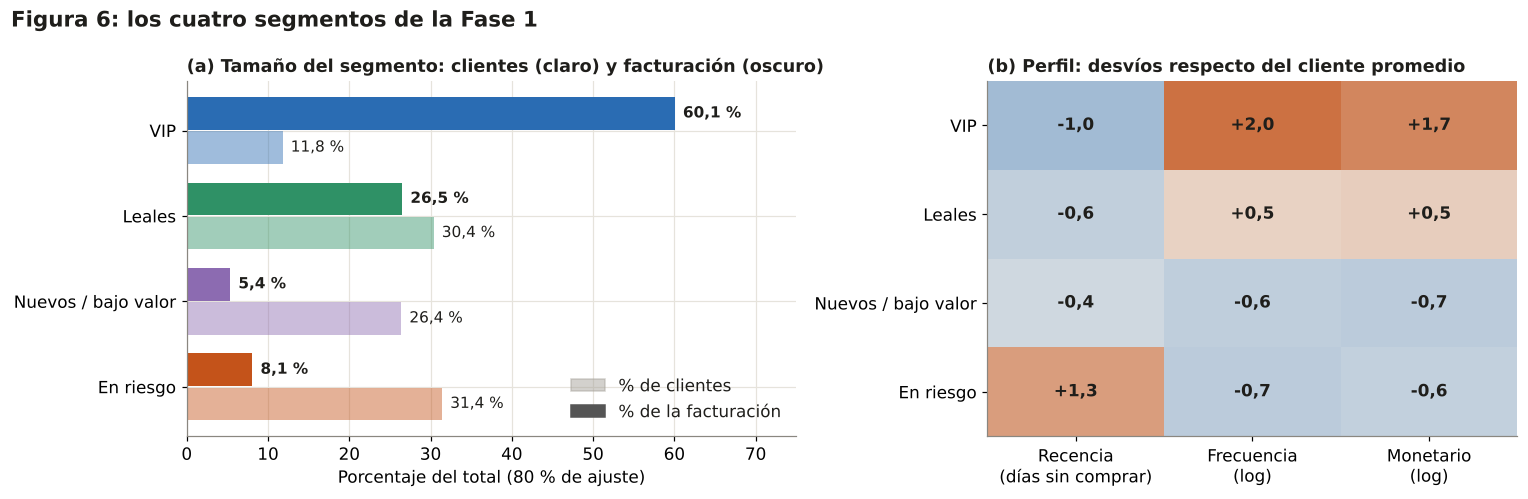

,clientes,recencia_mediana,frecuencia_mediana,monetario_mediana,antiguedad_mediana,% de clientes,% de la facturación
segmento,,,,,,,
VIP,408,21.0,12.0,4827.4,598.0,11.8,60.1
Leales,1051,60.0,4.0,1331.8,511.0,30.4,26.5
Nuevos / bajo valor,913,97.0,1.0,329.7,185.0,26.4,5.4
En riesgo,1087,295.0,1.0,331.4,354.0,31.4,8.1


In [24]:
# ── 4A.5 K-Means final (k = K_ELEGIDO), perfil de cada segmento y nombres ──
kmeans_final = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=RANDOM_STATE).fit(X_ajuste)   # Modelo definitivo: se ajusta solo con el 80 %

# Perfil en unidades originales (días, facturas, libras): es lo que entiende Marketing
ajuste_perfil = rfm_ajuste.assign(cluster=kmeans_final.labels_,
                                  antiguedad_dias=vars_f2.loc[rfm_ajuste.index, "antiguedad_dias"])   # Antigüedad: solo para DESCRIBIR, no entra al agrupamiento
perfil = ajuste_perfil.groupby("cluster").agg(clientes=("Recencia", "size"),
                                              recencia_mediana=("Recencia", "median"),
                                              frecuencia_mediana=("Frecuencia", "median"),
                                              monetario_mediana=("Monetario", "median"),
                                              antiguedad_mediana=("antiguedad_dias", "median"),
                                              facturacion=("Monetario", "sum"))

# Regla de nombres, escrita en código para que sea reproducible (no depende del número de cluster que asigne K-Means):
#   1) el de mayor gasto mediano = VIP; 2) el segundo = Leales;
#   3) de los dos restantes, el que lleva más días sin comprar = En riesgo; el otro = Nuevos / bajo valor
orden_gasto = perfil["monetario_mediana"].sort_values(ascending=False).index.tolist()
restantes = orden_gasto[2:]
nombres = {orden_gasto[0]: "VIP", orden_gasto[1]: "Leales"}
en_riesgo = perfil.loc[restantes, "recencia_mediana"].idxmax()
nombres[en_riesgo] = "En riesgo"
nombres[[c for c in restantes if c != en_riesgo][0]] = "Nuevos / bajo valor"

ACCIONES = {"VIP": "Retener y reconocer: acceso anticipado a novedades, atención personalizada, programa de fidelidad (sin regalar descuentos que no necesitan).",
            "Leales": "Subir el ticket: venta cruzada, packs y descuentos por volumen para acercarlos al nivel VIP.",
            "Nuevos / bajo valor": "Lograr la segunda compra: secuencia de bienvenida y cupón de segunda compra a bajo costo (correo electrónico).",
            "En riesgo": "Reactivar: campaña de reconquista con incentivo con vencimiento, recordando su última compra."}
ORDEN_SEGMENTOS = ["VIP", "Leales", "Nuevos / bajo valor", "En riesgo"]                     # Orden fijo para tablas y gráficos
COLOR_SEGMENTO = {"VIP": "#2A6CB3", "Leales": "#2F9166", "Nuevos / bajo valor": "#8C6BB1", "En riesgo": "#C4531A"}   # Un color por segmento (validado para daltonismo)

perfil["segmento"] = perfil.index.map(nombres)
perfil["% de clientes"] = perfil["clientes"] / perfil["clientes"].sum() * 100
perfil["% de la facturación"] = perfil["facturacion"] / perfil["facturacion"].sum() * 100
perfil["acción de marketing"] = perfil["segmento"].map(ACCIONES)
tabla_segmentos = perfil.set_index("segmento").loc[ORDEN_SEGMENTOS].drop(columns="facturacion")
tabla_segmentos.round(1).to_csv("results/perfil_segmentos_80.csv")

# ── Figura 6: quiénes son los segmentos (tamaño vs. facturación, y perfil en unidades estándar) ──
centros = pd.DataFrame(kmeans_final.cluster_centers_, columns=["Recencia\n(días sin comprar)", "Frecuencia\n(log)", "Monetario\n(log)"])
centros.index = centros.index.map(nombres); centros = centros.loc[ORDEN_SEGMENTOS]          # Centros en unidades estándar (0 = promedio)
fig, (eje_a, eje_b) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
posicion = np.arange(len(ORDEN_SEGMENTOS))
eje_a.barh(posicion + 0.2, tabla_segmentos["% de clientes"], height=0.38, color=[COLOR_SEGMENTO[s] for s in ORDEN_SEGMENTOS], alpha=0.45, label="% de clientes")
eje_a.barh(posicion - 0.2, tabla_segmentos["% de la facturación"], height=0.38, color=[COLOR_SEGMENTO[s] for s in ORDEN_SEGMENTOS], label="% de la facturación")
for i, s in enumerate(ORDEN_SEGMENTOS):
    eje_a.text(tabla_segmentos.loc[s, "% de clientes"] + 1, i + 0.2, f"{tabla_segmentos.loc[s, '% de clientes']:.1f} %".replace(".", ","), va="center", fontsize=10)
    eje_a.text(tabla_segmentos.loc[s, "% de la facturación"] + 1, i - 0.2, f"{tabla_segmentos.loc[s, '% de la facturación']:.1f} %".replace(".", ","), va="center", fontsize=10, fontweight="bold")
eje_a.set_yticks(posicion); eje_a.set_yticklabels(ORDEN_SEGMENTOS); eje_a.invert_yaxis()
eje_a.set_xlabel("Porcentaje del total (80 % de ajuste)"); eje_a.set_xlim(0, 75)
eje_a.set_title("(a) Tamaño del segmento: clientes (claro) y facturación (oscuro)", fontsize=11.5)
eje_a.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=GRIS, alpha=0.5), plt.Rectangle((0, 0), 1, 1, color="#555555")],
             labels=["% de clientes", "% de la facturación"], loc="lower right", frameon=False)
from matplotlib.colors import LinearSegmentedColormap                                      # Mapa de color divergente: azul (bajo) – gris – naranja (alto)
mapa = LinearSegmentedColormap.from_list("div", ["#2A6CB3", "#F1EFEA", "#C4531A"])
eje_b.imshow(centros.values, cmap=mapa, vmin=-2.5, vmax=2.5, aspect="auto")
for i in range(centros.shape[0]):
    for j in range(centros.shape[1]):
        eje_b.text(j, i, f"{centros.values[i, j]:+.1f}".replace(".", ","), ha="center", va="center", fontsize=11, fontweight="bold")
eje_b.set_xticks(range(3)); eje_b.set_xticklabels(centros.columns); eje_b.set_yticks(range(len(ORDEN_SEGMENTOS))); eje_b.set_yticklabels(ORDEN_SEGMENTOS)
eje_b.grid(False); eje_b.set_title("(b) Perfil: desvíos respecto del cliente promedio", fontsize=11.5)
fig.suptitle("Figura 6: los cuatro segmentos de la Fase 1", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout(); fig.savefig("figures/fig06_perfil_segmentos.png"); plt.show()
tabla_segmentos.drop(columns="acción de marketing").round(1)

**Qué concluimos:** los cuatro arquetipos de la hipótesis aparecen en los datos.

| Segmento | Quiénes son | Tamaño | Facturación |
|---|---|---|---|
| **VIP** | Compraron hace 21 días (mediana), 12 facturas, £4.827 | 11,8 % | **60,1 %** |
| **Leales** | Hace 60 días, 4 facturas, £1.332 | 30,4 % | 26,5 % |
| **Nuevos / bajo valor** | Hace 97 días, 1 factura, £330; primera compra hace 185 días (los más nuevos) | 26,4 % | 5,4 % |
| **En riesgo** | Hace 295 días, 1 factura, £331; primera compra hace 354 días | 31,4 % | 8,1 % |

**Lectura de negocio:** el 12 % de los clientes genera el 60 % de la facturación (la concentración que justificaba segmentar). **Aclaración importante:** en estos datos, "En riesgo" son sobre todo compradores de una sola vez que no volvieron (gasto mediano £331), no clientes valiosos que se están yendo. Quién entre los clientes valiosos está en riesgo de abandonar lo responde la Fase 2 (probabilidad de churn). Un grupo de "dormidos que antes compraban más" recién aparece con k = 5 (14,4 % de los clientes, Recencia 252 días, £810); lo dejamos como límite de la segmentación con k = 4.

### 4A.6 Baseline: quintiles RFM, y comparación con K-Means
Vamos a comprobar si K-Means **supera a la regla tradicional**. El baseline funciona en tres pasos: (1) los **quintiles** (cortes calculados con el 80 %) convierten Recencia, Frecuencia y Monetario en un puntaje de 1 a 5; (2) cada cliente queda con tres puntajes; (3) una **tabla de reglas**, como la que usaría Marketing, asigna el segmento. Como los puntajes solos dan 125 combinaciones, las reglas los reducen a **4 segmentos**, para comparar en igualdad de condiciones con K-Means: VIP (R, F y M ≥ 4), Leales (los tres ≥ 3), En riesgo (R ≤ 2 con F o M ≥ 3) y el resto como "necesitan atención / bajo valor". Se revisan en ese orden y el cliente queda en el primer segmento cuya regla cumple.

**Aclaración:** no existe una tabla de reglas estándar única; esta es nuestra operacionalización de la práctica habitual y sus umbrales son un criterio de diseño (están a la vista en el código).

Todas las métricas se miden **en el mismo espacio** (las 3 variables escaladas), con el 80 % y con el 20 % de prueba (los clientes de prueba se puntúan con los cortes del 80 %).

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


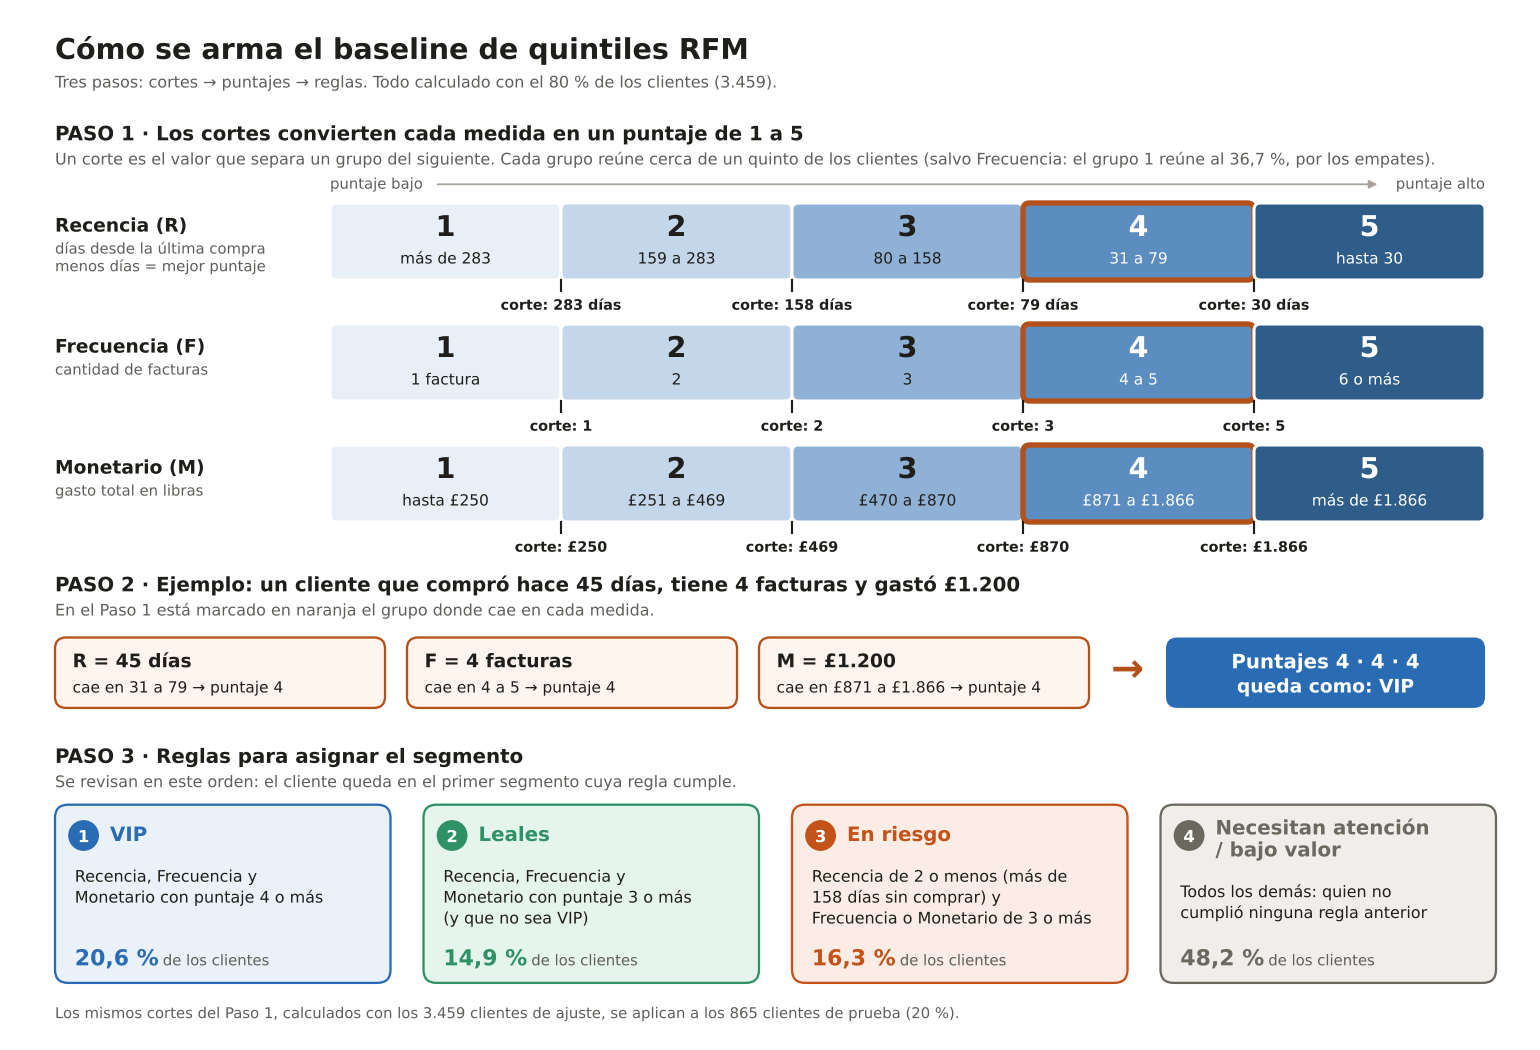

In [25]:
# ── 4A.6 Baseline: segmentación tradicional por quintiles RFM (cortes → puntajes → reglas) ──
# Los puntos de corte de los quintiles se calculan SOLO con el 80 % y luego se aplican al 20 % (sin fuga)
cortes_quintiles = {col: rfm_ajuste[col].quantile([0.2, 0.4, 0.6, 0.8]).values for col in ["Recencia", "Frecuencia", "Monetario"]}

def puntajes_rfm(tabla):
    # Puntaje de 1 a 5 por variable. En Recencia, menos días es mejor: por eso se invierte (5 = compró hace poco)
    p = pd.DataFrame(index=tabla.index)
    p["R"] = 5 - np.searchsorted(cortes_quintiles["Recencia"], tabla["Recencia"].values, side="left")
    p["F"] = 1 + np.searchsorted(cortes_quintiles["Frecuencia"], tabla["Frecuencia"].values, side="left")
    p["M"] = 1 + np.searchsorted(cortes_quintiles["Monetario"], tabla["Monetario"].values, side="left")
    return p

def baseline_reglas(p):
    # Baseline: tabla de reglas que usaría Marketing con los puntajes (4 segmentos, los mismos arquetipos de la hipótesis)
    seg = pd.Series("Necesitan atención / bajo valor", index=p.index)       # Por defecto: el resto de los clientes
    seg[(p["R"] <= 2) & ((p["F"] >= 3) | (p["M"] >= 3))] = "En riesgo"       # Compraban bien, pero hace tiempo que no vuelven
    seg[(p["R"] >= 3) & (p["F"] >= 3) & (p["M"] >= 3)] = "Leales"            # Recientes, frecuentes y de buen gasto
    seg[(p["R"] >= 4) & (p["F"] >= 4) & (p["M"] >= 4)] = "VIP"               # Excelentes en las tres
    return seg.values

puntos_ajuste, puntos_prueba = puntajes_rfm(rfm_ajuste), puntajes_rfm(rfm_prueba)

# ── Figura 7: cómo se arma el baseline. Todo sale de los datos (cortes, rangos, porcentajes): nada está escrito a mano ──
from matplotlib.patches import FancyBboxPatch, Circle
def piso(valor): return int(np.floor(valor + 1e-9))                       # Parte entera (días y facturas son números enteros)
def miles(n): return f"{int(round(n)):,}".replace(",", ".")               # 1866 → "1.866"
def coma(v): return f"{v:.1f}".replace(".", ",")                          # 36.7 → "36,7"
def tramo(a, b): return f"{a}" if a == b else f"{a} a {b}"

# Rangos de cada puntaje (de 1 a 5, de izquierda a derecha) y cortes que los separan
rc, fc = [piso(c) for c in cortes_quintiles["Recencia"]], [piso(c) for c in cortes_quintiles["Frecuencia"]]
mc = [int(round(c)) for c in cortes_quintiles["Monetario"]]
assert all(np.diff(rc) > 0) and all(np.diff(fc) > 0) and all(np.diff(mc) > 0)    # Cortes distintos: ningún grupo queda vacío
rangos = {"Recencia": [f"más de {rc[3]}", tramo(rc[2] + 1, rc[3]), tramo(rc[1] + 1, rc[2]), tramo(rc[0] + 1, rc[1]), f"hasta {rc[0]}"],
          "Frecuencia": ["1 factura" if fc[0] == 1 else f"hasta {fc[0]}", tramo(fc[0] + 1, fc[1]), tramo(fc[1] + 1, fc[2]),
                         tramo(fc[2] + 1, fc[3]), f"{fc[3] + 1} o más"],
          "Monetario": [f"hasta £{miles(mc[0])}", f"£{miles(mc[0] + 1)} a £{miles(mc[1])}", f"£{miles(mc[1] + 1)} a £{miles(mc[2])}",
                        f"£{miles(mc[2] + 1)} a £{miles(mc[3])}", f"más de £{miles(mc[3])}"]}
cortes_texto = {"Recencia": [f"{c} días" for c in rc[::-1]], "Frecuencia": [str(c) for c in fc], "Monetario": [f"£{miles(c)}" for c in mc]}

# Cliente de ejemplo: se puntúa con los mismos cortes y se le aplican las reglas
ejemplo = pd.DataFrame({"Recencia": [45], "Frecuencia": [4], "Monetario": [1200.0]})
puntos_ejemplo = puntajes_rfm(ejemplo).iloc[0]
segmento_ejemplo = baseline_reglas(puntajes_rfm(ejemplo))[0]
reglas_ajuste = pd.Series(baseline_reglas(puntos_ajuste)).value_counts(normalize=True) * 100     # % de clientes por segmento (80 %)
parte_F1 = (puntos_ajuste["F"] == 1).mean() * 100                                                # % de clientes con puntaje 1 en Frecuencia

GRIS_TEXTO = "#5F5E5A"                                                      # Gris oscuro para textos secundarios
rampa = ["#E8EFF7", "#C3D6EA", "#8FB1D6", "#5B8DC0", "#2F5D8A"]            # Puntaje 1 → 5 (más oscuro = mejor)
tinta_celda = [TINTA, TINTA, TINTA, "white", "white"]
fig = plt.figure(figsize=(13.8, 9.35)); ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 1380); ax.set_ylim(935, 0); ax.axis("off")                  # Lienzo en "píxeles": y crece hacia abajo
def escribir(x, y, texto, tam, peso="normal", color=TINTA, ha="left"):
    ax.text(x, y, texto, fontsize=tam * 0.72, fontweight=peso, color=color, ha=ha, va="baseline")
def caja(x, y, ancho, alto, relleno, borde, grosor, radio):
    ax.add_patch(FancyBboxPatch((x, y), ancho, alto, boxstyle=f"round,pad=0,rounding_size={radio}", facecolor=relleno, edgecolor=borde, linewidth=grosor))

escribir(40, 44, "Cómo se arma el baseline de quintiles RFM", 26, "bold")
escribir(40, 70, f"Tres pasos: cortes → puntajes → reglas. Todo calculado con el 80 % de los clientes ({miles(len(rfm_ajuste))}).", 14.5, color=GRIS_TEXTO)
escribir(40, 118, "PASO 1 · Los cortes convierten cada medida en un puntaje de 1 a 5", 18, "bold")
escribir(40, 140, f"Un corte es el valor que separa un grupo del siguiente. Cada grupo reúne cerca de un quinto de los clientes "
                  f"(salvo Frecuencia: el grupo 1 reúne al {coma(parte_F1)} %, por los empates).", 14.5, color=GRIS_TEXTO)
X0, ANCHO = 290, 1050; CW = ANCHO / 5
escribir(X0, 162, "puntaje bajo", 13.5, color=GRIS_TEXTO); escribir(X0 + ANCHO, 162, "puntaje alto", 13.5, color=GRIS_TEXTO, ha="right")
ax.annotate("", xy=(X0 + ANCHO - 95, 158), xytext=(X0 + 95, 158), arrowprops=dict(arrowstyle="-|>", color="#A8A49C", lw=1.2))
medidas = [("Recencia", "Recencia (R)", ["días desde la última compra", "menos días = mejor puntaje"], 175, "R"),
           ("Frecuencia", "Frecuencia (F)", ["cantidad de facturas"], 285, "F"),
           ("Monetario", "Monetario (M)", ["gasto total en libras"], 395, "M")]
for col, titulo, notas, y, letra in medidas:
    escribir(40, y + 26, titulo, 17, "bold")
    for j, nota in enumerate(notas): escribir(40, y + 46 + 16 * j, nota, 13.5, color=GRIS_TEXTO)
    for i in range(5):
        x = X0 + i * CW
        es_ejemplo = (i + 1 == puntos_ejemplo[letra])                       # Naranja: el grupo donde cae el cliente de ejemplo
        caja(x, y, CW, 70, rampa[i], NARANJA if es_ejemplo else "white", 3.5 if es_ejemplo else 2, 6)
        escribir(x + CW / 2, y + 30, str(i + 1), 26, "bold", tinta_celda[i], "center")
        escribir(x + CW / 2, y + 55, rangos[col][i], 14, "medium", tinta_celda[i], "center")
    for k, texto in enumerate(cortes_texto[col]):
        x = X0 + (k + 1) * CW
        ax.plot([x, x], [y + 70, y + 80], color=TINTA, linewidth=1.4)
        escribir(x, y + 97, f"corte: {texto}", 13, "semibold", TINTA, "center")

escribir(40, 528, f"PASO 2 · Ejemplo: un cliente que compró hace {ejemplo.Recencia[0]} días, tiene {ejemplo.Frecuencia[0]} facturas y gastó £{miles(ejemplo.Monetario[0])}", 18, "bold")
escribir(40, 550, "En el Paso 1 está marcado en naranja el grupo donde cae en cada medida.", 14.5, color=GRIS_TEXTO)
fichas = [(f"R = {ejemplo.Recencia[0]} días", "Recencia", "R", 40), (f"F = {ejemplo.Frecuencia[0]} facturas", "Frecuencia", "F", 360),
          (f"M = £{miles(ejemplo.Monetario[0])}", "Monetario", "M", 680)]
for t1, col, letra, x in fichas:
    caja(x, 570, 300, 64, "#FFF5EE", NARANJA, 1.5, 10)
    escribir(x + 16, 597, t1, 17, "bold")
    escribir(x + 16, 620, f"cae en {rangos[col][puntos_ejemplo[letra] - 1]} → puntaje {puntos_ejemplo[letra]}", 14)
escribir(1000, 610, "→", 36, "bold", NARANJA)
caja(1050, 570, 290, 64, COLOR_SEGMENTO.get(segmento_ejemplo, GRIS), "none", 0, 10)
escribir(1195, 598, f"Puntajes {puntos_ejemplo['R']} · {puntos_ejemplo['F']} · {puntos_ejemplo['M']}", 18, "bold", "white", "center")
escribir(1195, 620, f"queda como: {segmento_ejemplo}", 17, "bold", "white", "center")

escribir(40, 684, "PASO 3 · Reglas para asignar el segmento", 18, "bold")
escribir(40, 706, "Se revisan en este orden: el cliente queda en el primer segmento cuya regla cumple.", 14.5, color=GRIS_TEXTO)
tarjetas = [("1", "VIP", ["Recencia, Frecuencia y", "Monetario con puntaje 4 o más"], "VIP", "#EAF1F9", COLOR_SEGMENTO["VIP"]),
            ("2", "Leales", ["Recencia, Frecuencia y", "Monetario con puntaje 3 o más", "(y que no sea VIP)"], "Leales", "#E6F4EE", COLOR_SEGMENTO["Leales"]),
            ("3", "En riesgo", [f"Recencia de 2 o menos (más de", f"{rc[2]} días sin comprar) y", "Frecuencia o Monetario de 3 o más"], "En riesgo", "#FBEDE5", COLOR_SEGMENTO["En riesgo"]),
            ("4", "Necesitan atención / bajo valor", ["Todos los demás: quien no", "cumplió ninguna regla anterior"], "Necesitan atención / bajo valor", "#EFEEEB", "#6B6860")]
for n, (num, nombre, lineas, clave, fondo, borde) in enumerate(tarjetas):
    x = 40 + n * 335
    caja(x, 722, 305, 162, fondo, borde, 1.5, 12)
    ax.add_patch(Circle((x + 26, 750), 14, facecolor=borde, edgecolor="none"))
    escribir(x + 26, 756, num, 15, "bold", "white", "center")
    titulo_lineas = ["Necesitan atención", "/ bajo valor"] if len(nombre) > 14 else [nombre]
    for j, linea in enumerate(titulo_lineas):
        escribir(x + 50, 755 + 20 * j - (0 if len(titulo_lineas) == 1 else 6), linea, 18, "bold", borde)
    for j, linea in enumerate(lineas):
        escribir(x + 18, 792 + (14 if len(titulo_lineas) > 1 else 0) + 19 * j, linea, 14.5)
    escribir(x + 18, 868, f"{coma(reglas_ajuste[clave])} %", 20, "bold", borde)
    escribir(x + 18 + 80, 868, "de los clientes", 13.5, color=GRIS_TEXTO)
escribir(40, 916, f"Los mismos cortes del Paso 1, calculados con los {miles(len(rfm_ajuste))} clientes de ajuste, se aplican a los {len(rfm_prueba)} clientes de prueba (20 %).", 13.5, color=GRIS_TEXTO)
fig.savefig("figures/fig07_baseline_quintiles.png", dpi=150); plt.show()

**Qué concluimos:** el baseline es una regla simple y transparente, y se calcula sin mirar al 20 %. Su límite ya se ve en la Figura 7: casi la mitad de los clientes (48,2 %) cae en el grupo por defecto, "necesitan atención / bajo valor". La Figura 8 y la tabla siguiente miden qué tan bien separa esos grupos comparado con K-Means.

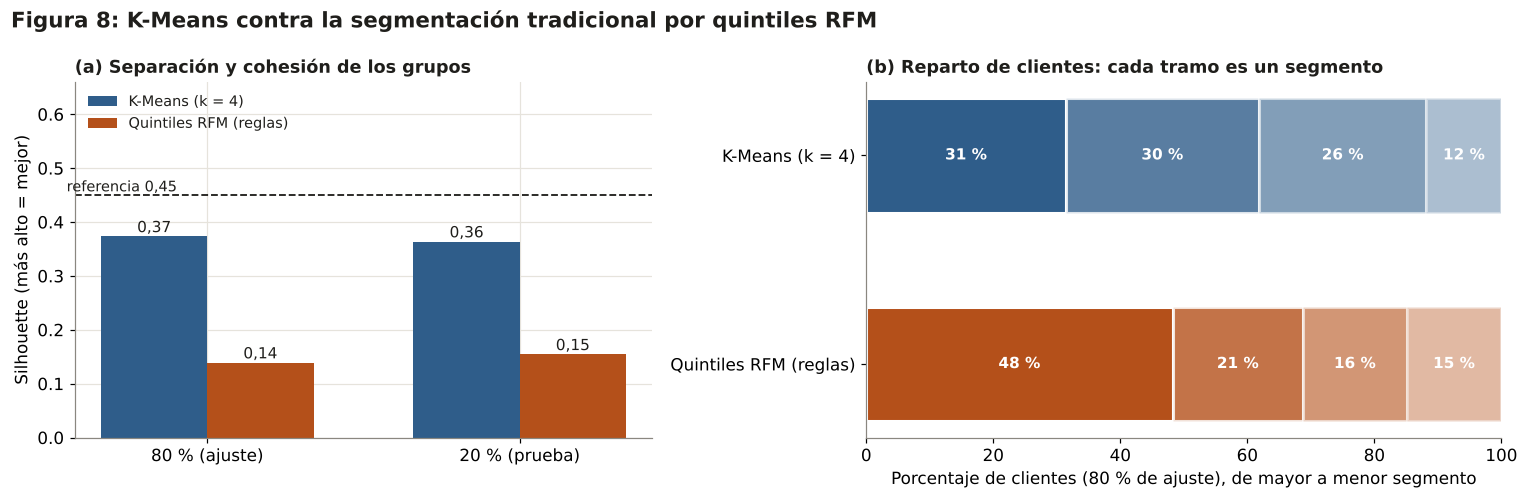

silhouette  davies_bouldin  \
método                 muestra                                     
K-Means (k = 4)        80 % (ajuste)       0.373           0.916   
                       20 % (prueba)       0.364           0.920   
Quintiles RFM (reglas) 80 % (ajuste)       0.139           1.400   
                       20 % (prueba)       0.154           1.319   

                                      % de la variación explicada  \
método                 muestra                                      
K-Means (k = 4)        80 % (ajuste)                       74.408   
                       20 % (prueba)                       74.288   
Quintiles RFM (reglas) 80 % (ajuste)                       58.940   
                       20 % (prueba)                       60.554   

                                      segmento más grande (%)  \
método                 muestra                                  
K-Means (k = 4)        80 % (ajuste)                   31.425   
                       20 % (prueba)                   31.561   
Quintiles RFM (reglas) 80 % (ajuste)                   48.222   
                       20 % (prueba)                   46.012   

                                      equilibrio de tamaños (0-1)  
método                 muestra                                     
K-Means (k = 4)        80 % (ajuste)                        0.959  
                       20 % (prueba)                        0.965  
Quintiles RFM (reglas) 80 % (ajuste)                        0.906  
                       20 % (prueba)                        0.919

In [26]:
# ── 4A.6 (cont.) Comparación de K-Means con el baseline, con las mismas métricas y en el mismo espacio ──
def evaluar(etiquetas, X):
    # Mide un agrupamiento con las mismas métricas y en el mismo espacio (X) para todos los métodos
    etiquetas = np.asarray(etiquetas); grupos = np.unique(etiquetas)
    centros_g = np.array([X[etiquetas == g].mean(axis=0) for g in grupos])
    dentro = sum(((X[etiquetas == g] - centros_g[i]) ** 2).sum() for i, g in enumerate(grupos))   # Dispersión dentro de los grupos
    total = ((X - X.mean(axis=0)) ** 2).sum()                                                      # Dispersión total
    partes = np.array([(etiquetas == g).mean() for g in grupos])
    return {"silhouette": silhouette_score(X, etiquetas), "davies_bouldin": davies_bouldin_score(X, etiquetas),
            "% de la variación explicada": (1 - dentro / total) * 100,
            "segmento más grande (%)": partes.max() * 100,
            "equilibrio de tamaños (0-1)": -(partes * np.log(partes)).sum() / np.log(len(partes))}   # 1 = grupos del mismo tamaño

metodos = {"K-Means (k = 4)": (kmeans_final.labels_, kmeans_final.predict(X_prueba)),
           "Quintiles RFM (reglas)": (baseline_reglas(puntos_ajuste), baseline_reglas(puntos_prueba))}
filas = []
for nombre, (etiq_ajuste, etiq_prueba) in metodos.items():
    filas.append({"método": nombre, "muestra": "80 % (ajuste)", **evaluar(etiq_ajuste, X_ajuste)})
    filas.append({"método": nombre, "muestra": "20 % (prueba)", **evaluar(etiq_prueba, X_prueba)})
comparacion = pd.DataFrame(filas).set_index(["método", "muestra"])
comparacion.round(3).to_csv("results/comparacion_kmeans_vs_quintiles.csv")

# ── Figura 8: K-Means contra los quintiles RFM ──
colores_metodo = {"K-Means (k = 4)": AZUL, "Quintiles RFM (reglas)": NARANJA}
fig, (eje_a, eje_b) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
ancho = 0.34
for i, (nombre, color) in enumerate(colores_metodo.items()):
    valores = [comparacion.loc[(nombre, m), "silhouette"] for m in ["80 % (ajuste)", "20 % (prueba)"]]
    barras = eje_a.bar(np.arange(2) + (i - 0.5) * ancho, valores, width=ancho, color=color, label=nombre)
    for b, v in zip(barras, valores):
        eje_a.text(b.get_x() + b.get_width() / 2, v + 0.008, f"{v:.2f}".replace(".", ","), ha="center", fontsize=10)
eje_a.axhline(0.45, color=TINTA, linestyle="--", linewidth=1.2); eje_a.text(-0.45, 0.457, "referencia 0,45", ha="left", fontsize=9.5)   # Referencia del proyecto
eje_a.set_xticks(range(2)); eje_a.set_xticklabels(["80 % (ajuste)", "20 % (prueba)"]); eje_a.set_ylim(0, 0.66)
eje_a.set_ylabel("Silhouette (más alto = mejor)"); eje_a.set_title("(a) Separación y cohesión de los grupos", fontsize=11.5)
eje_a.legend(frameon=False, fontsize=9.5, loc="upper left", ncol=1)   # La leyenda queda arriba, sobre la línea de referencia
# (b) Reparto de clientes por segmento en el 80 %: 100 % apilado
for i, (nombre, (etiq_ajuste, _)) in enumerate(metodos.items()):
    conteo = pd.Series(etiq_ajuste).value_counts(normalize=True).sort_values(ascending=False) * 100
    izquierda = 0
    for j, parte in enumerate(conteo.values):
        eje_b.barh(i, parte, left=izquierda, color=colores_metodo[nombre], alpha=1 - 0.2 * j, edgecolor="white", linewidth=2, height=0.55)
        eje_b.text(izquierda + parte / 2, i, f"{parte:.0f} %", ha="center", va="center", fontsize=10, fontweight="bold",
                   color="white")
        izquierda += parte
eje_b.set_yticks(range(len(metodos))); eje_b.set_yticklabels(list(metodos)); eje_b.invert_yaxis(); eje_b.set_xlim(0, 100)
eje_b.set_xlabel("Porcentaje de clientes (80 % de ajuste), de mayor a menor segmento"); eje_b.grid(False)
eje_b.set_title("(b) Reparto de clientes: cada tramo es un segmento", fontsize=11.5)
fig.suptitle("Figura 8: K-Means contra la segmentación tradicional por quintiles RFM", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout(); fig.savefig("figures/fig08_kmeans_vs_quintiles.png"); plt.show()
comparacion.round(3)

**Qué concluimos:**

| Método (80 % de ajuste) | Silhouette | Davies-Bouldin | % de la variación explicada | Segmento más grande |
|---|---|---|---|---|
| **K-Means (k = 4)** | **0,373** | **0,916** | **74,4 %** | 31,4 % |
| Quintiles RFM (reglas) | 0,139 | 1,400 | 58,9 % | 48,2 % |

1. **K-Means separa y agrupa mejor** que la regla tradicional, y la ventaja se mantiene en el 20 % de prueba (Silhouette 0,364 contra 0,154).
2. **Equilibrio de tamaños:** K-Means (segmento más grande: 31,4 %) reparte mejor a los clientes que la tabla de reglas (48,2 %), que deja casi la mitad en el grupo por defecto. La hipótesis se cumple en separación y cohesión, y también en equilibrio.
3. **Advertencia metodológica:** Silhouette y Davies-Bouldin miden distancias en el mismo espacio que K-Means optimiza, así que lo favorecen por construcción. Por eso la comparación no se apoya solo en estas métricas: también cuenta que los segmentos de K-Means son interpretables y accionables (sección 4A.5) y que en la Fase 2 se medirá si los segmentos distinguen diferencias reales de abandono.
4. Como ningún método llega al 0,45 de referencia (el mejor es 0,373), la elección se justifica por **utilidad de negocio**.

### 4A.7 Prueba de estabilidad en el 20 % de prueba
Vamos a usar por primera vez el 20 % de prueba. Cada cliente de prueba se asigna al **centroide más cercano** del modelo ajustado con el 80 % (no se vuelve a ajustar nada), y se comparan las métricas con las del 80 %. **Criterio fijado antes de mirar:** la segmentación se considera estable si Silhouette e inercia (por cliente, para poder comparar grupos de distinto tamaño) difieren **hasta un 10 %**.

In [27]:
# ── 4A.7 Prueba de estabilidad: ¿el 20 % de prueba se comporta como el 80 %? ──
# Cada cliente de prueba se asigna al centroide más cercano del modelo ajustado con el 80 % (predict). No se vuelve a ajustar nada.
segmento_prueba = kmeans_final.predict(X_prueba)

def inercia_por_cliente(modelo, X, etiquetas):
    # Distancia² promedio de cada cliente a su centroide. Se divide por la cantidad de clientes para poder comparar 80 % con 20 %
    return ((X - modelo.cluster_centers_[etiquetas]) ** 2).sum(axis=1).mean()

metricas_80 = {"Silhouette": silhouette_score(X_ajuste, kmeans_final.labels_),
               "Inercia por cliente": inercia_por_cliente(kmeans_final, X_ajuste, kmeans_final.labels_),
               "Davies-Bouldin": davies_bouldin_score(X_ajuste, kmeans_final.labels_)}
metricas_20 = {"Silhouette": silhouette_score(X_prueba, segmento_prueba),
               "Inercia por cliente": inercia_por_cliente(kmeans_final, X_prueba, segmento_prueba),
               "Davies-Bouldin": davies_bouldin_score(X_prueba, segmento_prueba)}
estabilidad = pd.DataFrame({"80 % (ajuste)": metricas_80, "20 % (prueba)": metricas_20})
estabilidad["diferencia (%)"] = (estabilidad["20 % (prueba)"] / estabilidad["80 % (ajuste)"] - 1) * 100
UMBRAL_ESTABILIDAD = 10                                             # Criterio fijado antes de mirar: diferencia absoluta de hasta 10 %
estabilidad["¿cumple ≤ 10 %?"] = np.where(estabilidad["diferencia (%)"].abs() <= UMBRAL_ESTABILIDAD, "Sí", "No")
estabilidad.round(3).to_csv("results/estabilidad_holdout.csv")

# Reparto de clientes por segmento: ¿se parecen el 80 % y el 20 %?
reparto = pd.DataFrame({"80 % (ajuste)": pd.Series(kmeans_final.labels_).map(nombres).value_counts(normalize=True) * 100,
                        "20 % (prueba)": pd.Series(segmento_prueba).map(nombres).value_counts(normalize=True) * 100}).loc[ORDEN_SEGMENTOS]
reparto["diferencia (puntos)"] = reparto["20 % (prueba)"] - reparto["80 % (ajuste)"]
reparto.round(1).to_csv("results/estabilidad_reparto.csv")
from IPython.display import display
display(estabilidad.round(3)); display(reparto.round(1))

,80 % (ajuste),20 % (prueba),diferencia (%),¿cumple ≤ 10 %?
Silhouette,0.373,0.364,-2.579,Sí
Inercia por cliente,0.768,0.811,5.579,Sí
Davies-Bouldin,0.916,0.920,0.435,Sí


,80 % (ajuste),20 % (prueba),diferencia (puntos)
VIP,11.8,13.1,1.3
Leales,30.4,31.6,1.2
Nuevos / bajo valor,26.4,24.5,-1.9
En riesgo,31.4,30.9,-0.6


**Qué concluimos:** **la segmentación es estable.** Silhouette: 0,373 en el 80 % y 0,364 en el 20 % (**−2,6 %**). Inercia por cliente: 0,768 contra 0,811 (**+5,6 %**; algo mayor en el 20 %, lo esperable porque los centroides se ajustaron con el 80 %). Davies-Bouldin: 0,916 contra 0,920 (+0,4 %). Los tres están dentro del 10 %. El reparto por segmento también se mantiene: la diferencia máxima es de 1,9 puntos porcentuales (Nuevos / bajo valor: 26,4 % contra 24,5 %).

### 4A.8 Visualización con UMAP
Vamos a **dibujar** los clientes para ver si los segmentos se distinguen a simple vista. UMAP comprime las 3 variables a 2 dimensiones; los grupos ya están definidos por K-Means, y UMAP solo ayuda a verlos. El 20 % de prueba se proyecta sobre el mismo plano, sin reajustar.

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


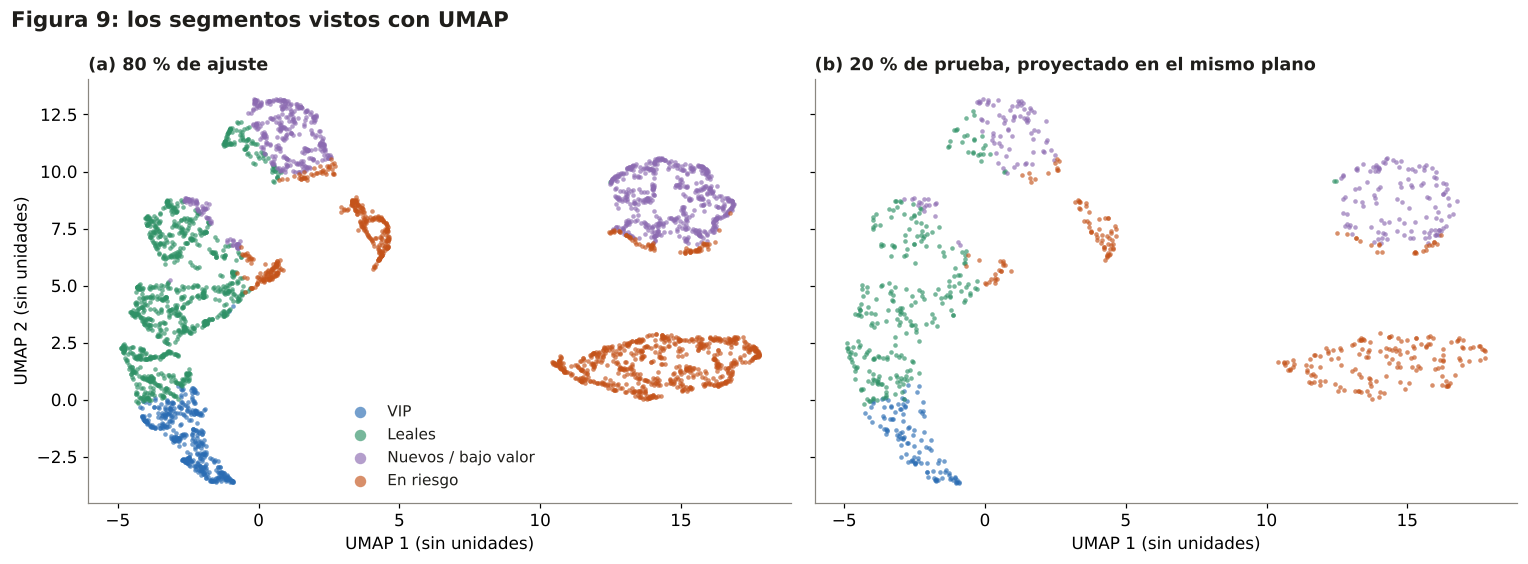

In [28]:
# ── 4A.8 Visualización con UMAP: ¿se ven los segmentos? ──
# UMAP comprime las 3 variables a 2 dimensiones para poder dibujarlas. Es SOLO una ayuda visual: el agrupamiento se hizo con K-Means en el espacio original.
import umap                                                         # Librería umap-learn
import warnings; warnings.filterwarnings("ignore", message="n_jobs value 1 overridden")   # Aviso inofensivo: con semilla fija UMAP corre en un solo núcleo
reductor = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=RANDOM_STATE)   # Semilla fija: el dibujo siempre sale igual
plano_ajuste = reductor.fit_transform(X_ajuste)                     # Se ajusta con el 80 %
plano_prueba = reductor.transform(X_prueba)                   # El 20 % se proyecta en el mismo plano, sin reajustar

fig, (eje_a, eje_b) = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True, sharey=True)
for eje, plano, etiquetas, titulo in [(eje_a, plano_ajuste, kmeans_final.labels_, "(a) 80 % de ajuste"),
                                      (eje_b, plano_prueba, segmento_prueba, "(b) 20 % de prueba, proyectado en el mismo plano")]:
    for segmento in ORDEN_SEGMENTOS:
        marca = pd.Series(etiquetas).map(nombres).values == segmento
        eje.scatter(plano[marca, 0], plano[marca, 1], s=9, alpha=0.65, color=COLOR_SEGMENTO[segmento], label=segmento, linewidths=0)
    eje.set_title(titulo, fontsize=11.5); eje.set_xlabel("UMAP 1 (sin unidades)"); eje.grid(False)
eje_a.set_ylabel("UMAP 2 (sin unidades)")
eje_a.legend(frameon=False, markerscale=2.5, fontsize=10)
fig.suptitle("Figura 9: los segmentos vistos con UMAP", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout(); fig.savefig("figures/fig09_umap_segmentos.png"); plt.show()

**Qué concluimos:** (1) **Los segmentos de compradores de una sola vez (Nuevos / bajo valor y En riesgo) forman islas bien separadas**, probablemente porque la Frecuencia = 1 es un valor discreto y nítido. (2) **Entre Leales y VIP hay un continuo, no una frontera marcada:** los VIP son el extremo de ese continuo. Esto explica por qué el Silhouette no pasa de 0,37 y conviene decirlo en el informe: la segmentación es útil para decidir, pero el límite entre Leales y VIP es una convención. (3) El 20 % de prueba cae en las mismas zonas que el 80 %, en línea con la prueba de estabilidad. UMAP deforma las distancias: se usa solo para visualizar, nunca para medir.

### 4A.9 La prueba de ventana (12 vs. 21 meses), ahora con el 20 % de prueba
En 4A.1 la comparación usó todos los clientes. Acá la repetimos como corresponde: cada base se separa 80/20, el escalador y K-Means se ajustan con el 80 %, y se mide también el 20 % asignado al centroide más cercano.

In [29]:
# ── 4A.9 La prueba de ventana (12 vs. 21 meses), ahora con el 20 % de prueba ──
# Para cada base: se separa 80/20 por cliente, el escalador y K-Means se ajustan con el 80 % y se mide también el 20 % asignado al centroide más cercano.
filas = []
for nombre, transacciones in {"12 meses": ventana, "21 meses (historia completa)": historial}.items():
    base = rfm_transformado(transacciones)                          # R, log F, log M por cliente (función de la sección 4A.1)
    ids_ajuste, ids_prueba = train_test_split(base.index, test_size=0.20, random_state=RANDOM_STATE)
    esc = StandardScaler().fit(base.loc[ids_ajuste])                # Escalador ajustado solo con el 80 % de esa base
    Xa, Xr = esc.transform(base.loc[ids_ajuste]), esc.transform(base.loc[ids_prueba])
    for k in range(2, 7):
        modelo = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xa)
        filas.append({"base": nombre, "k": k, "clientes de ajuste": len(Xa),
                      "silhouette 80 %": round(silhouette_score(Xa, modelo.labels_), 3),
                      "silhouette 20 %": round(silhouette_score(Xr, modelo.predict(Xr)), 3),
                      "davies_bouldin 80 %": round(davies_bouldin_score(Xa, modelo.labels_), 3)})
robustez_ventana_80 = pd.DataFrame(filas)
robustez_ventana_80.to_csv("results/robustez_ventana_80.csv", index=False)
robustez_ventana_80.pivot(index="k", columns="base", values=["silhouette 80 %", "silhouette 20 %", "davies_bouldin 80 %"])

silhouette 80 %                              silhouette 20 %  \
base        12 meses 21 meses (historia completa)        12 meses   
k                                                                   
2              0.430                        0.427           0.432   
3              0.390                        0.352           0.395   
4              0.373                        0.334           0.364   
5              0.360                        0.344           0.347   
6              0.341                        0.339           0.333   

                                  davies_bouldin 80 %  \
base 21 meses (historia completa)            12 meses   
k                                                       
2                           0.426               0.877   
3                           0.363               0.903   
4                           0.357               0.916   
5                           0.354               0.903   
6                           0.344               0.941   

                                   
base 21 meses (historia completa)  
k                                  
2                           0.860  
3                           0.982  
4                           0.950  
5                           0.934  
6                           0.891

**Qué concluimos:** el mensaje de 4A.1 se mantiene. Con el 80 %, el Silhouette de los 12 meses es igual o mayor en los cinco valores de k (con k = 4: **0,373 contra 0,334**). Con el 20 % de prueba, los 12 meses ganan con k = 2, 3 y 4 (k = 4: 0,364 contra 0,357) y los 21 meses con k = 5 y 6 (0,354 contra 0,347 y 0,344 contra 0,333). En Davies-Bouldin, los 12 meses ganan con k = 3, 4 y 5 y los 21 meses con k = 2 y 6. **Ninguna ventana alcanza el 0,45 y las diferencias son chicas:** la ventana no cambia la conclusión de calidad. Se mantienen los 12 meses por las razones de diseño de la sección 3.6 (misma base para las dos fases, calendario sin meses repetidos, clientes que siguen activos).

### 4A.10 Cierre de la Etapa 4A: segmento de cada cliente
Vamos a **asignar el segmento a todos los clientes** para usarlo como variable en la Fase 2. El modelo y el escalador se ajustaron solo con el 80 %; acá solo se asigna (`predict`). **No hay fuga:** el segmento usa solamente R, F y M de los 12 meses anteriores a la fecha de predicción, la misma fecha de predicción de la Fase 2; ninguna etiqueta de churn participó.

In [30]:
# ── 4A.10 Cierre: segmento de TODOS los clientes (para usarlo como variable en la Fase 2) ──
# El modelo se ajustó con el 80 %; acá solo se ASIGNA a cada cliente su segmento (predict). Usa únicamente datos anteriores a la fecha de predicción.
X_todos = escalador.transform(transformar_rfm(rfm))                 # Mismos números del escalador ajustado con el 80 %
segmento_todos = pd.Series(kmeans_final.predict(X_todos), index=rfm.index).map(nombres)   # Nombre del segmento de cada cliente
resumen_todos = (segmento_todos.value_counts().rename("clientes").to_frame().loc[ORDEN_SEGMENTOS])
resumen_todos["% de clientes"] = resumen_todos["clientes"] / resumen_todos["clientes"].sum() * 100
resumen_todos.round(1).to_csv("results/segmentos_todos_resumen.csv")
resumen_todos.round(1)

,clientes,% de clientes
VIP,521,12.0
Leales,1324,30.6
Nuevos / bajo valor,1125,26.0
En riesgo,1354,31.3


**Qué concluimos:** de los 4.324 clientes, **521 son VIP (12,0 %)**, **1.324 Leales (30,6 %)**, **1.125 Nuevos / bajo valor (26,0 %)** y **1.354 En riesgo (31,3 %)**: el reparto es casi idéntico al del 80 %.

**Resumen de la Etapa 4A**
- K = 4, elegido por utilidad de negocio (el Silhouette máximo es 0,373 con k = 4; no se alcanza la referencia de 0,45).
- K-Means supera a los quintiles RFM en separación y cohesión; en equilibrio de tamaños, solo a la tabla de reglas.
- La segmentación es estable en el 20 % de prueba (diferencias de 2,6 % en Silhouette y 5,6 % en inercia).
- `segmento_todos` queda listo para la Etapa 4B, donde se cruzará con la tasa de churn observada y el riesgo estimado por segmento.

## Etapa 4B · Modelado: predicción de churn
**Fase CRISP-DM: 4 – Modelado.**

Vamos a **estimar, para cada cliente, la probabilidad de que no vuelva a comprar en los 3 meses siguientes a la fecha de predicción**, para decidir a quién contactar primero. El orden de la etapa es:

1. **4B.1** Armar la etiqueta y separar 80 % de entrenamiento / 20 % de prueba.
2. **4B.2** Recalcular el segmento de la Fase 1 solo con el 80 % (sin fuga) y armar la matriz de variables.
3. **4B.3** Entrenar el baseline (regresión logística) y el modelo (XGBoost) con validación cruzada, y elegir el modelo final.
4. **4B.4** Fijar el umbral de decisión, también solo con datos de entrenamiento.

**El 20 % de prueba no se toca en esta etapa.** Se abre una sola vez en la Etapa 5.

> **Librerías:** además de las ya usadas se necesitan `xgboost` y `shap`. La celda siguiente las instala si faltan (en Google Colab y en una PC).

In [31]:
# ── Librerías de la Fase 2: se instalan solo si faltan (sirve en Colab y en la PC) ──
import importlib, subprocess, sys
for paquete in ["xgboost", "shap"]:
    if importlib.util.find_spec(paquete) is None:                   # ¿Está instalada?
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])   # Si no, se instala

import json
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict   # Validación cruzada y búsqueda de parámetros
from sklearn.preprocessing import FunctionTransformer             # Aplica una función (acá, el logaritmo)
from sklearn.compose import ColumnTransformer                      # Aplica transformaciones distintas a columnas distintas
from sklearn.pipeline import Pipeline                              # Encadena transformación + modelo (el escalado se aprende dentro de cada fold)
from sklearn.linear_model import LogisticRegression                # Baseline
from xgboost import XGBClassifier                                  # Modelo de gradient boosting
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score, f1_score,
                             roc_curve, precision_recall_curve)    # Métricas de la Fase 2

### 4B.1 Etiqueta de churn y separación 80 % / 20 %
Vamos a construir la **variable que el modelo debe predecir** y a **reservar el 20 % de los clientes** para evaluarlo una sola vez al final.

**La etiqueta:** `churn = 1` si el cliente **no compró entre el 01/09/2011 y el 30/11/2011** (90 días posteriores a la fecha de predicción); `churn = 0` si compró al menos una vez. La población son los 4.324 clientes que compraron en los 12 meses previos.

**Por qué estratificada:** en la ventana de análisis hay casi tantos clientes que abandonan como que siguen comprando. Estratificar garantiza que el 80 % y el 20 % conserven la misma proporción. **Por qué por cliente:** cada fila es un cliente; ninguno queda en las dos partes.

**Sobre el desbalance:** como las clases están casi 50/50, **no hace falta `class_weight` ni `scale_pos_weight`**. Lo verificamos con el número y lo dejamos documentado.

In [32]:
# ── 4B.1 Etiqueta de churn y separación 80 % / 20 % (estratificada, por cliente) ──
# Etiqueta: 1 = el cliente NO compró en los 3 meses posteriores a la fecha de predicción (sep, oct y nov de 2011)
compras_posteriores = df[(df["InvoiceDate"] >= FECHA_PREDICCION) & (df["InvoiceDate"] < FIN_ETIQUETA)]["Cliente"].unique()
etiqueta = pd.Series((~vars_f2.index.isin(compras_posteriores)).astype(int), index=vars_f2.index, name="churn")
assert etiqueta.equals(churn)                                       # Control: es la misma regla que la tabla de evidencia de 3.5

# Separación estratificada: el 80 % entrena y valida; el 20 % de prueba no se toca hasta la Etapa 5
ids_train, ids_test = train_test_split(vars_f2.index, test_size=0.20, stratify=etiqueta, random_state=RANDOM_STATE)
assert len(set(ids_train) & set(ids_test)) == 0                    # Control: ningún cliente está en las dos partes
y_train, y_test = etiqueta.loc[ids_train], etiqueta.loc[ids_test]

resumen_split = pd.DataFrame({"clientes": [len(y_train), len(y_test)],
                              "churn observado (%)": [y_train.mean() * 100, y_test.mean() * 100]},
                             index=["Entrenamiento (80 %)", "Prueba (20 %)"]).round(1)
print("Tasa de churn observada en la ventana de análisis (todos los clientes):", round(etiqueta.mean() * 100, 1), "%")
resumen_split

Tasa de churn observada en la ventana de análisis (todos los clientes): 50.3 %


,clientes,churn observado (%)
Entrenamiento (80 %),3459,50.3
Prueba (20 %),865,50.3


**Qué concluimos:** de los 4.324 clientes, **3.459 (80 %) entrenan y 865 (20 %) quedan para la prueba**. En las dos partes la tasa de churn observada en la ventana de análisis es de **50,3 %**: la estratificación funcionó. Como las clases están casi 50/50, **no se usa `class_weight` ni `scale_pos_weight`** (no hay desbalance que corregir).

### 4B.2 Segmento de la Fase 1 sin fuga y matriz de variables
El segmento de la Fase 1 es una de las variables candidatas. Pero los grupos de K-Means de la Etapa 4A se ajustaron con *otro* 80 % de clientes. Para que **ningún cliente del 20 % de prueba de la Fase 2 influya en la construcción de las variables**, repetimos el procedimiento: el escalador y K-Means se ajustan **solo con el 80 % de entrenamiento** y al 20 % de prueba solo se le *asigna* su grupo (`predict`).

**Qué variables entran:** las 8 de la sección 3.5 (Recencia, Frecuencia, Monetario, ticket promedio, antigüedad, días entre compras, variedad de productos, país Reino Unido) más el segmento, que es la novena. El segmento entra como 3 columnas 0/1 (en total, 11 columnas); **VIP queda como categoría de referencia** (la cuarta columna sería redundante).

In [33]:
# ── 4B.2 Segmento recalculado SOLO con el 80 % de entrenamiento + matriz de variables ──
rfm_train = rfm.loc[ids_train]
escalador_f2 = StandardScaler().fit(transformar_rfm(rfm_train))                    # Escalador ajustado solo con entrenamiento
kmeans_f2 = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=RANDOM_STATE).fit(
    escalador_f2.transform(transformar_rfm(rfm_train)))                            # K-Means ajustado solo con entrenamiento

# Nombres con la MISMA regla de 4A.5: mayor gasto mediano = VIP, segundo = Leales; de los dos restantes, más días sin comprar = En riesgo
perfil_f2 = rfm_train.assign(c=kmeans_f2.labels_).groupby("c").agg(rec=("Recencia", "median"), mon=("Monetario", "median"))
orden_f2 = perfil_f2["mon"].sort_values(ascending=False).index.tolist()
nombres_f2 = {orden_f2[0]: "VIP", orden_f2[1]: "Leales"}
en_riesgo_f2 = perfil_f2.loc[orden_f2[2:], "rec"].idxmax()
nombres_f2[en_riesgo_f2] = "En riesgo"
nombres_f2[[c for c in orden_f2[2:] if c != en_riesgo_f2][0]] = "Nuevos / bajo valor"

# A TODOS los clientes se les asigna el grupo con predict (el 20 % de prueba no participa del ajuste)
segmento_f2 = pd.Series(kmeans_f2.predict(escalador_f2.transform(transformar_rfm(rfm))), index=rfm.index).map(nombres_f2)

# Matriz de variables: las 8 de la sección 3.5 + el segmento como 3 columnas 0/1 (VIP = referencia) = 11 columnas
COLUMNAS_SEGMENTO = {"Leales": "seg_leales", "Nuevos / bajo valor": "seg_nuevos_bajo_valor", "En riesgo": "seg_en_riesgo"}
matriz_X = vars_f2.copy()
for segmento, columna in COLUMNAS_SEGMENTO.items():
    matriz_X[columna] = (segmento_f2 == segmento).astype(int)
X_train, X_test = matriz_X.loc[ids_train], matriz_X.loc[ids_test]
assert X_train.shape[1] == 11 and not matriz_X.isna().any().any()                  # 8 variables + 3 columnas de segmento, sin vacíos

# Control: ¿el segmento recalculado coincide con el de 4A.10? (esperable: casi todos)
coincidencia = (segmento_f2 == segmento_todos).mean() * 100
print(f"Coincidencia con el segmento de la Etapa 4A: {coincidencia:.1f} % de los clientes")
tabla_segmentos_f2 = pd.DataFrame({"entrenamiento": segmento_f2.loc[ids_train].value_counts(),
                                   "prueba": segmento_f2.loc[ids_test].value_counts()}).loc[ORDEN_SEGMENTOS]
tabla_segmentos_f2

Coincidencia con el segmento de la Etapa 4A: 98.7 % de los clientes


,entrenamiento,prueba
VIP,432,108
Leales,1075,265
Nuevos / bajo valor,879,209
En riesgo,1073,283


**Qué concluimos:** el segmento recalculado solo con el 80 % **coincide en 98,7 % de los clientes** con el de la Etapa 4A: la segmentación es estable y reconstruirla sin el 20 % de prueba no cambia el resultado. Reparto en entrenamiento: 432 VIP, 1.075 Leales, 879 Nuevos / bajo valor y 1.073 En riesgo; en el 20 % de prueba: 108, 265, 209 y 283. La matriz queda con **8 variables de la sección 3.5 + el segmento (9 variables, 11 columnas)**.

### 4B.3 Baseline y modelo: validación cruzada en el 80 % de entrenamiento
Vamos a comparar **un baseline simple contra un modelo más potente**, con las mismas reglas para los dos. No se agregan más modelos solo por agregar.

- **Referencia sin entrenar, regla por Recencia:** ordenar a los clientes por cuántos días llevan sin comprar. Es lo que haría Marketing sin ningún modelo.
- **Baseline, regresión logística:** una fórmula que suma el aporte de cada variable. Es fácil de explicar y sirve de piso: si XGBoost no la supera claramente, no se justifica la complejidad.
- **Modelo, XGBoost (gradient boosting):** muchos árboles de decisión chicos, cada uno corrige los errores del anterior. Captura relaciones no lineales entre variables.

**Cómo se comparan:** validación cruzada estratificada de 5 folds **dentro del 80 %**. En cada fold, el modelo se entrena con 4 partes y se evalúa en la quinta; se promedia. Los hiperparámetros se eligen con **PR-AUC**, porque lo que importa es ordenar bien a quienes abandonan. El logaritmo y el escalado de la regresión logística viajan **dentro del Pipeline**, así que se aprenden solo con las 4 partes de cada fold (sin fuga).

In [34]:
# ── 4B.3 Baseline (regresión logística) y XGBoost: búsqueda de hiperparámetros con validación cruzada de 5 folds ──
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # 5 folds que conservan la proporción de churn

# Baseline: regresión logística. Variables con cola larga -> log(1+x); todas las numéricas continuas -> escalado.
# El Pipeline aprende el escalado SOLO con los datos de entrenamiento de cada fold.
a_logaritmo = ["Frecuencia", "Monetario", "ticket_promedio", "variedad_productos", "antiguedad_dias", "dias_entre_compras"]
preproceso_lr = ColumnTransformer([("log_y_escala", Pipeline([("log", FunctionTransformer(np.log1p)), ("escala", StandardScaler())]), a_logaritmo),
                                   ("escala", StandardScaler(), ["Recencia"])],
                                  remainder="passthrough")                           # Las columnas 0/1 (país, segmento) pasan sin cambios
regresion_logistica = Pipeline([("preproceso", preproceso_lr), ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])
busqueda_lr = GridSearchCV(regresion_logistica, {"modelo__C": [0.01, 0.1, 1, 10]},   # C = cuánto se penalizan los coeficientes grandes
                           scoring="average_precision", cv=validacion, n_jobs=-1).fit(X_train, y_train)

# Modelo: XGBoost. Grilla chica a propósito: pocos parámetros, árboles poco profundos (menos riesgo de sobreajuste).
xgboost_base = XGBClassifier(random_state=RANDOM_STATE, n_jobs=1, eval_metric="logloss", tree_method="hist")
busqueda_xgb = GridSearchCV(xgboost_base,
                            {"n_estimators": [100, 300],        # Cantidad de árboles
                             "max_depth": [2, 3, 4],            # Profundidad de cada árbol
                             "learning_rate": [0.03, 0.1],      # Cuánto corrige cada árbol al anterior
                             "subsample": [0.8], "colsample_bytree": [0.8],   # Cada árbol ve el 80 % de filas y de columnas
                             "min_child_weight": [5]},          # Evita hojas con muy pocos clientes
                            scoring="average_precision", cv=validacion, n_jobs=-1).fit(X_train, y_train)

print("Regresión logística · mejor parámetro:", busqueda_lr.best_params_)
print("XGBoost · mejores parámetros:", busqueda_xgb.best_params_)

Regresión logística · mejor parámetro: {'modelo__C': 0.01}
XGBoost · mejores parámetros: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 100, 'subsample': 0.8}


**Qué concluimos:** la búsqueda eligió configuraciones **sencillas**: la regresión logística con la penalización más fuerte de la grilla (`C = 0,01`) y XGBoost con árboles poco profundos (`max_depth = 4`), pocos árboles (100) y paso chico (`learning_rate = 0,03`). Modelos simples reducen el riesgo de sobreajuste con solo 3.459 clientes.

In [35]:
# ── 4B.3 Resultados de la validación cruzada (predicciones "fuera de muestra" de cada cliente de entrenamiento) ──
# Cada cliente recibe su probabilidad de un modelo que NO lo vio al entrenar: es una estimación honesta del desempeño.
modelos_cv = {"Regresión logística": busqueda_lr, "XGBoost": busqueda_xgb}
oof = {}                                                             # Predicciones fuera de muestra por modelo
filas_cv = {}
for nombre, busqueda in modelos_cv.items():
    oof[nombre] = cross_val_predict(busqueda.best_estimator_, X_train, y_train, cv=validacion, method="predict_proba", n_jobs=-1)[:, 1]
    filas_cv[nombre] = {"ROC-AUC (CV)": roc_auc_score(y_train, oof[nombre]),
                        "PR-AUC (CV)": average_precision_score(y_train, oof[nombre]),
                        "desvío de la PR-AUC entre folds": busqueda.cv_results_["std_test_score"][busqueda.best_index_]}
# La regla por Recencia no tiene parámetros que aprender: el puntaje es la Recencia misma
filas_cv["Regla por Recencia"] = {"ROC-AUC (CV)": roc_auc_score(y_train, X_train["Recencia"]),
                                  "PR-AUC (CV)": average_precision_score(y_train, X_train["Recencia"]),
                                  "desvío de la PR-AUC entre folds": np.nan}
tabla_cv = pd.DataFrame(filas_cv).T.loc[["Regla por Recencia", "Regresión logística", "XGBoost"]]
tabla_cv.round(3).to_csv("results/f2_validacion_cruzada.csv")

# Elección del modelo final: la regla se fija ACÁ, antes de abrir el 20 % de prueba (mayor PR-AUC en validación cruzada)
nombre_final = max(["Regresión logística", "XGBoost"], key=lambda nombre: tabla_cv.loc[nombre, "PR-AUC (CV)"])
estimador_final = modelos_cv[nombre_final].best_estimator_
print("Modelo final elegido por validación cruzada:", nombre_final)
tabla_cv.round(3)

Modelo final elegido por validación cruzada: XGBoost


,ROC-AUC (CV),PR-AUC (CV),desvío de la PR-AUC entre folds
Regla por Recencia,0.706,0.678,NaN
Regresión logística,0.768,0.733,0.006
XGBoost,0.774,0.745,0.012


**Qué concluimos:** (1) **Los dos modelos superan claramente a la regla por Recencia** (PR-AUC en validación cruzada: 0,733 y 0,745 contra 0,678). (2) **XGBoost supera a la regresión logística por solo 0,012 de PR-AUC (0,745 contra 0,733) y 0,006 de ROC-AUC**, una diferencia del tamaño del desvío entre folds (0,006 y 0,012). Por la regla fijada de antemano (mayor PR-AUC en validación cruzada), el modelo final es **XGBoost**; la conclusión honesta es que la ventaja sobre el baseline es chica y se confirma o no en el 20 % de prueba.

### 4B.4 Umbral de decisión
La probabilidad por sí sola no dice a quién llamar: hace falta un **umbral** (probabilidad mínima para entrar en la lista de contacto). Usamos el **corte estándar de 0,5**: entra en la lista el cliente con **50 % o más de probabilidad de abandonar**.

**Por qué 0,5:** es el corte habitual y, como las clases están casi parejas (abandona alrededor del 50 % de los clientes), no hace falta moverlo para compensar un desbalance. Se fija **antes de mirar el 20 % de prueba**.

**Qué hacemos en esta celda:** mostramos cómo cambian el Recall, la Precisión y el tamaño de la lista si el corte fuera otro (con las predicciones fuera de muestra del 80 %). Es un **escenario para Marketing**: bajar el corte detecta más abandonos, pero obliga a contactar a más clientes. No cambia la decisión.

Umbral elegido: 0.50 | en validación cruzada: Recall 76.3 %, Precisión 69.3 %, lista = 55.4 % de la cartera


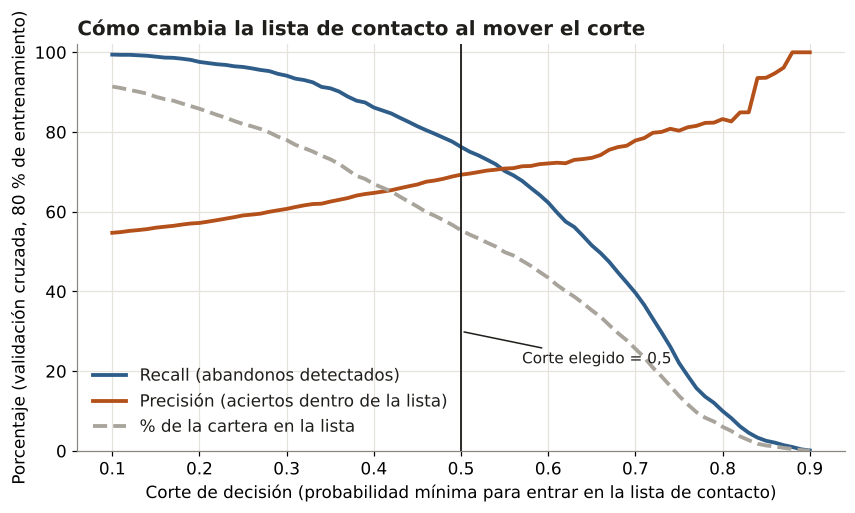

In [36]:
# ── 4B.4 Umbral de decisión: corte estándar de 0,5 (y cómo cambia la lista si se mueve) ──
UMBRAL = 0.5                                                         # Corte estándar: 50 % o más de probabilidad de abandonar
probabilidades_cv = oof[nombre_final]                                # Predicciones fuera de muestra del 80 % (validación cruzada)
filas_umbral = []
for umbral in np.round(np.arange(0.10, 0.91, 0.01), 2):              # Se prueba cada corte de 0,10 a 0,90 (solo para mostrar el escenario)
    lista = (probabilidades_cv >= umbral).astype(int)                # 1 = el cliente entra en la lista de contacto
    filas_umbral.append({"umbral": umbral, "recall": recall_score(y_train, lista),
                         "precision": precision_score(y_train, lista), "pct_contactados": lista.mean()})
tabla_umbral = pd.DataFrame(filas_umbral)
fila_umbral = tabla_umbral[tabla_umbral["umbral"] == UMBRAL].iloc[0]  # La fila del corte elegido (0,5)
print(f"Umbral elegido: {UMBRAL:.2f} | en validación cruzada: Recall {fila_umbral['recall']*100:.1f} %, "
      f"Precisión {fila_umbral['precision']*100:.1f} %, lista = {fila_umbral['pct_contactados']*100:.1f} % de la cartera")

fig, eje = plt.subplots(figsize=(9, 4.8))
eje.plot(tabla_umbral["umbral"], tabla_umbral["recall"] * 100, color=AZUL, lw=2.5, label="Recall (abandonos detectados)")
eje.plot(tabla_umbral["umbral"], tabla_umbral["precision"] * 100, color=NARANJA, lw=2.5, label="Precisión (aciertos dentro de la lista)")
eje.plot(tabla_umbral["umbral"], tabla_umbral["pct_contactados"] * 100, color=GRIS, lw=2.5, ls="--", label="% de la cartera en la lista")
eje.axvline(UMBRAL, color=TINTA, lw=1.2)
eje.annotate(f"Corte elegido = {UMBRAL:.1f}".replace(".", ","), xy=(UMBRAL, 30), xytext=(UMBRAL + 0.07, 22), fontsize=10,
             arrowprops=dict(arrowstyle="-", color=TINTA))
eje.set_xlabel("Corte de decisión (probabilidad mínima para entrar en la lista de contacto)")
eje.set_ylabel("Porcentaje (validación cruzada, 80 % de entrenamiento)")
eje.set_title("Cómo cambia la lista de contacto al mover el corte")
eje.set_ylim(0, 102); eje.legend(loc="lower left", frameon=False)
fig.savefig("figures/figC1_umbral.png"); plt.show()
# Lectura: al subir el corte la lista se achica y la precisión sube, pero el Recall baja; al bajarlo pasa lo contrario.

**Qué concluimos:** con el corte de 0,5, en validación cruzada la lista incluye al **55,4 % de la cartera**, detecta al **76,3 %** de quienes abandonan (Recall) y acierta en el **69,3 %** de los clientes que contacta (Precisión). Si Marketing quisiera detectar más abandonos, puede bajar el corte, a costa de contactar a más clientes (ver la figura).

## Etapa 5 · Evaluación
**Fase CRISP-DM: 5 – Evaluación.**

Acá se abre **por primera y única vez el 20 % de prueba**. Hasta este punto el modelo final, sus hiperparámetros y el umbral quedaron fijados solo con el 80 %. Orden de la etapa:

1. **5.1** Comparar baseline y XGBoost en el 20 % de prueba con ROC-AUC, PR-AUC, Recall y Precisión, y mostrar la matriz de confusión (Figura 10).
2. **5.2** Curvas ROC y Precisión-Recall.
3. **5.3** Lectura de negocio: captura por decil.
4. **5.4** ¿La mejora sobre el baseline es distinguible del azar? (bootstrap).
5. **5.5** Qué impulsa el abandono (SHAP).
6. **5.6** Cruce con los segmentos: quiénes son, a quién contactar primero y si el modelo sirve dentro de cada segmento (Figura 13).

**Cómo leer las métricas:** la **ROC-AUC** y la **PR-AUC** evalúan la lista completa de probabilidades y **no dependen del umbral** (azar: 0,50 y la tasa de churn observada, respectivamente). El **Recall** y la **Precisión** sí dependen del umbral.

In [37]:
# ── 5.1 ÚNICA lectura del 20 % de prueba: puntajes de cada candidato ──
puntajes_test = {"Regla por Recencia": X_test["Recencia"].values,                                   # Sin entrenar
                 "Regresión logística": busqueda_lr.predict_proba(X_test)[:, 1],                    # Baseline (ya entrenado con todo el 80 %)
                 "XGBoost": busqueda_xgb.predict_proba(X_test)[:, 1]}                               # Modelo
puntaje_final = puntajes_test[nombre_final]                                                         # Puntaje del modelo elegido en 4B.3

def captura_por_decil(real, puntaje, grupos=10):
    # Ordena a los clientes de mayor a menor riesgo, los parte en 10 grupos iguales y cuenta cuántos abandonos hay en cada uno
    t = pd.DataFrame({"real": np.asarray(real), "puntaje": np.asarray(puntaje)}).sort_values("puntaje", ascending=False).reset_index(drop=True)
    t["decil"] = (np.arange(len(t)) * grupos // len(t)) + 1                                         # 1 = el 10 % de mayor riesgo
    g = t.groupby("decil").agg(clientes=("real", "size"), abandonan=("real", "sum"))
    g["tasa_churn_observada"] = g["abandonan"] / g["clientes"]
    g["captura_acumulada"] = g["abandonan"].cumsum() / t["real"].sum()                              # % de TODOS los abandonos que quedan en la lista
    g["lift_acumulado"] = g["captura_acumulada"] / (g["clientes"].cumsum() / len(t))                # Cuántas veces mejor que contactar al azar
    return g

filas_test = {}
for nombre, puntaje in puntajes_test.items():
    g = captura_por_decil(y_test, puntaje)
    filas_test[nombre] = {"ROC-AUC": roc_auc_score(y_test, puntaje), "PR-AUC": average_precision_score(y_test, puntaje),
                          "captura al contactar al 10 %": g.loc[1, "captura_acumulada"], "captura al contactar al 20 %": g.loc[2, "captura_acumulada"]}
comparacion_test = pd.DataFrame(filas_test).T
comparacion_test.round(3).to_csv("results/f2_comparacion_test.csv")

# Modelo final con el umbral fijado en 4B.4: Recall, Precisión y tamaño de la lista
lista_test = (puntaje_final >= UMBRAL).astype(int)
tn = int(((lista_test == 0) & (y_test == 0)).sum()); fp = int(((lista_test == 1) & (y_test == 0)).sum())
fn = int(((lista_test == 0) & (y_test == 1)).sum()); tp = int(((lista_test == 1) & (y_test == 1)).sum())
metricas_umbral = {"umbral": UMBRAL, "Recall": recall_score(y_test, lista_test), "Precisión": precision_score(y_test, lista_test),
                   "F1": f1_score(y_test, lista_test), "% de la cartera en la lista": lista_test.mean(), "tasa de churn observada (test)": y_test.mean(),
                   "verdaderos positivos": tp, "falsos positivos": fp, "falsos negativos": fn, "verdaderos negativos": tn}
pd.Series(metricas_umbral).to_csv("results/f2_metricas_umbral_test.csv", header=["valor"])
print(f"Modelo final: {nombre_final} · umbral {UMBRAL:.2f} · Recall {metricas_umbral['Recall']*100:.1f} % · Precisión {metricas_umbral['Precisión']*100:.1f} % "
      f"· lista = {metricas_umbral['% de la cartera en la lista']*100:.1f} % de la cartera · tasa de churn observada en el test {y_test.mean()*100:.1f} %")
print(f"Matriz de confusión (clientes): detectados {tp} · no detectados {fn} · contactados de más {fp} · correctamente fuera de la lista {tn}")
comparacion_test.round(3)

Modelo final: XGBoost · umbral 0.50 · Recall 73.8 % · Precisión 69.5 % · lista = 53.4 % de la cartera · tasa de churn observada en el test 50.3 %
Matriz de confusión (clientes): detectados 321 · no detectados 114 · contactados de más 141 · correctamente fuera de la lista 289


,ROC-AUC,PR-AUC,captura al contactar al 10 %,captura al contactar al 20 %
Regla por Recencia,0.719,0.682,0.143,0.285
Regresión logística,0.777,0.735,0.159,0.310
XGBoost,0.782,0.750,0.166,0.315


**Qué concluimos:** en el 20 % de prueba, **XGBoost obtiene ROC-AUC 0,782 y PR-AUC 0,750**, contra 0,777 y 0,735 de la regresión logística y 0,719 y 0,682 de la regla por Recencia. Con el corte de 0,5 el modelo **detecta a 321 de los 435 clientes que abandonan (Recall 73,8 %)**, con Precisión de 69,5 %; para eso hay que contactar a 462 clientes (**53,4 % de la cartera**), de los cuales 141 se habrían quedado igual. Con clientes que el modelo no vio, el Recall baja un poco respecto de la validación cruzada (76,3 %), pero el orden se mantiene.

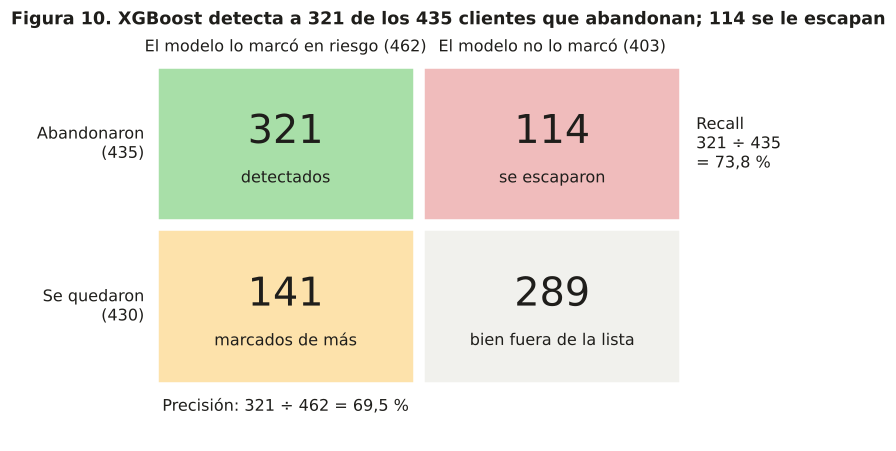

In [38]:
# ── 5.1b Matriz de confusión del modelo final con el corte de 0,5 (Figura 10) ──
# Cada casillero cuenta clientes del 20 % de prueba: filas = lo que pasó de verdad, columnas = lo que dijo el modelo.
matriz = np.array([[tp, fn], [fp, tn]])                                   # [[detectados, escapados], [marcados de más, bien fuera de la lista]]
etiquetas_casilla = [["detectados", "se escaparon"], ["marcados de más", "bien fuera de la lista"]]
colores_casilla = [["#a8dfa8", "#f0bcbc"], ["#fde2ab", "#f1f1ed"]]         # Verde: acierto útil · rojo: lo más grave · amarillo: esfuerzo de más · gris: acierto neutro
fig, eje = plt.subplots(figsize=(8.6, 4.8))
for f in range(2):
    for k in range(2):
        eje.add_patch(plt.Rectangle((k, 1 - f), 0.96, 0.94, color=colores_casilla[f][k], ec="white"))
        eje.text(k + 0.48, 1 - f + 0.54, f"{matriz[f, k]}", ha="center", va="center", fontsize=26, color=TINTA)
        eje.text(k + 0.48, 1 - f + 0.26, etiquetas_casilla[f][k], ha="center", va="center", fontsize=10.5, color=TINTA)
eje.set_xlim(-0.55, 2.2); eje.set_ylim(-0.35, 2.15); eje.axis("off")
eje.text(0.48, 2.04, f"El modelo lo marcó en riesgo ({tp + fp})", ha="center", fontsize=10.5)
eje.text(1.48, 2.04, f"El modelo no lo marcó ({fn + tn})", ha="center", fontsize=10.5)
eje.text(-0.05, 1.47, f"Abandonaron\n({tp + fn})", ha="right", va="center", fontsize=10.5)
eje.text(-0.05, 0.47, f"Se quedaron\n({fp + tn})", ha="right", va="center", fontsize=10.5)
eje.text(2.02, 1.47, f"Recall\n{tp} ÷ {tp + fn}\n= {metricas_umbral['Recall']*100:.1f} %".replace(".", ","), ha="left", va="center", fontsize=10.5)
eje.text(0.48, -0.17, f"Precisión: {tp} ÷ {tp + fp} = {metricas_umbral['Precisión']*100:.1f} %".replace(".", ","), ha="center", fontsize=10.5)
eje.set_title(f"Figura 10. {nombre_final} detecta a {tp} de los {tp + fn} clientes que abandonan; {fn} se le escapan", fontsize=11.5, loc="left")
fig.savefig("figures/fig10_matriz_confusion.png"); plt.show()
# Lectura: el casillero rojo (clientes que se van sin ser contactados) es el error más grave; el amarillo es esfuerzo de contacto de más.

**Qué concluimos:** con el corte de 0,5, el modelo marca en riesgo a 462 clientes: **321 abandonaron de verdad (detectados) y 141 se habrían quedado igual (contactados de más)**. Se le escapan 114 de los 435 clientes que abandonan. De ahí salen el **Recall de 73,8 %** (321 de 435) y la **Precisión de 69,5 %** (321 de 462).

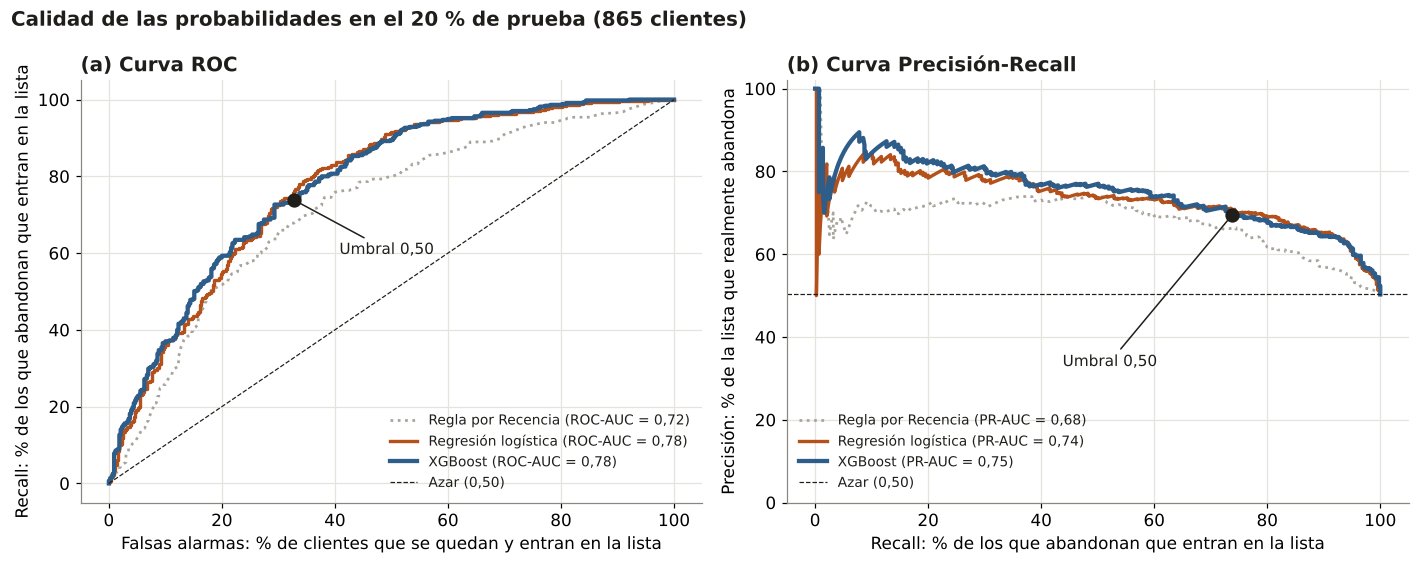

In [39]:
# ── 5.2 Curvas ROC y Precisión-Recall en el 20 % de prueba ──
fig, (eje_roc, eje_pr) = plt.subplots(1, 2, figsize=(13, 5.2))
estilos = {"Regla por Recencia": (GRIS, 1.8, ":"), "Regresión logística": (NARANJA, 2.2, "-"), "XGBoost": (AZUL, 2.8, "-")}

# (a) Curva ROC: eje X = falsas alarmas (clientes que se quedan marcados como abandono); eje Y = Recall
for nombre, puntaje in puntajes_test.items():
    falsas_alarmas, recall_c, _ = roc_curve(y_test, puntaje)
    color, ancho, trazo = estilos[nombre]
    eje_roc.plot(falsas_alarmas * 100, recall_c * 100, color=color, lw=ancho, ls=trazo, label=f"{nombre} (ROC-AUC = {roc_auc_score(y_test, puntaje):.2f})".replace(".", ","))
eje_roc.plot([0, 100], [0, 100], color=TINTA, lw=0.8, ls="--", label="Azar (0,50)")
fa_umbral = fp / (fp + tn) * 100                                     # Falsas alarmas con el umbral elegido
eje_roc.scatter([fa_umbral], [metricas_umbral["Recall"] * 100], s=70, color=TINTA, zorder=5)
eje_roc.annotate(f"Umbral {UMBRAL:.2f}".replace(".", ","), xy=(fa_umbral, metricas_umbral["Recall"] * 100), xytext=(fa_umbral + 8, metricas_umbral["Recall"] * 100 - 14),
                 fontsize=10, arrowprops=dict(arrowstyle="-", color=TINTA))
eje_roc.set_xlabel("Falsas alarmas: % de clientes que se quedan y entran en la lista")
eje_roc.set_ylabel("Recall: % de los que abandonan que entran en la lista")
eje_roc.set_title("(a) Curva ROC"); eje_roc.legend(loc="lower right", frameon=False, fontsize=9)

# (b) Curva Precisión-Recall: eje X = Recall; eje Y = Precisión (de los que marco, cuántos realmente se van)
for nombre, puntaje in puntajes_test.items():
    precision_c, recall_c, _ = precision_recall_curve(y_test, puntaje)
    color, ancho, trazo = estilos[nombre]
    eje_pr.plot(recall_c * 100, precision_c * 100, color=color, lw=ancho, ls=trazo, label=f"{nombre} (PR-AUC = {average_precision_score(y_test, puntaje):.2f})".replace(".", ","))
eje_pr.axhline(y_test.mean() * 100, color=TINTA, lw=0.8, ls="--", label=f"Azar ({y_test.mean():.2f})".replace(".", ","))
eje_pr.scatter([metricas_umbral["Recall"] * 100], [metricas_umbral["Precisión"] * 100], s=70, color=TINTA, zorder=5)
eje_pr.annotate(f"Umbral {UMBRAL:.2f}".replace(".", ","), xy=(metricas_umbral["Recall"] * 100, metricas_umbral["Precisión"] * 100),
                xytext=(metricas_umbral["Recall"] * 100 - 30, 33), fontsize=10, arrowprops=dict(arrowstyle="-", color=TINTA))
eje_pr.set_xlabel("Recall: % de los que abandonan que entran en la lista")
eje_pr.set_ylabel("Precisión: % de la lista que realmente abandona")
eje_pr.set_ylim(0, 102); eje_pr.set_title("(b) Curva Precisión-Recall"); eje_pr.legend(loc="lower left", frameon=False, fontsize=9)
fig.suptitle("Calidad de las probabilidades en el 20 % de prueba (865 clientes)", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(); fig.savefig("figures/figC2_curvas_roc_pr.png"); plt.show()
# Lectura: el modelo queda por encima del azar y de la regla por Recencia en todo el recorrido; el punto negro marca el umbral elegido.

**Qué concluimos:** las dos curvas del modelo y de la regresión logística **casi se superponen**, y las dos quedan **por encima de la regla por Recencia** y muy por encima del azar. El punto negro marca el corte 0,5: se paga con aproximadamente 33 % de falsas alarmas (141 de los 430 clientes que se quedaban igual entran en la lista).

Si contactamos al 20 % de mayor riesgo, detectamos al 31,5 % de los que realmente abandonan (lift 1,57),


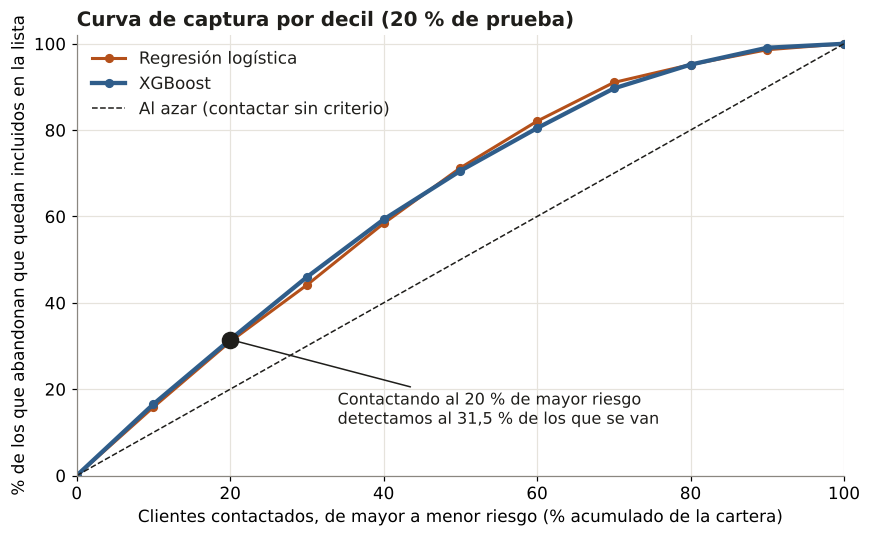

,clientes,abandonan,tasa_churn_observada,captura_acumulada,lift_acumulado
decil,,,,,
1,87,72,82.8,16.6,1.65
2,86,65,75.6,31.5,1.57
3,87,63,72.4,46.0,1.53
4,86,58,67.4,59.3,1.48
5,87,49,56.3,70.6,1.41
6,86,43,50.0,80.5,1.34
7,87,40,46.0,89.7,1.28
8,86,24,27.9,95.2,1.19
9,87,17,19.5,99.1,1.10


In [40]:
# ── 5.3 Lectura de negocio: captura por decil ──
# Se ordena a los clientes del 20 % de prueba de mayor a menor riesgo y se mide cuántos de los que realmente abandonan quedan en la lista.
captura_final = captura_por_decil(y_test, puntaje_final)
captura_final.round(4).to_csv("results/f2_captura_por_decil.csv")
captura_20 = captura_final.loc[2, "captura_acumulada"]; captura_10 = captura_final.loc[1, "captura_acumulada"]
print(f"Si contactamos al 20 % de mayor riesgo, detectamos al {captura_20*100:.1f} % de los que realmente abandonan (lift {captura_final.loc[2, 'lift_acumulado']:.2f}).".replace(".", ","))

fig, eje = plt.subplots(figsize=(9, 5.2))
cuantiles = np.arange(0, 101, 10)
for nombre, color, trazo in [("Regresión logística", NARANJA, "-"), ("XGBoost", AZUL, "-")]:
    g = captura_por_decil(y_test, puntajes_test[nombre])
    eje.plot(cuantiles, np.r_[0, g["captura_acumulada"].values * 100], color=color, lw=2.8 if nombre == nombre_final else 2, ls=trazo, marker="o", ms=5, label=nombre)
eje.plot([0, 100], [0, 100], color=TINTA, lw=1, ls="--", label="Al azar (contactar sin criterio)")
eje.scatter([20], [captura_20 * 100], s=110, color=TINTA, zorder=5)
eje.annotate(f"Contactando al 20 % de mayor riesgo\ndetectamos al {captura_20*100:.1f} % de los que se van".replace(".", ","), xy=(20, captura_20 * 100),
             xytext=(34, 12), fontsize=10.5, arrowprops=dict(arrowstyle="-", color=TINTA))
eje.set_xlabel("Clientes contactados, de mayor a menor riesgo (% acumulado de la cartera)")
eje.set_ylabel("% de los que abandonan que quedan incluidos en la lista")
eje.set_xlim(0, 100); eje.set_ylim(0, 102); eje.set_title("Curva de captura por decil (20 % de prueba)"); eje.legend(loc="upper left", frameon=False)
fig.savefig("figures/fig11_captura_decil.png"); plt.show()
# Lectura: cada punto es un decil; cuanto más arriba de la línea punteada, mejor ordena el modelo a los clientes.
captura_final.assign(tasa_churn_observada=lambda t: (t["tasa_churn_observada"] * 100).round(1),
                     captura_acumulada=lambda t: (t["captura_acumulada"] * 100).round(1), lift_acumulado=lambda t: t["lift_acumulado"].round(2))

**Qué concluimos (lectura de captura):** **si contactamos al 20 % de los clientes de mayor riesgo, detectamos al 31,5 % de los que realmente abandonan** (1,57 veces mejor que elegir al azar). Con el 10 % de mayor riesgo, capturamos 16,6 %: en ese decil abandonan 83 de cada 100 clientes, contra 5 de cada 100 en el de menor riesgo. Para capturar a 8 de cada 10 de los que se van hay que llegar al 60 % de la cartera. **Es un modelo útil para ordenar prioridades, no para predecir con certeza a quién se pierde:** en este negocio casi la mitad de los clientes no vuelve a comprar en 3 meses, así que el margen de mejora sobre el azar es acotado.

In [41]:
# ── 5.4 ¿La mejora sobre el baseline es distinguible del azar? Bootstrap pareado (1.000 remuestreos del 20 % de prueba) ──
# Se remuestrean clientes del test CON reposición y se calcula la diferencia entre el modelo final y la regresión logística en cada remuestreo.
generador = np.random.default_rng(RANDOM_STATE)
real_t = y_test.values
dif_roc, dif_pr, cap20 = [], [], []
if nombre_final != "Regresión logística":
    for _ in range(1000):
        i = generador.integers(0, len(real_t), len(real_t))          # Clientes elegidos al azar (con reposición)
        if real_t[i].min() == real_t[i].max(): continue              # Salvaguarda: hacen falta las dos clases
        dif_roc.append(roc_auc_score(real_t[i], puntaje_final[i]) - roc_auc_score(real_t[i], puntajes_test["Regresión logística"][i]))
        dif_pr.append(average_precision_score(real_t[i], puntaje_final[i]) - average_precision_score(real_t[i], puntajes_test["Regresión logística"][i]))
        cap20.append(captura_por_decil(real_t[i], puntaje_final[i]).loc[2, "captura_acumulada"])
    intervalos = pd.DataFrame({"diferencia mediana": [np.median(dif_roc), np.median(dif_pr)],
                               "IC 95 % inferior": [np.percentile(dif_roc, 2.5), np.percentile(dif_pr, 2.5)],
                               "IC 95 % superior": [np.percentile(dif_roc, 97.5), np.percentile(dif_pr, 97.5)]}, index=["ROC-AUC", "PR-AUC"])
    intervalos.round(4).to_csv("results/f2_bootstrap_vs_baseline.csv")
    print(f"IC 95 % de la captura al contactar al 20 %: {np.percentile(cap20, 2.5)*100:.1f} % a {np.percentile(cap20, 97.5)*100:.1f} %".replace(".", ","))
    display(intervalos.round(4))
else:
    print("El modelo final es el baseline: no hay comparación pareada.")

IC 95 % de la captura al contactar al 20 %: 29,3 % a 34,1 %


,diferencia mediana,IC 95 % inferior,IC 95 % superior
ROC-AUC,0.0046,-0.0061,0.0164
PR-AUC,0.0130,-0.0127,0.0404


**Qué concluimos:** la mejora de XGBoost sobre la regresión logística es de **+0,005 en ROC-AUC (IC 95 %: de −0,006 a +0,016) y +0,013 en PR-AUC (de −0,013 a +0,040)**. Los dos intervalos incluyen el cero: **la diferencia no se distingue del azar**. La captura al contactar al 20 % de la cartera tiene un intervalo de 29,3 % a 34,1 %. En el informe se dice con esas palabras: el modelo supera con claridad a la regla por Recencia, pero **no se puede afirmar que supere a la regresión logística**; XGBoost se mantiene como modelo final por la regla de selección fijada de antemano, y la regresión logística es una alternativa igual de defendible, y más simple de explicar.

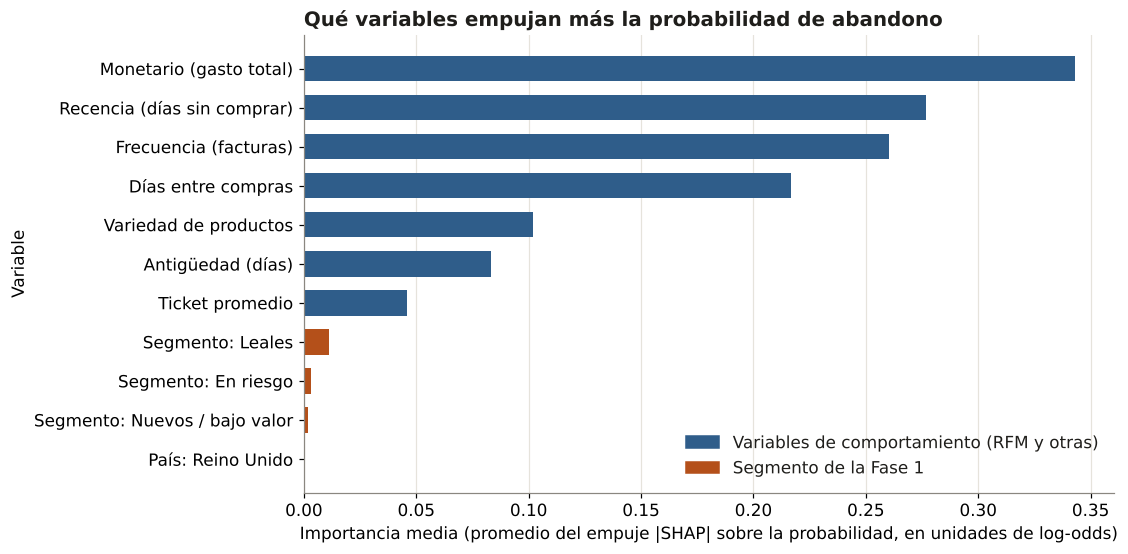

,importancia_shap,correlacion_valor_vs_empuje
Monetario,0.343,-0.367
Recencia,0.277,0.849
Frecuencia,0.260,-0.558
dias_entre_compras,0.217,0.953
variedad_productos,0.102,-0.479
antiguedad_dias,0.083,-0.088
ticket_promedio,0.046,0.002
seg_leales,0.011,0.829
seg_en_riesgo,0.003,0.773
seg_nuevos_bajo_valor,0.002,0.021


In [42]:
# ── 5.5 Qué impulsa el abandono: importancia de variables con SHAP ──
# SHAP reparte, para cada cliente, cuánto empuja cada variable su probabilidad hacia arriba o hacia abajo. Se promedia el tamaño del empuje.
import shap
explicador = shap.TreeExplainer(busqueda_xgb.best_estimator_)        # Explicador específico para modelos de árboles
valores_shap = explicador.shap_values(X_test)                        # Una fila por cliente, una columna por variable
importancia = pd.Series(np.abs(valores_shap).mean(axis=0), index=X_test.columns).sort_values(ascending=True)   # Promedio del tamaño del empuje

# Dirección del efecto: correlación entre el valor de la variable y su empuje (+ = más valor, más riesgo)
direccion = pd.Series({c: np.corrcoef(X_test[c].values, valores_shap[:, list(X_test.columns).index(c)])[0, 1] for c in X_test.columns})
NOMBRES_LEGIBLES = {"Recencia": "Recencia (días sin comprar)", "Frecuencia": "Frecuencia (facturas)", "Monetario": "Monetario (gasto total)",
                    "ticket_promedio": "Ticket promedio", "antiguedad_dias": "Antigüedad (días)", "dias_entre_compras": "Días entre compras",
                    "variedad_productos": "Variedad de productos", "pais_reino_unido": "País: Reino Unido",
                    "seg_leales": "Segmento: Leales", "seg_nuevos_bajo_valor": "Segmento: Nuevos / bajo valor", "seg_en_riesgo": "Segmento: En riesgo"}
tabla_shap = pd.DataFrame({"importancia_shap": importancia, "correlacion_valor_vs_empuje": direccion.loc[importancia.index]}).sort_values("importancia_shap", ascending=False)
tabla_shap.round(4).to_csv("results/f2_importancia_shap.csv")

fig, eje = plt.subplots(figsize=(9.5, 5.4))
eje.barh([NOMBRES_LEGIBLES[c] for c in importancia.index], importancia.values, color=[NARANJA if c.startswith("seg_") else AZUL for c in importancia.index], height=0.65)
eje.set_xlabel("Importancia media (promedio del empuje |SHAP| sobre la probabilidad, en unidades de log-odds)")
eje.set_ylabel("Variable")
eje.set_title("Qué variables empujan más la probabilidad de abandono")
from matplotlib.patches import Patch                                  # Para la leyenda de colores
eje.legend(handles=[Patch(color=AZUL, label="Variables de comportamiento (RFM y otras)"), Patch(color=NARANJA, label="Segmento de la Fase 1")], loc="lower right", frameon=False)
eje.grid(axis="y", visible=False)
fig.savefig("figures/fig12_shap_importancia.png"); plt.show()
# Lectura: las barras más largas son las variables que más mueven la probabilidad; la tabla indica en qué dirección lo hacen.
tabla_shap.round(3)

**Qué concluimos:** las variables que más mueven la probabilidad son **el gasto total (Monetario), la Recencia, la Frecuencia y los días entre compras**. **Más días sin comprar o entre compras suben el riesgo** (correlación entre el valor de la variable y su empuje: +0,85 y +0,95); **más gasto, más facturas y más variedad de productos lo bajan** (−0,37, −0,56 y −0,48). **El segmento de la Fase 1 casi no aporta (importancia máxima 0,011)**: ya está resumido en R, F y M, que el modelo usa directamente. SHAP muestra *qué variables usa el modelo*, no qué *causa* el abandono.

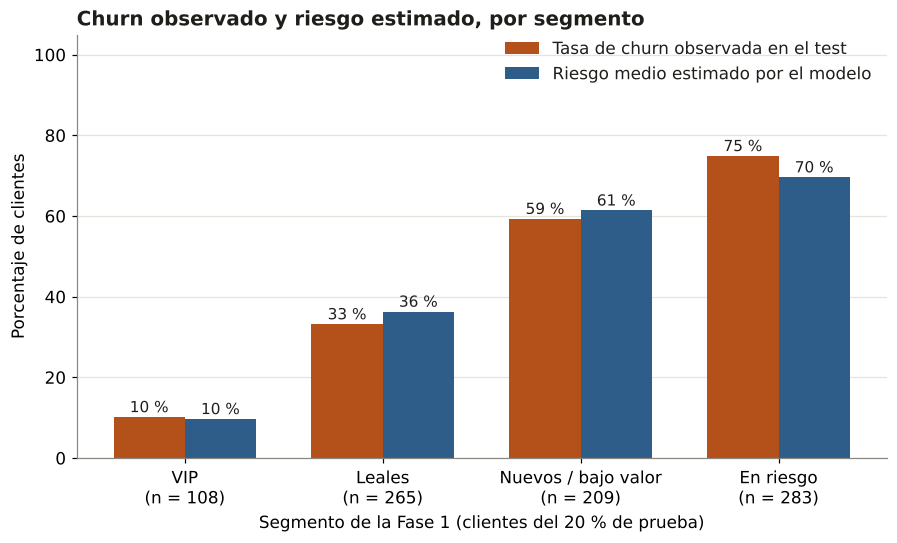

Ordenar solo por segmento: ROC-AUC 0,747 · PR-AUC 0,707 | modelo final: ROC-AUC 0,782 · PR-AUC 0,750


,clientes,churn_observado,riesgo_medio_estimado,pct_en_la_lista
segmento,,,,
VIP,108,10.2,9.700000,0.0
Leales,265,33.2,36.299999,11.7
Nuevos / bajo valor,209,59.3,61.400002,78.5
En riesgo,283,74.9,69.599998,94.3


In [43]:
# ── 5.6 Cruce con los segmentos: la Fase 1 dice QUIÉNES son; la Fase 2 dice A QUIÉN contactar primero ──
segmento_test = segmento_f2.loc[ids_test]
cruce = (pd.DataFrame({"segmento": segmento_test.values, "abandono": y_test.values, "riesgo": puntaje_final, "en_lista": lista_test})
         .groupby("segmento").agg(clientes=("abandono", "size"), churn_observado=("abandono", "mean"),
                                  riesgo_medio_estimado=("riesgo", "mean"), pct_en_la_lista=("en_lista", "mean")).loc[ORDEN_SEGMENTOS])
cruce.round(4).to_csv("results/f2_cruce_segmentos.csv")

fig, eje = plt.subplots(figsize=(9.5, 5))
posicion = np.arange(len(ORDEN_SEGMENTOS)); ancho = 0.36
eje.bar(posicion - ancho / 2, cruce["churn_observado"] * 100, width=ancho, color=NARANJA, label="Tasa de churn observada en el test")
eje.bar(posicion + ancho / 2, cruce["riesgo_medio_estimado"] * 100, width=ancho, color=AZUL, label="Riesgo medio estimado por el modelo")
for p, (obs, est) in enumerate(zip(cruce["churn_observado"] * 100, cruce["riesgo_medio_estimado"] * 100)):
    eje.text(p - ancho / 2, obs + 1.2, f"{obs:.0f} %", ha="center", fontsize=10); eje.text(p + ancho / 2, est + 1.2, f"{est:.0f} %", ha="center", fontsize=10)
eje.set_xticks(posicion, [f"{s}\n(n = {int(n)})" for s, n in zip(cruce.index, cruce["clientes"])])
eje.set_xlabel("Segmento de la Fase 1 (clientes del 20 % de prueba)"); eje.set_ylabel("Porcentaje de clientes")
eje.set_ylim(0, 105); eje.set_title("Churn observado y riesgo estimado, por segmento"); eje.legend(loc="upper right", frameon=False, bbox_to_anchor=(1, 1.02))
eje.grid(axis="x", visible=False)
fig.savefig("figures/figC3_cruce_segmentos.png"); plt.show()

# ¿Cuánto aporta el modelo además del segmento? Comparación: ordenar solo por la tasa de churn de cada segmento (calculada con entrenamiento)
tasa_segmento_train = pd.DataFrame({"s": segmento_f2.loc[ids_train].values, "y": y_train.values}).groupby("s")["y"].mean()
solo_segmento = segmento_test.map(tasa_segmento_train).values + 1e-9 * np.random.default_rng(RANDOM_STATE).random(len(segmento_test))   # Desempate mínimo
print(f"Ordenar solo por segmento: ROC-AUC {roc_auc_score(y_test, solo_segmento):.3f} · PR-AUC {average_precision_score(y_test, solo_segmento):.3f} "
      f"| modelo final: ROC-AUC {roc_auc_score(y_test, puntaje_final):.3f} · PR-AUC {average_precision_score(y_test, puntaje_final):.3f}".replace(".", ","))
cruce.assign(churn_observado=(cruce["churn_observado"] * 100).round(1), riesgo_medio_estimado=(cruce["riesgo_medio_estimado"] * 100).round(1),
             pct_en_la_lista=(cruce["pct_en_la_lista"] * 100).round(1))

**Qué concluimos:** el riesgo estimado **sigue el orden de los segmentos y se parece al churn observado**: VIP 10 %, Leales 33 % (36 % estimado), Nuevos / bajo valor 59 % (61 %) y En riesgo 75 % (70 %). Con el corte de 0,5 la lista incluye al **0 % de los VIP, 11,7 % de los Leales, 78,5 % de los Nuevos y 94,3 % de los En riesgo**. **Cada fase responde una pregunta distinta:** la segmentación dice quiénes son los clientes y qué acción corresponde; el modelo dice a quién contactar primero *dentro* de cada segmento. Y hay una advertencia: **ordenar solo por la tasa de churn del segmento ya da ROC-AUC 0,747 y PR-AUC 0,707, contra 0,782 y 0,750 del modelo**: la segmentación de la Fase 1 ya contiene gran parte de la señal, y el modelo agrega una mejora moderada.

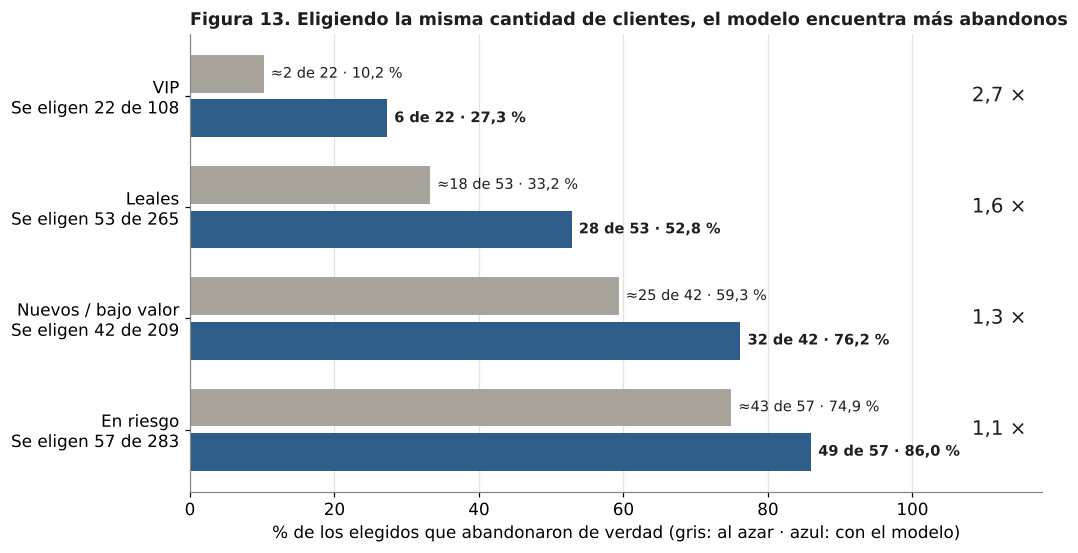

                     clientes  abandonan  churn_observado  elegidos_20pct  aciertos_modelo  acierto_modelo  aciertos_azar_esperados  veces_mejor_que_azar
segmento                                                                                                                                                 
VIP                       108         11            0.102              22                6           0.273                    2.241                 2.678
Leales                    265         88            0.332              53               28           0.528                   17.600                 1.591
Nuevos / bajo valor       209        124            0.593              42               32           0.762                   24.919                 1.284
En riesgo                 283        212            0.749              57               49           0.860                   42.700                 1.148


In [44]:
# ── 5.6b ¿El modelo sirve DENTRO de cada segmento? (simulación sobre el 20 % de prueba; Figura 13) ──
# Pregunta: si la campaña se arma segmento por segmento, ¿el modelo elige mejor que el azar?
# Método: dentro de cada segmento se ordena a los clientes por riesgo, se eligen el 20 % de mayor riesgo y se cuenta cuántos abandonaron de verdad.
# Referencia: elegir la MISMA cantidad de clientes al azar encuentra abandonos en proporción a la tasa de churn del segmento.
# Es una simulación con datos que ya ocurrieron: no se contactó a nadie. No se reajusta nada del modelo.
datos_segmento = pd.DataFrame({"segmento": segmento_test.values, "abandono": y_test.values, "riesgo": np.asarray(puntaje_final)}, index=X_test.index)

filas_dentro = []
for nombre_segmento in ORDEN_SEGMENTOS:
    d = datos_segmento[datos_segmento["segmento"] == nombre_segmento]                       # Clientes del 20 % de prueba que son de este segmento
    n = len(d); elegidos = int(round(0.20 * n))                                             # Se eligen el 20 % de los clientes del segmento
    lista = d.sort_values("riesgo", ascending=False, kind="stable").head(elegidos)         # Los de mayor riesgo DENTRO del segmento
    aciertos = int(lista["abandono"].sum())                                                 # Cuántos de los elegidos abandonaron de verdad
    tasa_segmento = d["abandono"].mean()                                                    # Tasa de churn observada del segmento = lo esperable al azar
    filas_dentro.append({"segmento": nombre_segmento, "clientes": n, "abandonan": int(d["abandono"].sum()),
                         "churn_observado": tasa_segmento, "elegidos_20pct": elegidos,
                         "aciertos_modelo": aciertos, "acierto_modelo": aciertos / elegidos,
                         "aciertos_azar_esperados": elegidos * tasa_segmento, "acierto_azar": tasa_segmento,
                         "veces_mejor_que_azar": (aciertos / elegidos) / tasa_segmento})
dentro = pd.DataFrame(filas_dentro).set_index("segmento")
dentro.round(4).to_csv("results/f2_captura_dentro_de_segmento.csv")

# Gráfico: por segmento, dos barras (azar y modelo) con el porcentaje de los elegidos que abandonaron de verdad
fig, eje = plt.subplots(figsize=(10, 5.4))
base_y = np.arange(len(ORDEN_SEGMENTOS))[::-1] * 1.0
for yy, (nombre_segmento, fila) in zip(base_y, dentro.iterrows()):
    eje.barh(yy + 0.2, fila["acierto_azar"] * 100, height=0.34, color=GRIS)                 # Al azar
    eje.barh(yy - 0.2, fila["acierto_modelo"] * 100, height=0.34, color=AZUL)               # Con el modelo
    eje.text(fila["acierto_azar"] * 100 + 1, yy + 0.2, f"≈{fila['aciertos_azar_esperados']:.0f} de {int(fila['elegidos_20pct'])} · {fila['acierto_azar']*100:.1f} %".replace(".", ","), va="center", fontsize=9.5)
    eje.text(fila["acierto_modelo"] * 100 + 1, yy - 0.2, f"{int(fila['aciertos_modelo'])} de {int(fila['elegidos_20pct'])} · {fila['acierto_modelo']*100:.1f} %".replace(".", ","), va="center", fontsize=9.5, fontweight="bold")
    eje.text(112, yy, f"{fila['veces_mejor_que_azar']:.1f} ×".replace(".", ","), va="center", ha="center", fontsize=13)
eje.set_yticks(base_y, [f"{s}\nSe eligen {int(e)} de {int(n)}" for s, e, n in zip(dentro.index, dentro["elegidos_20pct"], dentro["clientes"])])
eje.set_xlim(0, 118); eje.set_xticks([0, 20, 40, 60, 80, 100])
eje.set_xlabel("% de los elegidos que abandonaron de verdad (gris: al azar · azul: con el modelo)")
eje.set_title("Figura 13. Eligiendo la misma cantidad de clientes, el modelo encuentra más abandonos", loc="left", fontsize=11.5)
eje.grid(axis="y", visible=False)
fig.savefig("figures/fig13_dentro_de_segmento.png"); plt.show()

pd.set_option("display.width", 200)
print(dentro[["clientes", "abandonan", "churn_observado", "elegidos_20pct", "aciertos_modelo", "acierto_modelo", "aciertos_azar_esperados", "veces_mejor_que_azar"]].round(3).to_string())

**Qué concluimos:** **el modelo sirve dentro de cada segmento.** Al elegir el 20 % de mayor riesgo de cada segmento (22 de 108 VIP, 53 de 265 Leales, 42 de 209 Nuevos / bajo valor y 57 de 283 En riesgo), abandonan de verdad el 27,3 % en los VIP (10,2 % al azar: **2,7 veces más**), el 52,8 % en los Leales (33,2 %: **1,6 veces**), el 76,2 % en los Nuevos (59,3 %: **1,3 veces**) y el 86,0 % en los En riesgo (74,9 %: **1,1 veces**). La ventaja es grande donde el abandono es poco frecuente y chica donde casi todos se van, porque ahí cualquier lista acierta mucho. En los VIP son solo 22 elegidos y 11 abandonos, así que esa cifra es orientativa. Es una simulación con datos que ya ocurrieron: el modelo anticipa el abandono, no lo causa.

In [45]:
# ── 5.7 Resumen de la Fase 2 (todas las cifras del informe salen de acá) ──
resumen_fase2 = {"modelo_final": nombre_final, "umbral": UMBRAL,
                 "clientes_train": int(len(y_train)), "clientes_test": int(len(y_test)),
                 "churn_observado_total": float(etiqueta.mean()), "churn_observado_test": float(y_test.mean()),
                 "test": {k: float(v) for k, v in comparacion_test.loc[nombre_final].items()},
                 "test_baseline_lr": {k: float(v) for k, v in comparacion_test.loc["Regresión logística"].items()},
                 "test_regla_recencia": {k: float(v) for k, v in comparacion_test.loc["Regla por Recencia"].items()},
                 "en_umbral": {k: float(v) for k, v in metricas_umbral.items()},
                 "dentro_de_segmento": {s: {k: float(v) for k, v in dentro.loc[s, ["elegidos_20pct", "aciertos_modelo", "veces_mejor_que_azar"]].items()} for s in dentro.index}}
json.dump(resumen_fase2, open("results/f2_resumen.json", "w"), indent=1, ensure_ascii=False)
print(json.dumps(resumen_fase2, indent=1, ensure_ascii=False))

{
 "modelo_final": "XGBoost",
 "umbral": 0.5,
 "clientes_train": 3459,
 "clientes_test": 865,
 "churn_observado_total": 0.5030064754856615,
 "churn_observado_test": 0.5028901734104047,
 "test": {
  "ROC-AUC": 0.782071638599305,
  "PR-AUC": 0.7497944096086566,
  "captura al contactar al 10 %": 0.16551724137931034,
  "captura al contactar al 20 %": 0.31494252873563217
 },
 "test_baseline_lr": {
  "ROC-AUC": 0.7773483025928897,
  "PR-AUC": 0.7354734124232687,
  "captura al contactar al 10 %": 0.15862068965517243,
  "captura al contactar al 20 %": 0.3103448275862069
 },
 "test_regla_recencia": {
  "ROC-AUC": 0.7185137663726275,
  "PR-AUC": 0.6817730340016435,
  "captura al contactar al 10 %": 0.1425287356321839,
  "captura al contactar al 20 %": 0.2850574712643678
 },
 "en_umbral": {
  "umbral": 0.5,
  "Recall": 0.7379310344827587,
  "Precisión": 0.6948051948051948,
  "F1": 0.7157190635451505,
  "% de la cartera en la lista": 0.5341040462427745,
  "tasa de churn observada (test)": 0.502890

## Etapa 6 · Cierre
**Fase CRISP-DM: 6 – Despliegue (recomendaciones y próximos pasos).** Es el mismo contenido que las secciones 5 a 7 del informe.

### Riesgos y limitaciones
- **Geografía.** El 91,1 % de los clientes es del Reino Unido. Los resultados no se generalizan a otros mercados sin validarlos.
- **Época del año.** El abandono se midió de septiembre a noviembre de 2011 (temporada alta) con una sola fecha de predicción. La tasa observada (50,3 %) puede ser distinta en otra época.
- **Efecto de las campañas.** El modelo mide qué tan bien ordena a los clientes, no si contactarlos cambia su decisión.
- **Ventaja sobre un modelo simple.** XGBoost no supera con claridad a la regresión logística (el bootstrap de 5.4 incluye el cero).
- **Metas de negocio.** +15 % de conversión, +10 % de LTV a 6 meses y +10 % de ROAS son metas de referencia, no resultados: el dataset no tiene datos de campañas y deben validarse con un piloto.

### Escalabilidad y próximos pasos
1. Reentrenar con varias fechas de predicción (ventanas móviles), para reducir el sesgo de temporada.
2. Sumar otros países cuando haya volumen suficiente.

### Ética y privacidad
- **Privacidad de los datos.** Dataset público, sin nombres ni direcciones. El Customer ID se reemplaza por un código aleatorio (`CLI_0001`, …) en orden aleatorio, y no se guarda la tabla de equivalencias.
- **Uso responsable de la segmentación.** Los segmentos sirven para personalizar mensajes y ofertas. No deben usarse para cobrar precios distintos por la misma compra ni para tratar peor a los clientes de bajo valor.
- **Sesgo por concentración geográfica.** El 91,1 % de los clientes es del Reino Unido, así que el modelo aprende sobre todo comportamiento británico. El país casi no pesa en el modelo (importancia de 0,001 en SHAP), pero eso no prueba que funcione igual en otros mercados: no hay datos suficientes para medirlo.

### Conclusiones
1. **Segmentar sirve.** K-Means separa a los clientes en cuatro grupos más claros y más estables que la regla tradicional por quintiles RFM, y cada grupo tiene una lectura de negocio clara.
2. **Se puede anticipar el abandono.** El modelo ordena a los clientes por riesgo mejor que una regla simple. Si contactamos al 20 % de mayor riesgo de toda la cartera, alcanzamos al 31,5 % de los que abandonan (137 de 435, con 173 contactos entre los 865 clientes de prueba). Si lo hacemos dentro de cada segmento, encontramos más abandonos que eligiendo al azar la misma cantidad de clientes: 2,7 veces más en los VIP, 1,6 en los Leales, 1,3 en los Nuevos y 1,1 en los En riesgo.
3. **Las dos fases se complementan.** La segmentación dice quiénes son los clientes y el modelo dice a quién contactar primero.

### Recomendaciones
1. Aplicar las acciones por segmento (Tabla 6 del informe) y empezar por los segmentos de mayor abandono (En riesgo y Nuevos / bajo valor).
2. Hacer un piloto A/B con grupo de control antes de comprometer las metas de +15 % de conversión, +10 % de LTV y +10 % de ROAS.
3. Mirar el riesgo junto con el valor del cliente, para no descuidar a los VIP.
4. Recalcular segmentos y riesgo cada mes, con revisión humana de la lista.


## Anexo del cuaderno · Mapa informe ↔ cuaderno
Dónde sale cada figura y tabla del informe. Las salidas se guardan en `figures/` y `results/`.

| Informe | Qué muestra | Sección del cuaderno | Archivo de salida |
|---|---|---|---|
| Figura 1 | EDA: facturación mensual, gasto por cliente, clientes por país | 3.2 | `figures/fig01_eda.png` |
| Figura 2 | Meses que usa cada fase (esquema) | Parámetros de la Etapa 0 | (esquema; las fechas salen de la celda de parámetros) |
| Figura 3 | Asimetría y rango de R, F y M antes y después de transformar y escalar | 3.4 y 4A.3 | `results/rfm_asimetria.csv`, `results/valores_extremos_80.csv` |
| Figura 4 | Abandono observado y grupo de un solo día de compra | 3.5 | `figures/fig04_abandono_un_solo_dia.png`, `results/un_solo_dia_resumen.csv` |
| Figura 5 | Búsqueda de K (codo, Silhouette, Davies-Bouldin) | 4A.4 | `figures/fig05_busqueda_k.png`, `results/busqueda_k_80.csv` |
| Figura 6 | Los cuatro segmentos | 4A.5 | `figures/fig06_perfil_segmentos.png`, `results/perfil_segmentos_80.csv` |
| Figura 7 | Segmentos del baseline por quintiles RFM | 4A.6 | `figures/fig07_baseline_quintiles.png` |
| Figura 8 | K-Means contra quintiles RFM | 4A.6 | `figures/fig08_kmeans_vs_quintiles.png`, `results/comparacion_kmeans_vs_quintiles.csv` |
| Figura 9 | UMAP de los segmentos (80 % y 20 %) | 4A.8 | `figures/fig09_umap_segmentos.png` |
| Figura 10 | Matriz de confusión de XGBoost | 5.1b | `figures/fig10_matriz_confusion.png`, `results/f2_metricas_umbral_test.csv` |
| Figura 11 | Captura de abandonos al contactar al 20 % de mayor riesgo | 5.3 | `figures/fig11_captura_decil.png`, `results/f2_captura_por_decil.csv` |
| Figura 12 | Importancia de variables (SHAP) | 5.5 | `figures/fig12_shap_importancia.png`, `results/f2_importancia_shap.csv` |
| Figura 13 | El modelo dentro de cada segmento | 5.6b | `figures/fig13_dentro_de_segmento.png`, `results/f2_captura_dentro_de_segmento.csv` |
| Figura A1 | Embudo de limpieza | 3.1 | `figures/figA1_embudo_limpieza.png`, `results/embudo_limpieza.csv` |
| Figura A2 | Churn observado según días de compra | 3.5 | `results/un_solo_dia_resumen.csv` |
| Figura A3 | R, F y M antes y después del logaritmo | 3.4 | `figures/figA3_rfm_logaritmo.png` |
| Tabla 1 | Hallazgos de calidad de datos | Etapa 2 | salidas de 2.1 a 2.4 |
| Tabla 2 | Variables de cada cliente | 3.3 y 3.5 | `diccionario_de_datos.md` |
| Tabla 3 | Estabilidad con el 20 % de prueba | 4A.7 | `results/estabilidad_holdout.csv` |
| Tabla 4 | Validación cruzada de 5 grupos | 4B.3 | `results/f2_validacion_cruzada.csv` |
| Tabla 5 | XGBoost en entrenamiento y prueba | 4B.3 y 5.1 | `results/f2_comparacion_test.csv`, `results/f2_metricas_umbral_test.csv` |
| Tabla 6 | Segmentos y acción de marketing | 4A.5 | `results/perfil_segmentos_80.csv` |
| Tablas A1 a A7 | Anexos del informe | 3.1, 3.3, 3.4, 3.6, 4A.3, Etapa 5 | `results/` (ver cada sección) |

**Figuras complementarias del cuaderno (no están en el informe):** `figC1_umbral` (cómo cambia la lista al mover el corte), `figC2_curvas_roc_pr` y `figC3_cruce_segmentos`.


In [46]:
# ── Control final: ¿las cifras del informe coinciden con las que salen del código? ──
# Lee los resultados guardados en results/ y los compara con los números que cita el informe. No detiene la ejecución: avisa si algo no coincide.
import json
def leer(nombre, **kw): return pd.read_csv(f"results/{nombre}.csv", **kw)

embudo = leer("embudo_limpieza"); km = leer("comparacion_kmeans_vs_quintiles")
val = leer("f2_validacion_cruzada", index_col=0); test = leer("f2_comparacion_test", index_col=0)
umbral = leer("f2_metricas_umbral_test", index_col=0)["valor"]; decil = leer("f2_captura_por_decil", index_col=0)
dentro_csv = leer("f2_captura_dentro_de_segmento", index_col=0); resumen = json.load(open("results/f2_resumen.json"))
n_prueba = int(resumen["clientes_test"]); n_abandonan = int(umbral["verdaderos positivos"] + umbral["falsos negativos"])

# (descripción, valor del código, valor del informe, tolerancia)
controles = [
    ("Compraron una sola vez (sección 2)",          una_sola_compra,                                0.276, 0.0006),
    ("Sin compras en los últimos 180 días (sección 2)", sin_compras_180,                            0.406, 0.0006),
    ("Embudo: filas que quedan",                     embudo["filas"].iloc[-1],                       776596, 0),
    ("Embudo: clientes que quedan",                  embudo["clientes"].iloc[-1],                    5852, 0),
    ("Clientes de entrenamiento / prueba",           resumen["clientes_train"] + resumen["clientes_test"], 4324, 0),
    ("Tasa de churn observada (total)",              resumen["churn_observado_total"],               0.503, 0.0006),
    ("Silhouette K-Means (80 %)",                    km["silhouette"].iloc[0],                       0.373, 0.0006),
    ("Silhouette quintiles RFM (80 %)",              km["silhouette"].iloc[2],                       0.139, 0.0006),
    ("CV · XGBoost ROC-AUC",                         val.loc["XGBoost", "ROC-AUC (CV)"],             0.774, 0.0006),
    ("CV · XGBoost PR-AUC",                          val.loc["XGBoost", "PR-AUC (CV)"],              0.745, 0.0006),
    ("Prueba · XGBoost ROC-AUC",                     test.loc["XGBoost", "ROC-AUC"],                 0.782, 0.0006),
    ("Prueba · XGBoost PR-AUC",                      test.loc["XGBoost", "PR-AUC"],                  0.750, 0.0006),
    ("Prueba · Recall (corte 0,5)",                  umbral["Recall"],                               0.738, 0.0006),
    ("Prueba · Precisión (corte 0,5)",               umbral["Precisión"],                            0.695, 0.0006),
    ("Matriz: detectados",                           umbral["verdaderos positivos"],                 321, 0),
    ("Matriz: se escaparon",                         umbral["falsos negativos"],                     114, 0),
    ("Matriz: marcados de más",                      umbral["falsos positivos"],                     141, 0),
    ("Matriz: bien fuera de la lista",               umbral["verdaderos negativos"],                 289, 0),
    ("Captura con el 20 % · XGBoost",                test.loc["XGBoost", "captura al contactar al 20 %"],             0.315, 0.0006),
    ("Captura con el 20 % · regresión logística",    test.loc["Regresión logística", "captura al contactar al 20 %"], 0.310, 0.0006),
    ("Captura con el 20 % · regla por Recencia",     test.loc["Regla por Recencia", "captura al contactar al 20 %"],  0.285, 0.0006),
    ("Máximo posible con el 20 % de contactos",      (decil["clientes"].iloc[:2].sum()) / n_abandonan, 0.398, 0.0006),
    ("Abandonos detectados con el 20 % (137)",       decil["abandonan"].iloc[:2].sum(),              137, 0),
    ("Contactos con el 20 % (173)",                  decil["clientes"].iloc[:2].sum(),               173, 0),
    ("Decil 1: tasa de churn observada",             decil["tasa_churn_observada"].iloc[0],          0.828, 0.0006),
    ("Decil 10: tasa de churn observada",            decil["tasa_churn_observada"].iloc[9],          0.047, 0.0006),
    ("Dentro de segmento · VIP: aciertos",           dentro_csv.loc["VIP", "aciertos_modelo"],       6, 0),
    ("Dentro de segmento · VIP: veces mejor",        dentro_csv.loc["VIP", "veces_mejor_que_azar"],  2.7, 0.05),
    ("Dentro de segmento · Leales: veces mejor",     dentro_csv.loc["Leales", "veces_mejor_que_azar"], 1.6, 0.05),
    ("Dentro de segmento · Nuevos: veces mejor",     dentro_csv.loc["Nuevos / bajo valor", "veces_mejor_que_azar"], 1.3, 0.05),
    ("Dentro de segmento · En riesgo: veces mejor",  dentro_csv.loc["En riesgo", "veces_mejor_que_azar"], 1.1, 0.05),
]
filas_control = [{"cifra": d, "código": round(float(a), 4), "informe": b, "¿coincide?": "Sí" if abs(float(a) - b) <= t else "NO"} for d, a, b, t in controles]
tabla_control = pd.DataFrame(filas_control)
pd.set_option("display.width", 200, "display.max_rows", 100)
print(tabla_control.to_string(index=False))
fallas = tabla_control[tabla_control["¿coincide?"] == "NO"]
print("\n✔ Todas las cifras del informe coinciden con el código." if fallas.empty else f"\n⚠ {len(fallas)} cifra(s) no coinciden: revisar la tabla de arriba.")

                                          cifra      código    informe ¿coincide?
             Compraron una sola vez (sección 2)      0.2765      0.276         Sí
Sin compras en los últimos 180 días (sección 2)      0.4064      0.406         Sí
                       Embudo: filas que quedan 776596.0000 776596.000         Sí
                    Embudo: clientes que quedan   5852.0000   5852.000         Sí
             Clientes de entrenamiento / prueba   4324.0000   4324.000         Sí
                Tasa de churn observada (total)      0.5030      0.503         Sí
                      Silhouette K-Means (80 %)      0.3730      0.373         Sí
                Silhouette quintiles RFM (80 %)      0.1390      0.139         Sí
                           CV · XGBoost ROC-AUC      0.7740      0.774         Sí
                            CV · XGBoost PR-AUC      0.7450      0.745         Sí
                       Prueba · XGBoost ROC-AUC      0.7820      0.782         Sí
                